# Blocco 3 — Effetto del fine-tuning ed error analysis

## Obiettivo

Questo notebook analizza l'effetto prodotto dalle quattro strategie di fine-tuning rispetto al modello Base.

Il confronto non si limita ai punteggi complessivi. L'analisi cerca di capire:

- su quali task ciascun adapter migliora o peggiora;
- quali errori della Base vengono corretti;
- quali nuovi errori vengono introdotti;
- se il miglioramento è stabile oppure ottenuto attraverso numerosi cambiamenti;
- se le strategie narrative superano l'addestramento diretto sul testo normativo;
- come cambiano le prestazioni sui singoli esempi rispetto alla Base.

Tutti i confronti a livello di esempio vengono effettuati sugli stessi `example_id`.

## Principio metodologico

Il Blocco 2 descriveva le capacità complessive dei modelli.

Il Blocco 3 risponde invece alla domanda:

> Che cosa cambia concretamente dopo il fine-tuning rispetto al comportamento del modello Base?

Le metriche dei task restano separate. Non vengono sommate direttamente Accuracy, Pearson, Spearman e BERTScore.

In [89]:
# CELLA 2 — Importa le librerie, individua la radice del progetto
# e definisce modelli, task, colori e cartelle di output del Blocco 3.

from pathlib import Path
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Patch, Rectangle
from IPython.display import display


# =====================================================================
# INDIVIDUAZIONE DELLA RADICE DEL PROGETTO
# =====================================================================

PROJECT_ROOT_OVERRIDE = os.environ.get(
    "SOASEC_PROJECT_ROOT"
)


def detect_project_root() -> Path:
    """
    Individua la radice del progetto cercando
    data/metrics/primary_task_scores.csv.
    """

    marker_path = (
        Path("data")
        / "metrics"
        / "primary_task_scores.csv"
    )

    candidates = []

    if PROJECT_ROOT_OVERRIDE:
        candidates.append(
            Path(PROJECT_ROOT_OVERRIDE)
            .expanduser()
            .resolve()
        )

    current_directory = Path.cwd().resolve()

    candidates.extend([
        current_directory,
        *current_directory.parents,

        # Percorso di fallback utilizzato nel progetto.
        Path(
            r"C:\Users\fede2\Desktop\Project"
        ),
    ])

    unique_candidates = []
    seen_candidates = set()

    for candidate in candidates:
        candidate = Path(candidate).expanduser()

        candidate_key = str(
            candidate
        ).lower()

        if candidate_key not in seen_candidates:
            seen_candidates.add(
                candidate_key
            )

            unique_candidates.append(
                candidate
            )

    for candidate in unique_candidates:
        if (
            candidate
            / marker_path
        ).exists():
            return candidate.resolve()

    checked_paths = "\n- ".join(
        str(
            candidate
            / marker_path
        )
        for candidate in unique_candidates
    )

    raise FileNotFoundError(
        "Non è stato possibile individuare la radice del progetto.\n"
        "Impostare la variabile d'ambiente SOASEC_PROJECT_ROOT.\n\n"
        "Marker controllati:\n- "
        + checked_paths
    )


PROJECT_ROOT = detect_project_root()


# =====================================================================
# CARTELLE
# =====================================================================

METRICS_DIR = (
    PROJECT_ROOT
    / "data"
    / "metrics"
)

FINAL_TABLES_DIR = (
    PROJECT_ROOT
    / "data"
    / "final_tables"
)

BLOCK_3_TABLES_DIR = (
    FINAL_TABLES_DIR
    / "block_3"
)

BLOCK_3_PLOTS_DIR = (
    PROJECT_ROOT
    / "data"
    / "visualizations"
    / "block_3"
)

OVERVIEW_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "01_overview"
)

CLASSIFICATION_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "02_classification"
)

STSB_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "03_stsb"
)

GENERATION_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "04_generation"
)

COMPARISON_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "05_regulation_vs_legends"
)

SUMMARY_PLOTS_DIR = (
    BLOCK_3_PLOTS_DIR
    / "06_summary"
)


for directory in [
    BLOCK_3_TABLES_DIR,
    BLOCK_3_PLOTS_DIR,
    OVERVIEW_PLOTS_DIR,
    CLASSIFICATION_PLOTS_DIR,
    STSB_PLOTS_DIR,
    GENERATION_PLOTS_DIR,
    COMPARISON_PLOTS_DIR,
    SUMMARY_PLOTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# =====================================================================
# MODELLI
# =====================================================================

MODEL_ORDER = [
    "base",
    "regulation",
    "positive_legends",
    "negative_legends",
    "negative_to_correction",
]

BASE_MODEL = "base"

ADAPTER_MODELS = [
    model_name
    for model_name in MODEL_ORDER
    if model_name != BASE_MODEL
]

LEGEND_MODELS = [
    "positive_legends",
    "negative_legends",
    "negative_to_correction",
]

MODEL_DISPLAY_NAMES = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive Legends",
    "negative_legends": "Negative Legends",
    "negative_to_correction": "Negative → Correction",
}

MODEL_COLORS = {
    "base": "#667085",
    "regulation": "#2878D0",
    "positive_legends": "#2E9B65",
    "negative_legends": "#D94A4A",
    "negative_to_correction": "#8E5CC7",
}

MODEL_ORDER_MAP = {
    model_name: model_index
    for model_index, model_name in enumerate(
        MODEL_ORDER
    )
}


# =====================================================================
# TASK
# =====================================================================

CLASSIFICATION_TASKS = [
    "sst2_style",
    "paraphrase_style",
    "qqp_style",
    "mnli_style",
    "rte_style",
    "bias_detection",
]

STSB_TASK = "stsb_style"

GENERATION_TASK = (
    "grounded_answer_generation"
)

BLOCK_3_TASK_ORDER = [
    *CLASSIFICATION_TASKS,
    STSB_TASK,
    GENERATION_TASK,
]

TASK_DISPLAY_NAMES = {
    "sst2_style": "SST-2",
    "paraphrase_style": "Paraphrase",
    "qqp_style": "QQP",
    "mnli_style": "MNLI",
    "rte_style": "RTE",
    "bias_detection": "Bias",
    "stsb_style": "STS-B",
    "grounded_answer_generation": "Generation",
}

TASK_METRIC_LABELS = {
    "sst2_style": "Accuracy",
    "paraphrase_style": "Accuracy / F1",
    "qqp_style": "Accuracy / F1",
    "mnli_style": "Accuracy",
    "rte_style": "Accuracy",
    "bias_detection": "Macro-F1",
    "stsb_style": "Pearson / Spearman",
    "grounded_answer_generation": "BERTScore F1",
}


# =====================================================================
# COSTANTI
# =====================================================================

EXPECTED_EXAMPLES_PER_TASK = 20

# Tolleranza per considerare due valori numerici uguali.
PAIR_TOLERANCE = 1e-9


# =====================================================================
# STILE MATPLOTLIB
# =====================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
})


print("Project root:", PROJECT_ROOT)
print("Output Blocco 3:", BLOCK_3_PLOTS_DIR)

Project root: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project
Output Blocco 3: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3


In [90]:
# CELLA 3 — Definisce e verifica i file prodotti
# dai notebook delle metriche utilizzati nel Blocco 3.

INPUT_PATHS = {
    "primary_task_scores": (
        METRICS_DIR
        / "primary_task_scores.csv"
    ),

    "classification_results": (
        METRICS_DIR
        / "classification_results_by_example.csv"
    ),

    "stsb_results": (
        METRICS_DIR
        / "stsb_results_by_example.csv"
    ),

    "generation_by_example": (
        METRICS_DIR
        / "generation_metrics_by_example.csv"
    ),

    "generation_by_model": (
        METRICS_DIR
        / "generation_metrics_by_model.csv"
    ),
}


missing_input_files = [
    str(input_path)
    for input_path in INPUT_PATHS.values()
    if not input_path.exists()
]


if missing_input_files:
    raise FileNotFoundError(
        "Mancano i seguenti file obbligatori:\n- "
        + "\n- ".join(
            missing_input_files
        )
    )


print("File obbligatori disponibili:")

for input_name, input_path in INPUT_PATHS.items():
    print(
        f"- {input_name}: {input_path}"
    )

File obbligatori disponibili:
- primary_task_scores: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\primary_task_scores.csv
- classification_results: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\classification_results_by_example.csv
- stsb_results: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\stsb_results_by_example.csv
- generation_by_example: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\generation_metrics_by_example.csv
- generation_by_model: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\generation_metrics_by_model.csv


In [91]:
# CELLA 4 — Carica, normalizza e valida i dati a livello di esempio.
# I confronti successivi saranno sempre appaiati tramite example_id.

primary_task_scores_df = pd.read_csv(
    INPUT_PATHS[
        "primary_task_scores"
    ]
)

classification_results_df = pd.read_csv(
    INPUT_PATHS[
        "classification_results"
    ]
)

stsb_results_df = pd.read_csv(
    INPUT_PATHS[
        "stsb_results"
    ]
)

generation_by_example_df = pd.read_csv(
    INPUT_PATHS[
        "generation_by_example"
    ]
)

generation_by_model_df = pd.read_csv(
    INPUT_PATHS[
        "generation_by_model"
    ]
)


# =====================================================================
# COLONNE OBBLIGATORIE
# =====================================================================

REQUIRED_COLUMNS = {
    "primary_task_scores": {
        "model_name",
        "task_name",
        "primary_score",
    },

    "classification_results": {
        "model_name",
        "task_name",
        "example_id",
        "y_true",
        "y_pred",
    },

    "stsb_results": {
        "model_name",
        "example_id",
        "y_true",
        "y_pred",
    },

    "generation_by_example": {
        "model_name",
        "example_id",
        "bertscore_f1",
    },

    "generation_by_model": {
        "model_name",
        "mean_bertscore_f1",
    },
}


DATAFRAMES = {
    "primary_task_scores": (
        primary_task_scores_df
    ),

    "classification_results": (
        classification_results_df
    ),

    "stsb_results": (
        stsb_results_df
    ),

    "generation_by_example": (
        generation_by_example_df
    ),

    "generation_by_model": (
        generation_by_model_df
    ),
}


for dataframe_name, required_columns in REQUIRED_COLUMNS.items():
    missing_columns = (
        required_columns
        - set(
            DATAFRAMES[
                dataframe_name
            ].columns
        )
    )

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name}: colonne mancanti "
            f"{sorted(missing_columns)}"
        )


# =====================================================================
# NORMALIZZAZIONE DEI NOMI DEI MODELLI
# =====================================================================

for dataframe_name, dataframe in DATAFRAMES.items():
    dataframe[
        "model_name"
    ] = (
        dataframe[
            "model_name"
        ]
        .astype(str)
        .str.strip()
    )

    actual_models = set(
        dataframe[
            "model_name"
        ]
    )

    missing_models = (
        set(MODEL_ORDER)
        - actual_models
    )

    unexpected_models = (
        actual_models
        - set(MODEL_ORDER)
    )

    if missing_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli mancanti "
            f"{sorted(missing_models)}"
        )

    if unexpected_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli inattesi "
            f"{sorted(unexpected_models)}"
        )


# =====================================================================
# NORMALIZZAZIONE DEI TASK
# =====================================================================

for dataframe in [
    primary_task_scores_df,
    classification_results_df,
]:
    dataframe[
        "task_name"
    ] = (
        dataframe[
            "task_name"
        ]
        .astype(str)
        .str.strip()
    )


# =====================================================================
# CLASSIFICAZIONE
# =====================================================================

for column_name in [
    "example_id",
    "y_true",
    "y_pred",
]:
    classification_results_df[
        column_name
    ] = (
        classification_results_df[
            column_name
        ]
        .astype(str)
        .str.strip()
    )


classification_results_df[
    "is_correct"
] = (
    classification_results_df[
        "y_true"
    ]
    == classification_results_df[
        "y_pred"
    ]
)


# =====================================================================
# STS-B
# =====================================================================

stsb_results_df[
    "example_id"
] = (
    stsb_results_df[
        "example_id"
    ]
    .astype(str)
    .str.strip()
)


stsb_results_df[
    "y_true"
] = pd.to_numeric(
    stsb_results_df[
        "y_true"
    ],
    errors="raise",
)


stsb_results_df[
    "y_pred"
] = pd.to_numeric(
    stsb_results_df[
        "y_pred"
    ],
    errors="raise",
)


stsb_results_df[
    "signed_error"
] = (
    stsb_results_df[
        "y_pred"
    ]
    - stsb_results_df[
        "y_true"
    ]
)


stsb_results_df[
    "absolute_error"
] = (
    stsb_results_df[
        "signed_error"
    ].abs()
)


# =====================================================================
# GENERAZIONE
# =====================================================================

generation_by_example_df[
    "example_id"
] = (
    generation_by_example_df[
        "example_id"
    ]
    .astype(str)
    .str.strip()
)


generation_by_example_df[
    "bertscore_f1"
] = pd.to_numeric(
    generation_by_example_df[
        "bertscore_f1"
    ],
    errors="raise",
)


generation_by_model_df[
    "mean_bertscore_f1"
] = pd.to_numeric(
    generation_by_model_df[
        "mean_bertscore_f1"
    ],
    errors="raise",
)


# =====================================================================
# CONTROLLO DELLE CHIAVI DUPLICATE
# =====================================================================

dataframe_key_definitions = [
    (
        "classification_results",
        classification_results_df,
        [
            "model_name",
            "task_name",
            "example_id",
        ],
    ),

    (
        "stsb_results",
        stsb_results_df,
        [
            "model_name",
            "example_id",
        ],
    ),

    (
        "generation_by_example",
        generation_by_example_df,
        [
            "model_name",
            "example_id",
        ],
    ),
]


for (
    dataframe_name,
    dataframe,
    key_columns,
) in dataframe_key_definitions:
    duplicated_rows = dataframe.duplicated(
        subset=key_columns,
        keep=False,
    )

    if duplicated_rows.any():
        raise RuntimeError(
            f"{dataframe_name}: chiavi duplicate "
            f"su {key_columns}."
        )


# =====================================================================
# CONTROLLO DEL NUMERO DI ESEMPI
# =====================================================================

classification_counts = (
    classification_results_df
    .groupby(
        [
            "model_name",
            "task_name",
        ]
    )
    .size()
    .reindex(
        pd.MultiIndex.from_product(
            [
                MODEL_ORDER,
                CLASSIFICATION_TASKS,
            ],
            names=[
                "model_name",
                "task_name",
            ],
        ),
        fill_value=0,
    )
)


if not (
    classification_counts
    == EXPECTED_EXAMPLES_PER_TASK
).all():
    raise RuntimeError(
        "Numero inatteso di esempi classificatori:\n"
        + classification_counts.to_string()
    )


for dataframe_name, dataframe in [
    (
        "stsb_results",
        stsb_results_df,
    ),

    (
        "generation_by_example",
        generation_by_example_df,
    ),
]:
    counts = (
        dataframe
        .groupby(
            "model_name"
        )
        .size()
        .reindex(
            MODEL_ORDER
        )
    )

    if not (
        counts
        == EXPECTED_EXAMPLES_PER_TASK
    ).all():
        raise RuntimeError(
            f"{dataframe_name}: numero inatteso "
            "di esempi per modello:\n"
            + counts.to_string()
        )


print("Input caricati e validati correttamente.")
print("Classificazione:", len(classification_results_df))
print("STS-B:", len(stsb_results_df))
print("Generazione:", len(generation_by_example_df))

Input caricati e validati correttamente.
Classificazione: 600
STS-B: 100
Generazione: 100


In [92]:
# CELLA 5 — Definisce le funzioni grafiche e di formattazione
# riutilizzate in tutto il notebook.

def blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela due colori.

    amount = 0:
        restituisce background_color.

    amount = 1:
        restituisce foreground_color.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def darken_color(
    color: str,
    amount: float = 0.35,
) -> tuple[float, float, float]:
    """
    Restituisce una variante più scura
    del colore fornito.
    """

    rgb = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    return tuple(
        rgb
        * (
            1.0
            - amount
        )
    )


def contrast_text_color(
    background_color,
) -> str:
    """
    Sceglie automaticamente testo scuro
    oppure bianco.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    luminance = (
        0.2126
        * red
        + 0.7152
        * green
        + 0.0722
        * blue
    )

    if luminance >= 0.58:
        return "#172033"

    return "white"


def sort_models(
    dataframe: pd.DataFrame,
    model_column: str = "model_name",
) -> pd.DataFrame:
    """
    Ordina un dataframe secondo MODEL_ORDER.
    """

    sorted_dataframe = dataframe.copy()

    sorted_dataframe[
        "_model_order"
    ] = (
        sorted_dataframe[
            model_column
        ]
        .map(
            MODEL_ORDER_MAP
        )
    )

    return (
        sorted_dataframe
        .sort_values(
            "_model_order"
        )
        .drop(
            columns="_model_order"
        )
        .reset_index(
            drop=True
        )
    )


def style_axis(
    axis: plt.Axes,
    grid_axis: str = "y",
):
    """
    Applica lo stile grafico comune.
    """

    axis.set_facecolor(
        "white"
    )

    axis.grid(
        axis=grid_axis,
        color="#D9DEE5",
        linewidth=0.8,
        alpha=0.72,
    )

    axis.set_axisbelow(
        True
    )

    axis.tick_params(
        axis="both",
        length=0,
        colors="#475467",
    )

    for spine in axis.spines.values():
        spine.set_visible(
            False
        )


def save_figure(
    figure: plt.Figure,
    output_path: Path,
):
    """
    Salva, mostra e chiude una figura.
    """

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    plt.close(
        figure
    )

    print(
        "Salvato:",
        output_path,
    )


def classify_delta(
    delta_value: float,
    tolerance: float = PAIR_TOLERANCE,
) -> str:
    """
    Classifica un delta in miglioramento,
    pareggio o peggioramento.
    """

    if delta_value > tolerance:
        return "improved"

    if delta_value < -tolerance:
        return "worsened"

    return "tied"


def format_signed_points(
    value: float,
    decimals: int = 1,
) -> str:
    """
    Moltiplica un delta per 100
    e applica il segno esplicito.
    """

    return (
        f"{value * 100:+.{decimals}f}"
    )


print("Funzioni comuni definite.")

Funzioni comuni definite.



## 1. Variazione delle prestazioni rispetto alla Base

La prima analisi confronta ciascun adapter con il modello Base sui singoli task.

Per ogni task viene utilizzata la relativa metrica rappresentativa:

- SST-2: Accuracy;
- Paraphrase: media Accuracy/F1;
- QQP: media Accuracy/F1;
- MNLI: Accuracy;
- RTE: Accuracy;
- Bias: Macro-F1;
- STS-B: media Pearson/Spearman;
- Generation: BERTScore F1 medio.

Il delta è definito come:

\[
\Delta = \text{primary score adapter} - \text{primary score Base}
\]

Interpretazione:

- delta positivo: miglioramento;
- delta negativo: peggioramento;
- delta pari a zero: risultato invariato.

I delta vengono mostrati come `score × 100` esclusivamente per migliorare la leggibilità. Non sono necessariamente punti percentuali, perché alcune colonne rappresentano correlazioni o metriche semantiche.

In [93]:
# CELLA 7 — Costruisce la tabella dei primary score e i delta
# di ciascun adapter rispetto alla Base sui singoli task.

# =====================================================================
# PRIMARY SCORE DEI SETTE TASK NON GENERATIVI
# =====================================================================

non_generation_scores_df = (
    primary_task_scores_df[
        primary_task_scores_df[
            "task_name"
        ]
        .isin(
            CLASSIFICATION_TASKS
            + [
                STSB_TASK
            ]
        )
    ][
        [
            "model_name",
            "task_name",
            "primary_score",
        ]
    ]
    .copy()
)


# =====================================================================
# PRIMARY SCORE DELLA GENERAZIONE
# =====================================================================

generation_primary_scores_df = (
    generation_by_model_df[
        [
            "model_name",
            "mean_bertscore_f1",
        ]
    ]
    .rename(
        columns={
            "mean_bertscore_f1": (
                "primary_score"
            ),
        }
    )
)


generation_primary_scores_df[
    "task_name"
] = GENERATION_TASK


# =====================================================================
# UNIONE DEGLI OTTO TASK
# =====================================================================

automatic_primary_scores_df = pd.concat(
    [
        non_generation_scores_df,

        generation_primary_scores_df[
            [
                "model_name",
                "task_name",
                "primary_score",
            ]
        ],
    ],
    ignore_index=True,
)


automatic_primary_scores_df[
    "primary_score"
] = pd.to_numeric(
    automatic_primary_scores_df[
        "primary_score"
    ],
    errors="raise",
)


# =====================================================================
# VALIDAZIONE DELLE COPPIE MODELLO-TASK
# =====================================================================

expected_score_index = pd.MultiIndex.from_product(
    [
        MODEL_ORDER,
        BLOCK_3_TASK_ORDER,
    ],
    names=[
        "model_name",
        "task_name",
    ],
)


actual_score_index = pd.MultiIndex.from_frame(
    automatic_primary_scores_df[
        [
            "model_name",
            "task_name",
        ]
    ]
)


if actual_score_index.duplicated().any():
    raise RuntimeError(
        "Sono presenti primary score duplicati "
        "per modello-task."
    )


missing_score_pairs = (
    expected_score_index
    .difference(
        actual_score_index
    )
)


if len(missing_score_pairs) > 0:
    raise RuntimeError(
        "Mancano primary score per le coppie:\n"
        + "\n".join(
            str(pair)
            for pair in missing_score_pairs
        )
    )


# =====================================================================
# MATRICE DEI VALORI ASSOLUTI
# =====================================================================

primary_score_matrix_df = (
    automatic_primary_scores_df
    .pivot(
        index="model_name",
        columns="task_name",
        values="primary_score",
    )
    .reindex(
        index=MODEL_ORDER,
        columns=BLOCK_3_TASK_ORDER,
    )
)


# =====================================================================
# MATRICE DEI DELTA
# =====================================================================

delta_matrix_df = pd.DataFrame(
    index=ADAPTER_MODELS,
    columns=BLOCK_3_TASK_ORDER,
    dtype=float,
)


for adapter_name in ADAPTER_MODELS:
    delta_matrix_df.loc[
        adapter_name
    ] = (
        primary_score_matrix_df.loc[
            adapter_name
        ]
        - primary_score_matrix_df.loc[
            BASE_MODEL
        ]
    )


# =====================================================================
# FORMATO LONG
# =====================================================================

delta_long_rows = []


for adapter_name in ADAPTER_MODELS:
    for task_name in BLOCK_3_TASK_ORDER:
        base_score = float(
            primary_score_matrix_df.loc[
                BASE_MODEL,
                task_name,
            ]
        )

        adapter_score = float(
            primary_score_matrix_df.loc[
                adapter_name,
                task_name,
            ]
        )

        delta_score = (
            adapter_score
            - base_score
        )

        delta_long_rows.append({
            "adapter_name": adapter_name,
            "task_name": task_name,
            "base_score": base_score,
            "adapter_score": adapter_score,
            "delta_score": delta_score,
            "delta_points": (
                delta_score
                * 100.0
            ),
            "outcome": classify_delta(
                delta_score
            ),
        })


delta_by_task_df = pd.DataFrame(
    delta_long_rows
)


# =====================================================================
# TASK MIGLIORATI, PARI E PEGGIORATI
# =====================================================================

task_balance_df = (
    delta_by_task_df
    .groupby(
        [
            "adapter_name",
            "outcome",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        index=ADAPTER_MODELS,
        columns=[
            "improved",
            "tied",
            "worsened",
        ],
        fill_value=0,
    )
    .reset_index()
)


# =====================================================================
# ESPORTAZIONE
# =====================================================================

delta_by_task_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "delta_vs_base_by_task.csv",
    index=False,
    encoding="utf-8-sig",
)


task_balance_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "task_balance_vs_base.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    delta_matrix_df.round(
        4
    )
)


display(
    task_balance_df
)

,sst2_style,paraphrase_style,qqp_style,mnli_style,rte_style,bias_detection,stsb_style,grounded_answer_generation
regulation,-0.05,0.0000,0.0000,0.05,0.0,0.0010,0.0369,0.0097
positive_legends,0.15,0.0488,0.2750,0.10,0.0,0.0509,0.0139,0.0289
negative_legends,-0.05,0.0488,0.1019,0.10,0.0,0.0509,0.0388,0.0212
negative_to_correction,0.20,0.0000,0.1019,0.20,0.0,0.0509,0.0289,0.0279


outcome,adapter_name,improved,tied,worsened
0,regulation,4,3,1
1,positive_legends,7,1,0
2,negative_legends,6,1,1
3,negative_to_correction,6,2,0


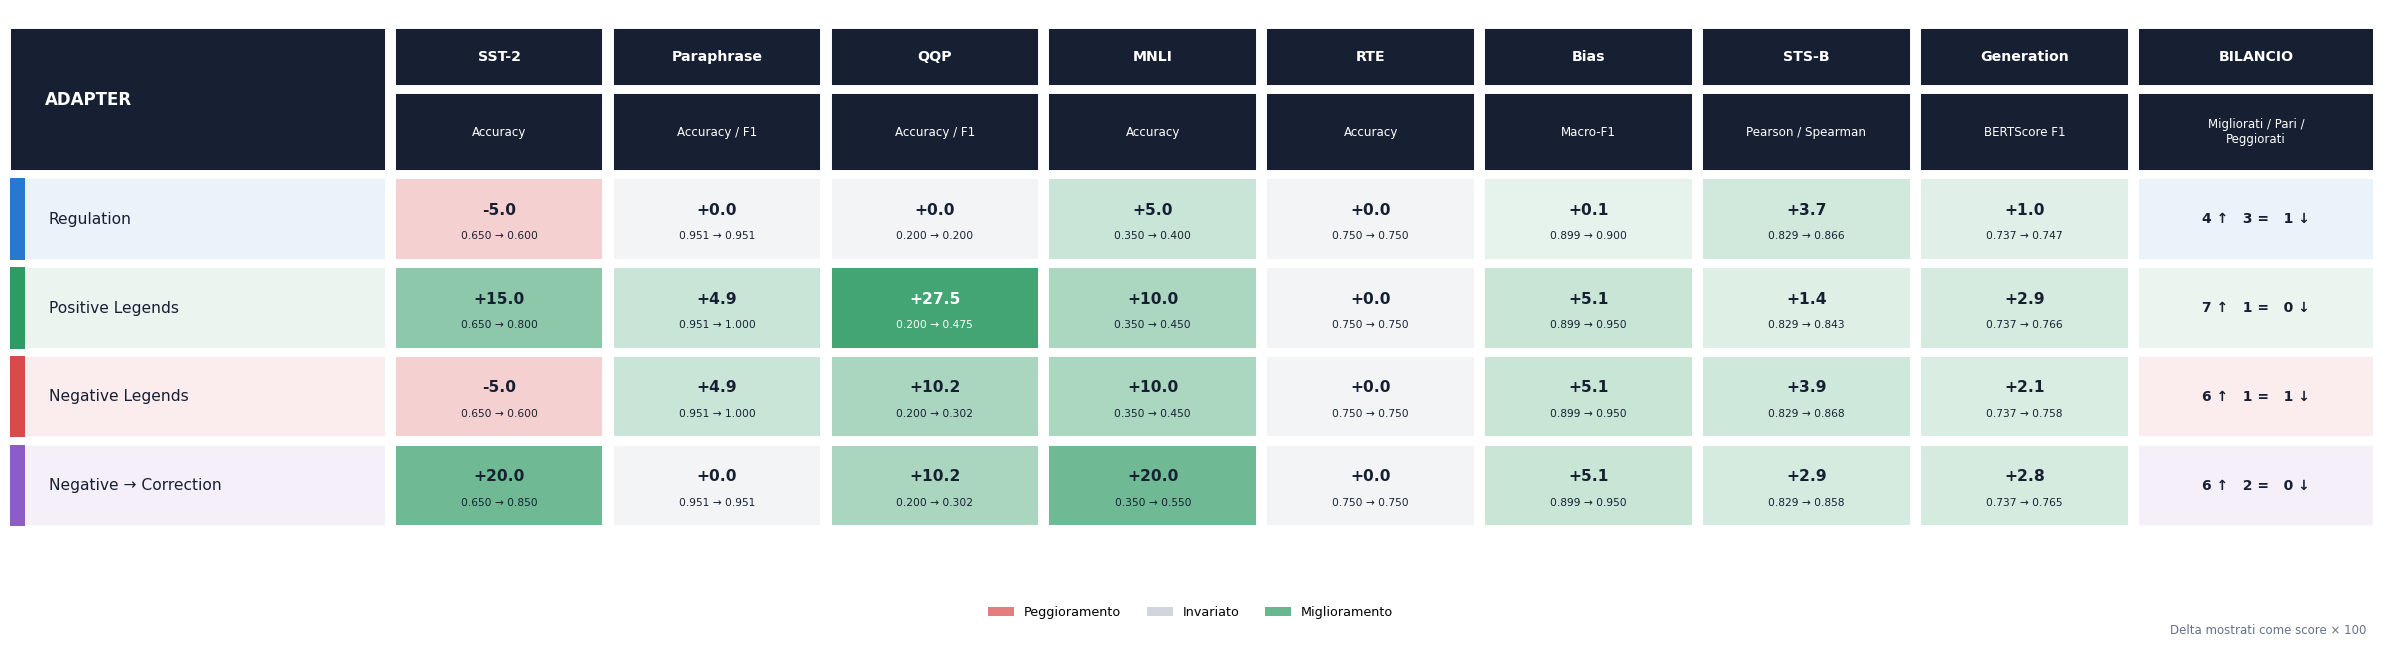

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\01_overview\01_delta_vs_base_heatmap.png


In [94]:
# CELLA 8 — Genera una matrice divergente presentation-grade
# dei delta adapter meno Base sui singoli task.

def plot_delta_heatmap(
    delta_dataframe: pd.DataFrame,
    output_path: Path,
):
    """
    Disegna una heatmap custom.

    Ogni cella contiene:
    - delta × 100;
    - valore Base → valore adapter.
    """

    matrix_dataframe = (
        delta_dataframe
        .reindex(
            index=ADAPTER_MODELS,
            columns=BLOCK_3_TASK_ORDER,
        )
        .copy()
    )


    maximum_absolute_delta = float(
        np.nanmax(
            np.abs(
                matrix_dataframe
                .to_numpy(
                    dtype=float
                )
            )
        )
    )


    # Evita saturazione eccessiva quando
    # tutti i delta sono molto piccoli.
    color_limit = max(
        0.05,
        maximum_absolute_delta,
    )


    number_of_rows = len(
        ADAPTER_MODELS
    )

    number_of_tasks = len(
        BLOCK_3_TASK_ORDER
    )


    # =================================================================
    # DIMENSIONI
    # =================================================================

    model_column_width = 4.15

    task_column_width = 2.35

    balance_column_width = 2.65

    horizontal_gap = 0.10

    vertical_gap = 0.08

    row_height = 0.98

    task_header_height = 0.72

    metric_header_height = 0.94

    header_height = (
        task_header_height
        + metric_header_height
    )

    bottom_margin = 0.55

    top_margin = 0.12


    total_width = (
        model_column_width
        + number_of_tasks
        * task_column_width
        + balance_column_width
    )


    total_height = (
        bottom_margin
        + number_of_rows
        * row_height
        + header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            24.0,
            6.4,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )


    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_rows
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # HEADER ADAPTER
    # =================================================================

    axis.add_patch(
        Rectangle(
            (
                0,
                header_bottom,
            ),

            model_column_width
            - horizontal_gap,

            header_height
            - vertical_gap,

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        0.38,

        header_bottom
        + (
            header_height
            - vertical_gap
        )
        / 2,

        "ADAPTER",

        ha="left",

        va="center",

        fontsize=12,

        fontweight="bold",

        color="white",
    )


    # =================================================================
    # HEADER TASK
    # =================================================================

    for task_index, task_name in enumerate(
        BLOCK_3_TASK_ORDER
    ):
        cell_x = (
            model_column_width
            + task_index
            * task_column_width
        )

        cell_width = (
            task_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                (
                    cell_x,
                    task_header_bottom,
                ),

                cell_width,

                task_header_height
                - vertical_gap,

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            task_header_bottom
            + (
                task_header_height
                - vertical_gap
            )
            / 2,

            TASK_DISPLAY_NAMES[
                task_name
            ],

            ha="center",

            va="center",

            fontsize=10.2,

            fontweight="bold",

            color="white",
        )


        axis.add_patch(
            Rectangle(
                (
                    cell_x,
                    metric_header_bottom,
                ),

                cell_width,

                metric_header_height
                - vertical_gap,

                facecolor=header_color,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            TASK_METRIC_LABELS[
                task_name
            ],

            ha="center",

            va="center",

            fontsize=8.6,

            fontweight="medium",

            color="white",

            wrap=True,
        )


    # =================================================================
    # HEADER BILANCIO
    # =================================================================

    balance_x = (
        model_column_width
        + number_of_tasks
        * task_column_width
    )


    balance_width = (
        balance_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            (
                balance_x,
                task_header_bottom,
            ),

            balance_width,

            task_header_height
            - vertical_gap,

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        balance_x
        + balance_width
        / 2,

        task_header_bottom
        + (
            task_header_height
            - vertical_gap
        )
        / 2,

        "BILANCIO",

        ha="center",

        va="center",

        fontsize=10.2,

        fontweight="bold",

        color="white",
    )


    axis.add_patch(
        Rectangle(
            (
                balance_x,
                metric_header_bottom,
            ),

            balance_width,

            metric_header_height
            - vertical_gap,

            facecolor=header_color,

            edgecolor="white",

            linewidth=1.4,
        )
    )


    axis.text(
        balance_x
        + balance_width
        / 2,

        metric_header_bottom
        + (
            metric_header_height
            - vertical_gap
        )
        / 2,

        "Migliorati / Pari /\nPeggiorati",

        ha="center",

        va="center",

        fontsize=8.5,

        fontweight="medium",

        color="white",
    )


    balance_indexed_df = (
        task_balance_df
        .set_index(
            "adapter_name"
        )
        .reindex(
            ADAPTER_MODELS
        )
    )


    # =================================================================
    # RIGHE DEGLI ADAPTER
    # =================================================================

    for row_index, adapter_name in enumerate(
        ADAPTER_MODELS
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_rows
                - 1
                - row_index
            )
            * row_height
        )


        model_color = (
            MODEL_COLORS[
                adapter_name
            ]
        )


        model_background = blend_colors(
            "#FFFFFF",
            model_color,
            0.10,
        )


        # -------------------------------------------------------------
        # COLONNA ADAPTER
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                (
                    0,
                    row_bottom,
                ),

                model_column_width
                - horizontal_gap,

                row_height
                - vertical_gap,

                facecolor=model_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                (
                    0,
                    row_bottom,
                ),

                0.16,

                row_height
                - vertical_gap,

                facecolor=model_color,

                edgecolor="none",
            )
        )


        axis.text(
            0.42,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                adapter_name
            ],

            ha="left",

            va="center",

            fontsize=11.2,

            fontweight="medium",

            color="#172033",
        )


        # -------------------------------------------------------------
        # CELLE DEI TASK
        # -------------------------------------------------------------

        for task_index, task_name in enumerate(
            BLOCK_3_TASK_ORDER
        ):
            cell_x = (
                model_column_width
                + task_index
                * task_column_width
            )

            cell_width = (
                task_column_width
                - horizontal_gap
            )


            delta_value = float(
                matrix_dataframe.loc[
                    adapter_name,
                    task_name,
                ]
            )


            base_score = float(
                primary_score_matrix_df.loc[
                    BASE_MODEL,
                    task_name,
                ]
            )


            adapter_score = float(
                primary_score_matrix_df.loc[
                    adapter_name,
                    task_name,
                ]
            )


            normalized_strength = min(
                abs(
                    delta_value
                )
                / color_limit,

                1.0,
            )


            if delta_value > PAIR_TOLERANCE:
                semantic_color = (
                    "#2E9B65"
                )

            elif delta_value < -PAIR_TOLERANCE:
                semantic_color = (
                    "#D94A4A"
                )

            else:
                semantic_color = (
                    "#98A2B3"
                )


            cell_facecolor = blend_colors(
                "#FFFFFF",

                semantic_color,

                0.12
                + 0.78
                * normalized_strength,
            )


            axis.add_patch(
                Rectangle(
                    (
                        cell_x,
                        row_bottom,
                    ),

                    cell_width,

                    row_height
                    - vertical_gap,

                    facecolor=cell_facecolor,

                    edgecolor="white",

                    linewidth=1.4,
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                * 0.61,

                format_signed_points(
                    delta_value
                ),

                ha="center",

                va="center",

                fontsize=11.2,

                fontweight="bold",

                color=contrast_text_color(
                    cell_facecolor
                ),
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                * 0.29,

                (
                    f"{base_score:.3f}"
                    f" → "
                    f"{adapter_score:.3f}"
                ),

                ha="center",

                va="center",

                fontsize=7.7,

                color=contrast_text_color(
                    cell_facecolor
                ),
            )


        # -------------------------------------------------------------
        # BILANCIO TASK
        # -------------------------------------------------------------

        balance_row = (
            balance_indexed_df.loc[
                adapter_name
            ]
        )


        balance_background = blend_colors(
            "#FFFFFF",

            model_color,

            0.10,
        )


        axis.add_patch(
            Rectangle(
                (
                    balance_x,
                    row_bottom,
                ),

                balance_width,

                row_height
                - vertical_gap,

                facecolor=balance_background,

                edgecolor="white",

                linewidth=1.4,
            )
        )


        axis.text(
            balance_x
            + balance_width
            / 2,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            (
                f"{int(balance_row['improved'])} ↑   "
                f"{int(balance_row['tied'])} =   "
                f"{int(balance_row['worsened'])} ↓"
            ),

            ha="center",

            va="center",

            fontsize=10.0,

            fontweight="bold",

            color="#172033",
        )


    # =================================================================
    # LEGENDA
    # =================================================================

    legend_handles = [
        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#D94A4A",
                0.72,
            ),
            edgecolor="none",
            label="Peggioramento",
        ),

        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#98A2B3",
                0.45,
            ),
            edgecolor="none",
            label="Invariato",
        ),

        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#2E9B65",
                0.72,
            ),
            edgecolor="none",
            label="Miglioramento",
        ),
    ]


    figure.legend(
        handles=legend_handles,

        loc="lower center",

        bbox_to_anchor=(
            0.5,
            0.015,
        ),

        ncol=3,

        frameon=False,

        fontsize=9.2,

        columnspacing=2.0,
    )


    figure.text(
        0.99,
        0.015,

        "Delta mostrati come score × 100",

        ha="right",

        va="center",

        fontsize=8.5,

        color="#667085",
    )


    figure.subplots_adjust(
        left=0.008,
        right=0.997,
        top=0.985,
        bottom=0.10,
    )


    save_figure(
        figure,
        output_path,
    )


plot_delta_heatmap(
    delta_matrix_df,

    OVERVIEW_PLOTS_DIR
    / "01_delta_vs_base_heatmap.png",
)

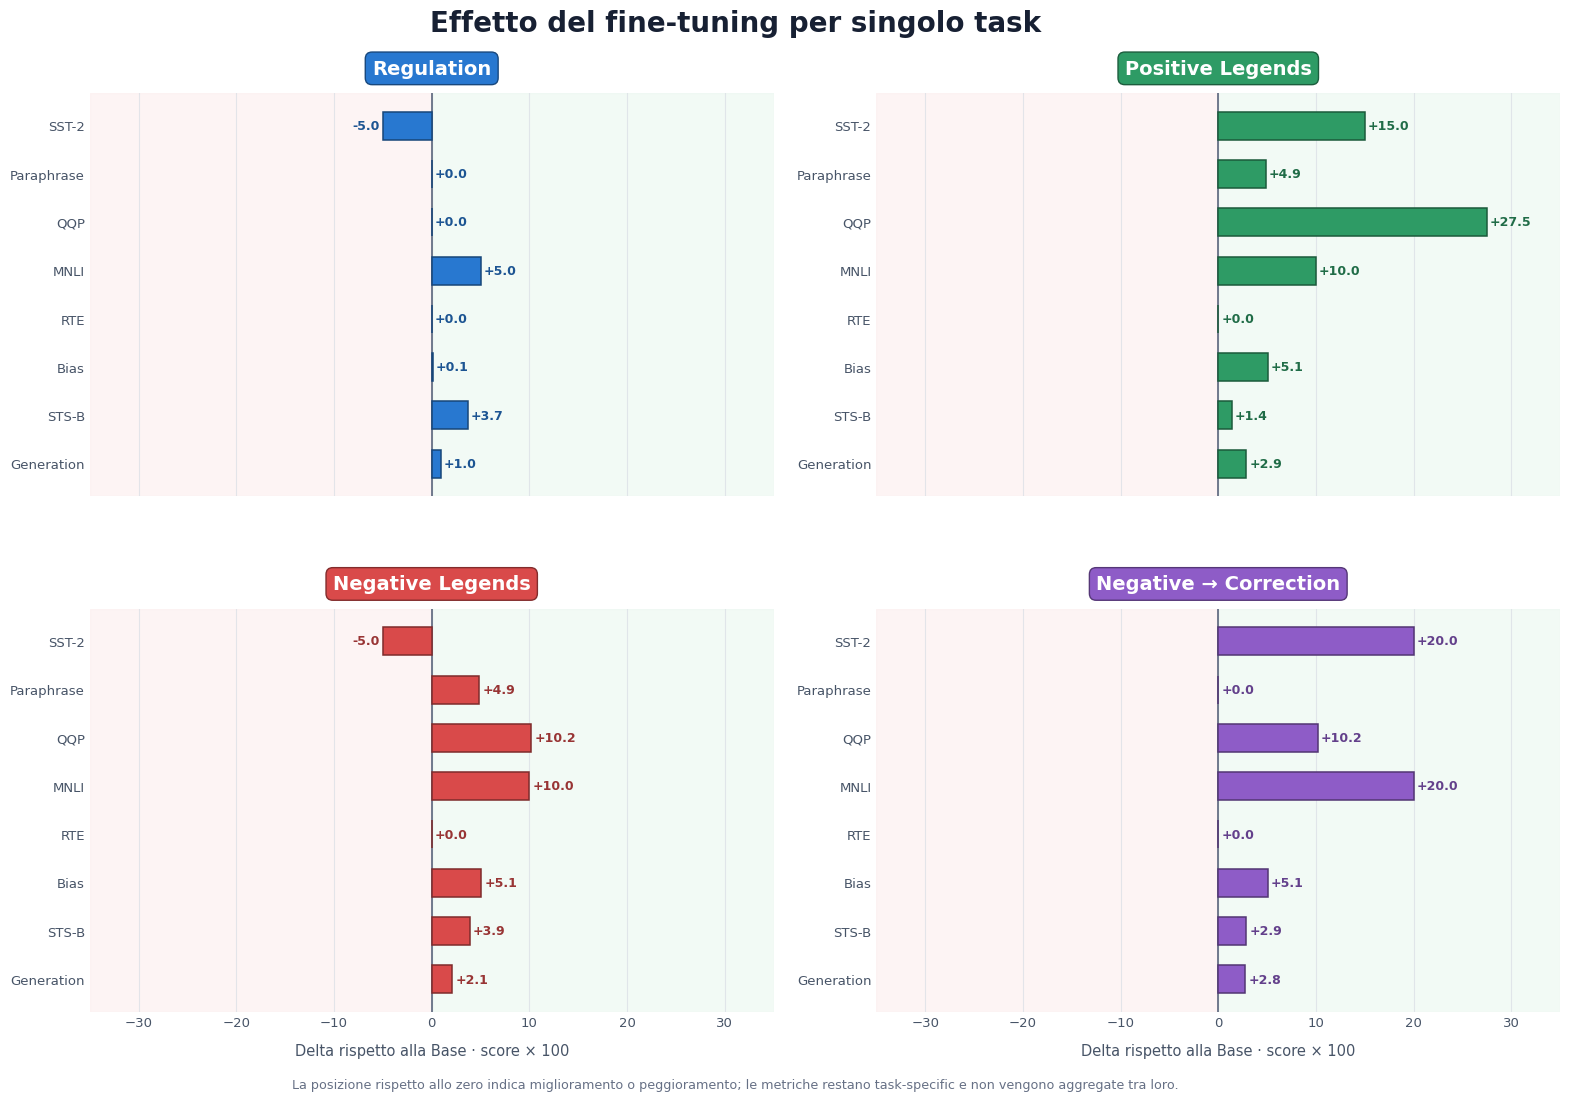

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\01_overview\02_delta_vs_base_profiles.png


In [95]:
# CELLA 9 — Genera l'alternativa alla heatmap:
# quattro profili divergenti, uno per adapter, sui singoli task.

maximum_delta_points = float(
    np.nanmax(
        np.abs(
            delta_matrix_df
            .to_numpy(
                dtype=float
            )
            * 100.0
        )
    )
)


x_axis_limit = max(
    5.0,

    np.ceil(
        maximum_delta_points
        * 1.25
    ),
)


figure, axes = plt.subplots(
    nrows=2,
    ncols=2,

    figsize=(
        17.0,
        11.2,
    ),

    sharex=True,
)


figure.patch.set_facecolor(
    "white"
)


axes = axes.flatten()


y_positions = np.arange(
    len(
        BLOCK_3_TASK_ORDER
    )
)


for axis, adapter_name in zip(
    axes,
    ADAPTER_MODELS,
):
    adapter_deltas = (
        delta_matrix_df.loc[
            adapter_name
        ]
        .reindex(
            BLOCK_3_TASK_ORDER
        )
        .to_numpy(
            dtype=float
        )
        * 100.0
    )


    model_color = (
        MODEL_COLORS[
            adapter_name
        ]
    )


    # Area di peggioramento.
    axis.axvspan(
        -x_axis_limit,
        0,

        color="#FCEEEE",

        alpha=0.62,

        zorder=0,
    )


    # Area di miglioramento.
    axis.axvspan(
        0,
        x_axis_limit,

        color="#EAF7F0",

        alpha=0.62,

        zorder=0,
    )


    bars = axis.barh(
        y_positions,

        adapter_deltas,

        height=0.58,

        color=model_color,

        edgecolor=darken_color(
            model_color,
            0.42,
        ),

        linewidth=1.1,

        zorder=3,
    )


    axis.axvline(
        0,

        color="#667085",

        linewidth=1.3,

        zorder=2,
    )


    for bar, delta_points in zip(
        bars,
        adapter_deltas,
    ):
        horizontal_offset = (
            0.30
            if delta_points >= 0
            else -0.30
        )


        axis.text(
            delta_points
            + horizontal_offset,

            bar.get_y()
            + bar.get_height()
            / 2,

            f"{delta_points:+.1f}",

            ha=(
                "left"
                if delta_points >= 0
                else "right"
            ),

            va="center",

            fontsize=9.0,

            fontweight="bold",

            color=darken_color(
                model_color,
                0.30,
            ),

            zorder=5,
        )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        [
            TASK_DISPLAY_NAMES[
                task_name
            ]
            for task_name
            in BLOCK_3_TASK_ORDER
        ]
    )


    axis.invert_yaxis()


    axis.set_xlim(
        -x_axis_limit,
        x_axis_limit,
    )


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],

        fontsize=14,

        fontweight="bold",

        color="white",

        pad=14,

        bbox={
            "boxstyle": (
                "round,pad=0.35"
            ),

            "facecolor": model_color,

            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


for axis in axes[
    2:
]:
    axis.set_xlabel(
        "Delta rispetto alla Base · score × 100",

        fontsize=10.5,

        fontweight="medium",

        color="#475467",

        labelpad=10,
    )


figure.suptitle(
    "Effetto del fine-tuning per singolo task",

    fontsize=20,

    fontweight="bold",

    color="#172033",

    y=0.985,
)


figure.text(
    0.5,
    0.025,

    (
        "La posizione rispetto allo zero indica miglioramento "
        "o peggioramento; le metriche restano task-specific "
        "e non vengono aggregate tra loro."
    ),

    ha="center",

    va="center",

    fontsize=9.2,

    color="#667085",
)


figure.subplots_adjust(
    left=0.12,
    right=0.985,
    top=0.91,
    bottom=0.09,
    hspace=0.28,
    wspace=0.15,
)


save_figure(
    figure,

    OVERVIEW_PLOTS_DIR
    / "02_delta_vs_base_profiles.png",
)

## 2. Gains, regressions e beneficio netto nella classificazione

Il confronto viene effettuato tra ciascun adapter e il modello Base sugli stessi 120 esempi classificatori.

Per ogni esempio sono possibili quattro casi:

| Base | Adapter | Categoria |
|---|---|---|
| Corretta | Corretta | Shared correct |
| Errata | Corretta | Gain |
| Corretta | Errata | Regression |
| Errata | Errata | Shared error |

Il beneficio netto è definito come:

\[
\text{Net gain} = \text{Gains} - \text{Regressions}
\]

Un net gain positivo indica che l'adapter corregge più risposte di quante ne comprometta.

L'analisi viene svolta prima sui 120 esempi aggregati e successivamente sui singoli task classificatori.

In [96]:
# CELLA 11 — Costruisce il confronto appaiato tra Base e adapter
# sui 120 esempi classificatori.
#
# Per ogni esempio identifica:
# - shared_correct;
# - gain;
# - regression;
# - shared_error.
#
# Produce:
# - dataframe a livello di esempio;
# - sintesi aggregata per adapter;
# - sintesi per adapter e task.

# =====================================================================
# PREPARAZIONE DELLE PREDIZIONI DELLA BASE
# =====================================================================

base_classification_df = (
    classification_results_df[
        classification_results_df[
            "model_name"
        ]
        == BASE_MODEL
    ][
        [
            "task_name",
            "example_id",
            "y_true",
            "y_pred",
            "is_correct",
        ]
    ]
    .copy()
    .rename(
        columns={
            "y_true": "base_y_true",
            "y_pred": "base_y_pred",
            "is_correct": "base_is_correct",
        }
    )
)


if len(
    base_classification_df
) != (
    len(
        CLASSIFICATION_TASKS
    )
    * EXPECTED_EXAMPLES_PER_TASK
):
    raise RuntimeError(
        "Il modello Base non contiene i 120 esempi "
        "classificatori attesi."
    )


# =====================================================================
# CONFRONTO BASE-ADAPTER
# =====================================================================

classification_pairwise_frames = []


for adapter_name in ADAPTER_MODELS:

    adapter_classification_df = (
        classification_results_df[
            classification_results_df[
                "model_name"
            ]
            == adapter_name
        ][
            [
                "task_name",
                "example_id",
                "y_true",
                "y_pred",
                "is_correct",
            ]
        ]
        .copy()
        .rename(
            columns={
                "y_true": "adapter_y_true",
                "y_pred": "adapter_y_pred",
                "is_correct": "adapter_is_correct",
            }
        )
    )


    paired_adapter_df = base_classification_df.merge(
        adapter_classification_df,
        on=[
            "task_name",
            "example_id",
        ],
        how="outer",
        validate="one_to_one",
        indicator=True,
    )


    unmatched_rows = (
        paired_adapter_df[
            "_merge"
        ]
        != "both"
    )


    if unmatched_rows.any():
        raise RuntimeError(
            f"Il confronto Base-{adapter_name} contiene "
            "example_id non appaiati."
        )


    paired_adapter_df = paired_adapter_df.drop(
        columns="_merge"
    )


    inconsistent_references = (
        paired_adapter_df[
            "base_y_true"
        ]
        != paired_adapter_df[
            "adapter_y_true"
        ]
    )


    if inconsistent_references.any():
        inconsistent_examples = (
            paired_adapter_df.loc[
                inconsistent_references,
                [
                    "task_name",
                    "example_id",
                    "base_y_true",
                    "adapter_y_true",
                ],
            ]
        )

        raise RuntimeError(
            f"Reference incoerenti nel confronto Base-{adapter_name}:\n"
            + inconsistent_examples.to_string(
                index=False
            )
        )


    paired_adapter_df[
        "adapter_name"
    ] = adapter_name


    paired_adapter_df[
        "y_true"
    ] = paired_adapter_df[
        "base_y_true"
    ]


    # =================================================================
    # CLASSIFICAZIONE DELL'ESITO
    # =================================================================

    paired_adapter_df[
        "comparison_outcome"
    ] = np.select(
        [
            (
                paired_adapter_df[
                    "base_is_correct"
                ]
                & paired_adapter_df[
                    "adapter_is_correct"
                ]
            ),

            (
                ~paired_adapter_df[
                    "base_is_correct"
                ]
                & paired_adapter_df[
                    "adapter_is_correct"
                ]
            ),

            (
                paired_adapter_df[
                    "base_is_correct"
                ]
                & ~paired_adapter_df[
                    "adapter_is_correct"
                ]
            ),

            (
                ~paired_adapter_df[
                    "base_is_correct"
                ]
                & ~paired_adapter_df[
                    "adapter_is_correct"
                ]
            ),
        ],

        [
            "shared_correct",
            "gain",
            "regression",
            "shared_error",
        ],

        default="unexpected",
    )


    unexpected_outcomes = (
        paired_adapter_df[
            "comparison_outcome"
        ]
        == "unexpected"
    )


    if unexpected_outcomes.any():
        raise RuntimeError(
            f"Esiti non classificati per {adapter_name}."
        )


    # Indica se l'adapter ha modificato materialmente la label predetta.
    paired_adapter_df[
        "prediction_changed"
    ] = (
        paired_adapter_df[
            "base_y_pred"
        ]
        != paired_adapter_df[
            "adapter_y_pred"
        ]
    )


    # Transizioni utili nelle celle successive.
    paired_adapter_df[
        "base_error_transition"
    ] = (
        paired_adapter_df[
            "y_true"
        ]
        + " ← "
        + paired_adapter_df[
            "base_y_pred"
        ]
    )


    paired_adapter_df[
        "adapter_error_transition"
    ] = (
        paired_adapter_df[
            "y_true"
        ]
        + " ← "
        + paired_adapter_df[
            "adapter_y_pred"
        ]
    )


    classification_pairwise_frames.append(
        paired_adapter_df[
            [
                "adapter_name",
                "task_name",
                "example_id",
                "y_true",
                "base_y_pred",
                "adapter_y_pred",
                "base_is_correct",
                "adapter_is_correct",
                "comparison_outcome",
                "prediction_changed",
                "base_error_transition",
                "adapter_error_transition",
            ]
        ]
    )


classification_pairwise_df = pd.concat(
    classification_pairwise_frames,
    ignore_index=True,
)


# =====================================================================
# VALIDAZIONE DEL NUMERO DI ESEMPI
# =====================================================================

paired_counts = (
    classification_pairwise_df
    .groupby(
        "adapter_name"
    )
    .size()
    .reindex(
        ADAPTER_MODELS
    )
)


expected_classification_total = (
    len(
        CLASSIFICATION_TASKS
    )
    * EXPECTED_EXAMPLES_PER_TASK
)


if not (
    paired_counts
    == expected_classification_total
).all():
    raise RuntimeError(
        "Il confronto appaiato non contiene 120 esempi "
        "per ciascun adapter:\n"
        + paired_counts.to_string()
    )


# =====================================================================
# FUNZIONE DI SINTESI
# =====================================================================

def summarize_classification_effect(
    dataframe: pd.DataFrame,
    grouping_columns: list[str],
) -> pd.DataFrame:
    """
    Calcola gains, regressions, shared correct,
    shared error e net gain.
    """

    outcome_order = [
        "shared_correct",
        "gain",
        "regression",
        "shared_error",
    ]


    summary_dataframe = (
        dataframe
        .groupby(
            grouping_columns
            + [
                "comparison_outcome"
            ]
        )
        .size()
        .unstack(
            fill_value=0
        )
        .reindex(
            columns=outcome_order,
            fill_value=0,
        )
        .reset_index()
    )


    summary_dataframe[
        "base_correct"
    ] = (
        summary_dataframe[
            "shared_correct"
        ]
        + summary_dataframe[
            "regression"
        ]
    )


    summary_dataframe[
        "adapter_correct"
    ] = (
        summary_dataframe[
            "shared_correct"
        ]
        + summary_dataframe[
            "gain"
        ]
    )


    summary_dataframe[
        "net_gain"
    ] = (
        summary_dataframe[
            "gain"
        ]
        - summary_dataframe[
            "regression"
        ]
    )


    summary_dataframe[
        "changed_correctness"
    ] = (
        summary_dataframe[
            "gain"
        ]
        + summary_dataframe[
            "regression"
        ]
    )


    summary_dataframe[
        "total_examples"
    ] = (
        summary_dataframe[
            outcome_order
        ]
        .sum(
            axis=1
        )
    )


    summary_dataframe[
        "base_accuracy"
    ] = (
        summary_dataframe[
            "base_correct"
        ]
        / summary_dataframe[
            "total_examples"
        ]
    )


    summary_dataframe[
        "adapter_accuracy"
    ] = (
        summary_dataframe[
            "adapter_correct"
        ]
        / summary_dataframe[
            "total_examples"
        ]
    )


    summary_dataframe[
        "accuracy_delta"
    ] = (
        summary_dataframe[
            "adapter_accuracy"
        ]
        - summary_dataframe[
            "base_accuracy"
        ]
    )


    return summary_dataframe


# =====================================================================
# SINTESI AGGREGATA SUI 120 ESEMPI
# =====================================================================

classification_aggregate_effect_df = (
    summarize_classification_effect(
        dataframe=classification_pairwise_df,
        grouping_columns=[
            "adapter_name"
        ],
    )
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


# =====================================================================
# SINTESI PER SINGOLO TASK
# =====================================================================

classification_task_effect_df = (
    summarize_classification_effect(
        dataframe=classification_pairwise_df,
        grouping_columns=[
            "adapter_name",
            "task_name",
        ],
    )
)


expected_task_effect_index = pd.MultiIndex.from_product(
    [
        ADAPTER_MODELS,
        CLASSIFICATION_TASKS,
    ],
    names=[
        "adapter_name",
        "task_name",
    ],
)


classification_task_effect_df = (
    classification_task_effect_df
    .set_index(
        [
            "adapter_name",
            "task_name",
        ]
    )
    .reindex(
        expected_task_effect_index
    )
    .reset_index()
)


if classification_task_effect_df.isna().any().any():
    raise RuntimeError(
        "La sintesi classificatoria task-level "
        "contiene valori mancanti."
    )


# =====================================================================
# ESPORTAZIONE
# =====================================================================

classification_pairwise_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_pairwise_vs_base.csv",
    index=False,
    encoding="utf-8-sig",
)


classification_aggregate_effect_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_effect_aggregate.csv",
    index=False,
    encoding="utf-8-sig",
)


classification_task_effect_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_effect_by_task.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    classification_aggregate_effect_df[
        [
            "adapter_name",
            "shared_correct",
            "gain",
            "regression",
            "shared_error",
            "net_gain",
            "base_accuracy",
            "adapter_accuracy",
            "accuracy_delta",
        ]
    ].round(
        4
    )
)


display(
    classification_task_effect_df[
        [
            "adapter_name",
            "task_name",
            "gain",
            "regression",
            "net_gain",
            "base_accuracy",
            "adapter_accuracy",
        ]
    ].round(
        4
    )
)

comparison_outcome,adapter_name,shared_correct,gain,regression,shared_error,net_gain,base_accuracy,adapter_accuracy,accuracy_delta
0,regulation,77,3,3,37,0,0.6667,0.6667,0.0000
1,positive_legends,79,11,1,29,10,0.6667,0.7500,0.0833
2,negative_legends,78,6,2,34,4,0.6667,0.7000,0.0333
3,negative_to_correction,79,11,1,29,10,0.6667,0.7500,0.0833


comparison_outcome,adapter_name,task_name,gain,regression,net_gain,base_accuracy,adapter_accuracy
0,regulation,sst2_style,0,1,-1,0.65,0.60
1,regulation,paraphrase_style,1,1,0,0.95,0.95
2,regulation,qqp_style,0,0,0,0.40,0.40
3,regulation,mnli_style,1,0,1,0.35,0.40
4,regulation,rte_style,0,0,0,0.75,0.75
5,regulation,bias_detection,1,1,0,0.90,0.90
6,positive_legends,sst2_style,3,0,3,0.65,0.80
7,positive_legends,paraphrase_style,1,0,1,0.95,1.00
8,positive_legends,qqp_style,3,0,3,0.40,0.55
9,positive_legends,mnli_style,2,0,2,0.35,0.45


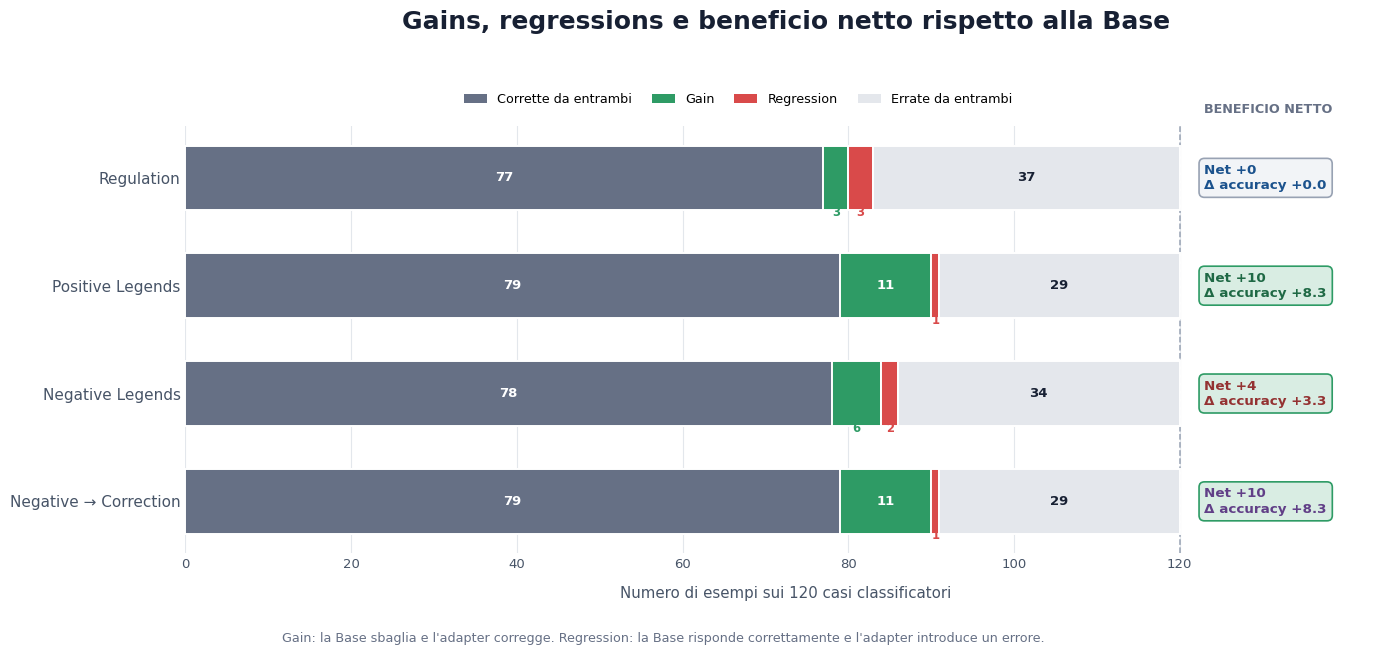

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\02_classification\01_classification_gain_regression_aggregate.png


In [97]:
# CELLA 12 — Visualizza l'effetto aggregato del fine-tuning
# sui 120 esempi classificatori.
#
# Ogni barra contiene:
# - shared correct;
# - gains;
# - regressions;
# - shared errors.
#
# A destra viene mostrato il net gain
# e la corrispondente variazione dell'accuracy.

aggregate_plot_df = (
    classification_aggregate_effect_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


# =====================================================================
# COLORI SEMANTICI
# =====================================================================

CLASSIFICATION_EFFECT_COLORS = {
    "shared_correct": "#667085",
    "gain": "#2E9B65",
    "regression": "#D94A4A",
    "shared_error": "#E4E7EC",
}


CLASSIFICATION_EFFECT_TEXT_COLORS = {
    "shared_correct": "white",
    "gain": "white",
    "regression": "white",
    "shared_error": "#172033",
}


CLASSIFICATION_EFFECT_LABELS = {
    "shared_correct": "Corrette da entrambi",
    "gain": "Gain",
    "regression": "Regression",
    "shared_error": "Errate da entrambi",
}


effect_columns = [
    "shared_correct",
    "gain",
    "regression",
    "shared_error",
]


# =====================================================================
# FIGURA
# =====================================================================

figure, axis = plt.subplots(
    figsize=(
        15.4,
        7.0,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


y_positions = np.arange(
    len(
        ADAPTER_MODELS
    )
)


left_values = np.zeros(
    len(
        ADAPTER_MODELS
    ),
    dtype=float,
)


# =====================================================================
# BARRE STACKED
# =====================================================================

for effect_column in effect_columns:

    effect_values = (
        aggregate_plot_df[
            effect_column
        ]
        .to_numpy(
            dtype=float
        )
    )


    bars = axis.barh(
        y_positions,
        effect_values,
        left=left_values,
        height=0.60,
        color=CLASSIFICATION_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="white",
        linewidth=1.4,
        zorder=3,
    )


    for (
        bar,
        effect_value,
        left_value,
    ) in zip(
        bars,
        effect_values,
        left_values,
    ):

        if effect_value <= 0:
            continue


        # I segmenti molto piccoli vengono etichettati
        # sopra la barra per evitare sovrapposizioni.
        if effect_value >= 8:

            axis.text(
                left_value
                + effect_value
                / 2,
                bar.get_y()
                + bar.get_height()
                / 2,
                str(
                    int(
                        effect_value
                    )
                ),
                ha="center",
                va="center",
                fontsize=9.5,
                fontweight="bold",
                color=CLASSIFICATION_EFFECT_TEXT_COLORS[
                    effect_column
                ],
                zorder=5,
            )

        else:

            axis.text(
                left_value
                + effect_value
                / 2,
                bar.get_y()
                + bar.get_height()
                + 0.08,
                str(
                    int(
                        effect_value
                    )
                ),
                ha="center",
                va="bottom",
                fontsize=8.4,
                fontweight="bold",
                color=CLASSIFICATION_EFFECT_COLORS[
                    effect_column
                ],
                zorder=5,
            )


    left_values += effect_values


# =====================================================================
# NET GAIN E DELTA ACCURACY
# =====================================================================

for row_index, row in aggregate_plot_df.iterrows():

    adapter_name = row[
        "adapter_name"
    ]


    net_gain = int(
        row[
            "net_gain"
        ]
    )


    accuracy_delta = float(
        row[
            "accuracy_delta"
        ]
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    if net_gain > 0:
        net_gain_background = blend_colors(
            "#FFFFFF",
            "#2E9B65",
            0.18,
        )

        net_gain_edge = "#2E9B65"

    elif net_gain < 0:
        net_gain_background = blend_colors(
            "#FFFFFF",
            "#D94A4A",
            0.18,
        )

        net_gain_edge = "#D94A4A"

    else:
        net_gain_background = "#F2F4F7"
        net_gain_edge = "#98A2B3"


    axis.text(
        123.0,
        row_index,
        (
            f"Net {net_gain:+d}\n"
            f"Δ accuracy {accuracy_delta * 100:+.1f}"
        ),
        ha="left",
        va="center",
        fontsize=9.7,
        fontweight="bold",
        color=darken_color(
            model_color,
            0.32,
        ),
        linespacing=1.22,
        bbox={
            "boxstyle": "round,pad=0.40",
            "facecolor": net_gain_background,
            "edgecolor": net_gain_edge,
            "linewidth": 1.2,
        },
        zorder=6,
    )


# =====================================================================
# ASSI
# =====================================================================

axis.set_yticks(
    y_positions
)


axis.set_yticklabels(
    [
        MODEL_DISPLAY_NAMES[
            adapter_name
        ]
        for adapter_name
        in ADAPTER_MODELS
    ],
    fontsize=11,
    fontweight="medium",
    color="#172033",
)


axis.invert_yaxis()


axis.set_xlim(
    0,
    145,
)


axis.set_xticks(
    [
        0,
        20,
        40,
        60,
        80,
        100,
        120,
    ]
)


axis.set_xlabel(
    "Numero di esempi sui 120 casi classificatori",
    fontsize=10.8,
    fontweight="medium",
    color="#475467",
    labelpad=11,
)


axis.axvline(
    120,
    color="#98A2B3",
    linewidth=1.1,
    linestyle="--",
    zorder=1,
)


axis.text(
    123.0,
    1.025,
    "BENEFICIO NETTO",
    transform=axis.get_xaxis_transform(),
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold",
    color="#667085",
    clip_on=False,
)


axis.set_title(
    "Gains, regressions e beneficio netto rispetto alla Base",
    fontsize=18,
    fontweight="bold",
    color="#172033",
    pad=70,
)


axis.grid(
    axis="x",
    color="#D9DEE5",
    linewidth=0.8,
    alpha=0.72,
)


axis.set_axisbelow(
    True
)


axis.tick_params(
    axis="both",
    length=0,
    colors="#475467",
)


for spine in axis.spines.values():
    spine.set_visible(
        False
    )


# =====================================================================
# LEGENDA
# =====================================================================

legend_handles = [
    Patch(
        facecolor=CLASSIFICATION_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="none",
        label=CLASSIFICATION_EFFECT_LABELS[
            effect_column
        ],
    )
    for effect_column in effect_columns
]


axis.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.46,
        1.105,
    ),
    ncol=4,
    frameon=False,
    fontsize=9.2,
    columnspacing=1.55,
    handlelength=1.8,
)


figure.text(
    0.5,
    0.028,
    (
        "Gain: la Base sbaglia e l'adapter corregge. "
        "Regression: la Base risponde correttamente "
        "e l'adapter introduce un errore."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.76,
    bottom=0.15,
)


save_figure(
    figure,
    CLASSIFICATION_PLOTS_DIR
    / "01_classification_gain_regression_aggregate.png",
)

## 3. Gains e regressions per singolo task classificatorio

Il risultato aggregato può nascondere comportamenti molto differenti.

Per questo motivo gains e regressions vengono analizzati separatamente per:

- SST-2;
- Paraphrase;
- QQP;
- MNLI;
- RTE;
- Bias Detection.

Per ogni coppia adapter-task vengono riportati:

- numero di gains;
- numero di regressions;
- net gain;
- variazione dell'accuracy.

Due adapter possono avere lo stesso net gain, ma comportamenti molto diversi.

Esempio:

- 2 gains e 0 regressions: miglioramento stabile;
- 8 gains e 6 regressions: stesso saldo, ma comportamento molto più instabile.

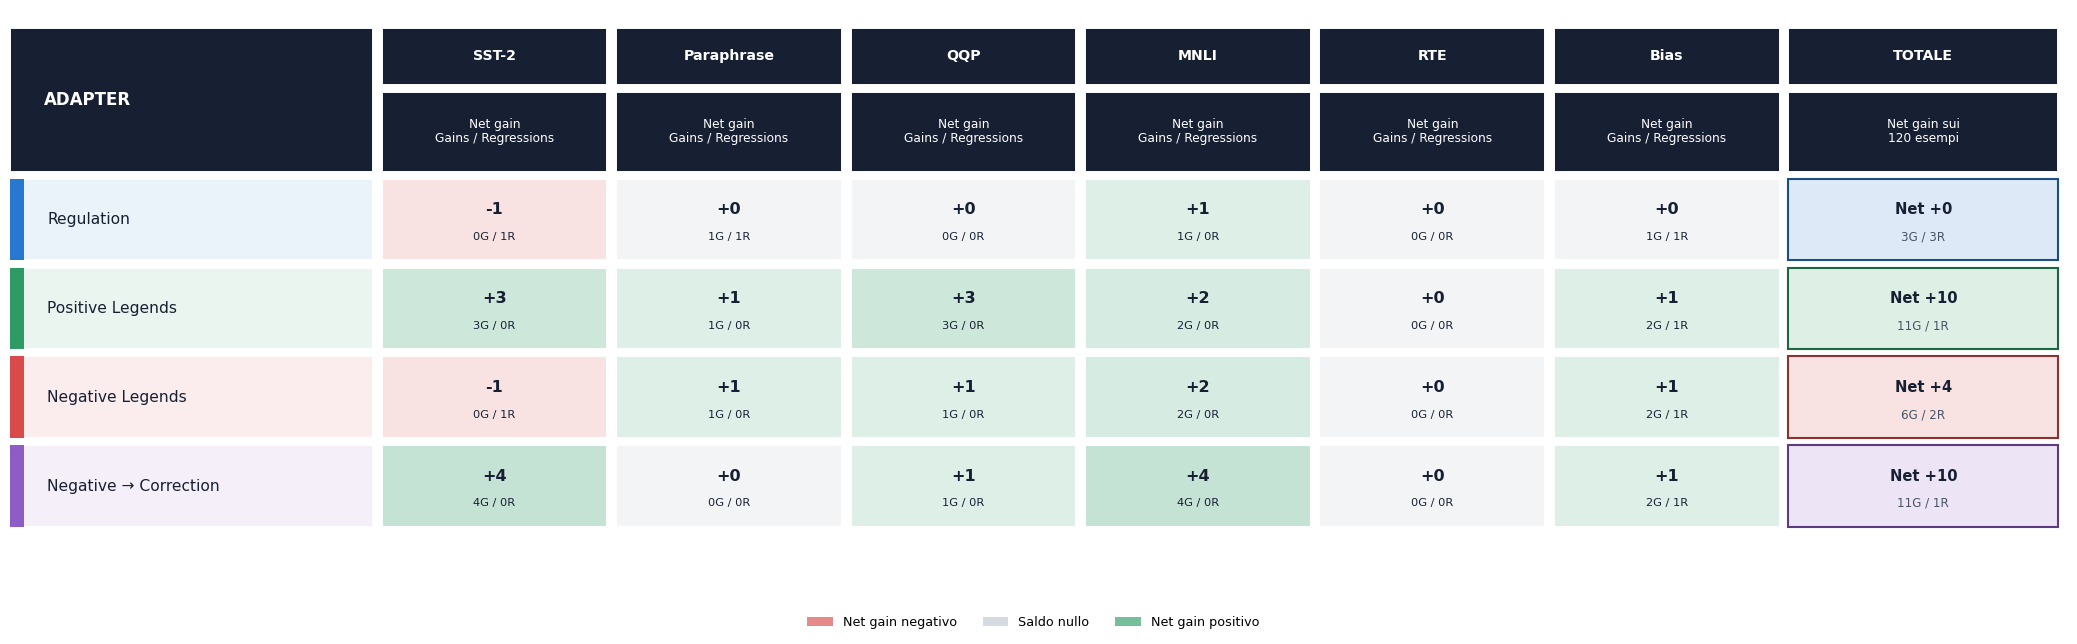

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\02_classification\02_classification_net_gain_matrix.png


In [98]:
# CELLA 14 — Matrice custom di gains, regressions e net gain
# per ciascun task classificatorio.
#
# Ogni cella mostra:
# - net gain;
# - numero di gains e regressions.
#
# Colore:
# - verde = net gain positivo;
# - rosso = net gain negativo;
# - grigio = saldo nullo.

def plot_classification_task_effect_matrix(
    dataframe: pd.DataFrame,
    output_path: Path,
):
    """
    Disegna una matrice task-level del beneficio netto.
    """

    indexed_dataframe = (
        dataframe
        .set_index(
            [
                "adapter_name",
                "task_name",
            ]
        )
        .reindex(
            pd.MultiIndex.from_product(
                [
                    ADAPTER_MODELS,
                    CLASSIFICATION_TASKS,
                ],
                names=[
                    "adapter_name",
                    "task_name",
                ],
            )
        )
    )


    if indexed_dataframe.isna().any().any():
        raise RuntimeError(
            "La matrice task-level contiene valori mancanti."
        )


    number_of_adapters = len(
        ADAPTER_MODELS
    )


    number_of_tasks = len(
        CLASSIFICATION_TASKS
    )


    # Il range teorico del net gain per task è -20 / +20.
    absolute_net_gain_limit = float(
        EXPECTED_EXAMPLES_PER_TASK
    )


    # =================================================================
    # DIMENSIONI
    # =================================================================

    adapter_column_width = 4.20

    task_column_width = 2.65

    total_column_width = 3.15

    horizontal_gap = 0.10
    vertical_gap = 0.08

    row_height = 1.00

    task_header_height = 0.72
    metric_header_height = 0.98

    complete_header_height = (
        task_header_height
        + metric_header_height
    )

    bottom_margin = 0.58
    top_margin = 0.12


    total_width = (
        adapter_column_width
        + number_of_tasks
        * task_column_width
        + total_column_width
    )


    total_height = (
        bottom_margin
        + number_of_adapters
        * row_height
        + complete_header_height
        + top_margin
    )


    figure, axis = plt.subplots(
        figsize=(
            20.8,
            6.5,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )


    axis.set_facecolor(
        "white"
    )


    axis.set_xlim(
        0,
        total_width,
    )


    axis.set_ylim(
        0,
        total_height,
    )


    axis.axis(
        "off"
    )


    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_adapters
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # =================================================================
    # HEADER ADAPTER
    # =================================================================

    axis.add_patch(
        Rectangle(
            (
                0,
                header_bottom,
            ),
            adapter_column_width
            - horizontal_gap,
            complete_header_height
            - vertical_gap,
            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        0.38,
        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,
        "ADAPTER",
        ha="left",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white",
    )


    # =================================================================
    # HEADER TASK
    # =================================================================

    for task_index, task_name in enumerate(
        CLASSIFICATION_TASKS
    ):

        cell_x = (
            adapter_column_width
            + task_index
            * task_column_width
        )


        cell_width = (
            task_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                (
                    cell_x,
                    task_header_bottom,
                ),
                cell_width,
                task_header_height
                - vertical_gap,
                facecolor=header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,
            task_header_bottom
            + (
                task_header_height
                - vertical_gap
            )
            / 2,
            TASK_DISPLAY_NAMES[
                task_name
            ],
            ha="center",
            va="center",
            fontsize=10.2,
            fontweight="bold",
            color="white",
        )


        axis.add_patch(
            Rectangle(
                (
                    cell_x,
                    metric_header_bottom,
                ),
                cell_width,
                metric_header_height
                - vertical_gap,
                facecolor=header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,
            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,
            "Net gain\nGains / Regressions",
            ha="center",
            va="center",
            fontsize=8.7,
            fontweight="medium",
            color="white",
            linespacing=1.10,
        )


    # =================================================================
    # HEADER TOTALE
    # =================================================================

    total_column_x = (
        adapter_column_width
        + number_of_tasks
        * task_column_width
    )


    total_cell_width = (
        total_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            (
                total_column_x,
                task_header_bottom,
            ),
            total_cell_width,
            task_header_height
            - vertical_gap,
            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        total_column_x
        + total_cell_width
        / 2,
        task_header_bottom
        + (
            task_header_height
            - vertical_gap
        )
        / 2,
        "TOTALE",
        ha="center",
        va="center",
        fontsize=10.2,
        fontweight="bold",
        color="white",
    )


    axis.add_patch(
        Rectangle(
            (
                total_column_x,
                metric_header_bottom,
            ),
            total_cell_width,
            metric_header_height
            - vertical_gap,
            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        total_column_x
        + total_cell_width
        / 2,
        metric_header_bottom
        + (
            metric_header_height
            - vertical_gap
        )
        / 2,
        "Net gain sui\n120 esempi",
        ha="center",
        va="center",
        fontsize=8.7,
        fontweight="medium",
        color="white",
        linespacing=1.10,
    )


    aggregate_indexed_df = (
        classification_aggregate_effect_df
        .set_index(
            "adapter_name"
        )
        .reindex(
            ADAPTER_MODELS
        )
    )


    # =================================================================
    # RIGHE
    # =================================================================

    for row_index, adapter_name in enumerate(
        ADAPTER_MODELS
    ):

        row_bottom = (
            rows_bottom
            + (
                number_of_adapters
                - 1
                - row_index
            )
            * row_height
        )


        model_color = MODEL_COLORS[
            adapter_name
        ]


        model_background = blend_colors(
            "#FFFFFF",
            model_color,
            0.10,
        )


        # -------------------------------------------------------------
        # CELLA ADAPTER
        # -------------------------------------------------------------

        axis.add_patch(
            Rectangle(
                (
                    0,
                    row_bottom,
                ),
                adapter_column_width
                - horizontal_gap,
                row_height
                - vertical_gap,
                facecolor=model_background,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        axis.add_patch(
            Rectangle(
                (
                    0,
                    row_bottom,
                ),
                0.16,
                row_height
                - vertical_gap,
                facecolor=model_color,
                edgecolor="none",
            )
        )


        axis.text(
            0.42,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,
            MODEL_DISPLAY_NAMES[
                adapter_name
            ],
            ha="left",
            va="center",
            fontsize=11.2,
            fontweight="medium",
            color="#172033",
        )


        # -------------------------------------------------------------
        # CELLE TASK
        # -------------------------------------------------------------

        for task_index, task_name in enumerate(
            CLASSIFICATION_TASKS
        ):

            cell_x = (
                adapter_column_width
                + task_index
                * task_column_width
            )


            cell_width = (
                task_column_width
                - horizontal_gap
            )


            task_row = indexed_dataframe.loc[
                (
                    adapter_name,
                    task_name,
                )
            ]


            gain_value = int(
                task_row[
                    "gain"
                ]
            )


            regression_value = int(
                task_row[
                    "regression"
                ]
            )


            net_gain_value = int(
                task_row[
                    "net_gain"
                ]
            )


            normalized_strength = min(
                abs(
                    net_gain_value
                )
                / absolute_net_gain_limit,
                1.0,
            )


            if net_gain_value > 0:
                semantic_color = "#2E9B65"

            elif net_gain_value < 0:
                semantic_color = "#D94A4A"

            else:
                semantic_color = "#98A2B3"


            cell_facecolor = blend_colors(
                "#FFFFFF",
                semantic_color,
                0.12
                + 0.78
                * normalized_strength,
            )


            axis.add_patch(
                Rectangle(
                    (
                        cell_x,
                        row_bottom,
                    ),
                    cell_width,
                    row_height
                    - vertical_gap,
                    facecolor=cell_facecolor,
                    edgecolor="white",
                    linewidth=1.4,
                )
            )


            text_color = contrast_text_color(
                cell_facecolor
            )


            axis.text(
                cell_x
                + cell_width
                / 2,
                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                * 0.62,
                f"{net_gain_value:+d}",
                ha="center",
                va="center",
                fontsize=11.5,
                fontweight="bold",
                color=text_color,
            )


            axis.text(
                cell_x
                + cell_width
                / 2,
                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                * 0.29,
                (
                    f"{gain_value}G / "
                    f"{regression_value}R"
                ),
                ha="center",
                va="center",
                fontsize=8.2,
                color=text_color,
            )


        # -------------------------------------------------------------
        # CELLA TOTALE
        # -------------------------------------------------------------

        aggregate_row = aggregate_indexed_df.loc[
            adapter_name
        ]


        total_gain = int(
            aggregate_row[
                "gain"
            ]
        )


        total_regression = int(
            aggregate_row[
                "regression"
            ]
        )


        total_net_gain = int(
            aggregate_row[
                "net_gain"
            ]
        )


        total_background = blend_colors(
            "#FFFFFF",
            model_color,
            0.16,
        )


        axis.add_patch(
            Rectangle(
                (
                    total_column_x,
                    row_bottom,
                ),
                total_cell_width,
                row_height
                - vertical_gap,
                facecolor=total_background,
                edgecolor=darken_color(
                    model_color,
                    0.35,
                ),
                linewidth=1.5,
            )
        )


        axis.text(
            total_column_x
            + total_cell_width
            / 2,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            * 0.62,
            f"Net {total_net_gain:+d}",
            ha="center",
            va="center",
            fontsize=10.6,
            fontweight="bold",
            color="#172033",
        )


        axis.text(
            total_column_x
            + total_cell_width
            / 2,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            * 0.29,
            (
                f"{total_gain}G / "
                f"{total_regression}R"
            ),
            ha="center",
            va="center",
            fontsize=8.6,
            color="#475467",
        )


    # =================================================================
    # LEGENDA
    # =================================================================

    legend_handles = [
        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#D94A4A",
                0.65,
            ),
            edgecolor="none",
            label="Net gain negativo",
        ),

        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#98A2B3",
                0.40,
            ),
            edgecolor="none",
            label="Saldo nullo",
        ),

        Patch(
            facecolor=blend_colors(
                "#FFFFFF",
                "#2E9B65",
                0.65,
            ),
            edgecolor="none",
            label="Net gain positivo",
        ),
    ]


    figure.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.015,
        ),
        ncol=3,
        frameon=False,
        fontsize=9.2,
        columnspacing=2.0,
    )


    figure.subplots_adjust(
        left=0.008,
        right=0.997,
        top=0.985,
        bottom=0.11,
    )


    save_figure(
        figure,
        output_path,
    )


plot_classification_task_effect_matrix(
    classification_task_effect_df,
    CLASSIFICATION_PLOTS_DIR
    / "02_classification_net_gain_matrix.png",
)

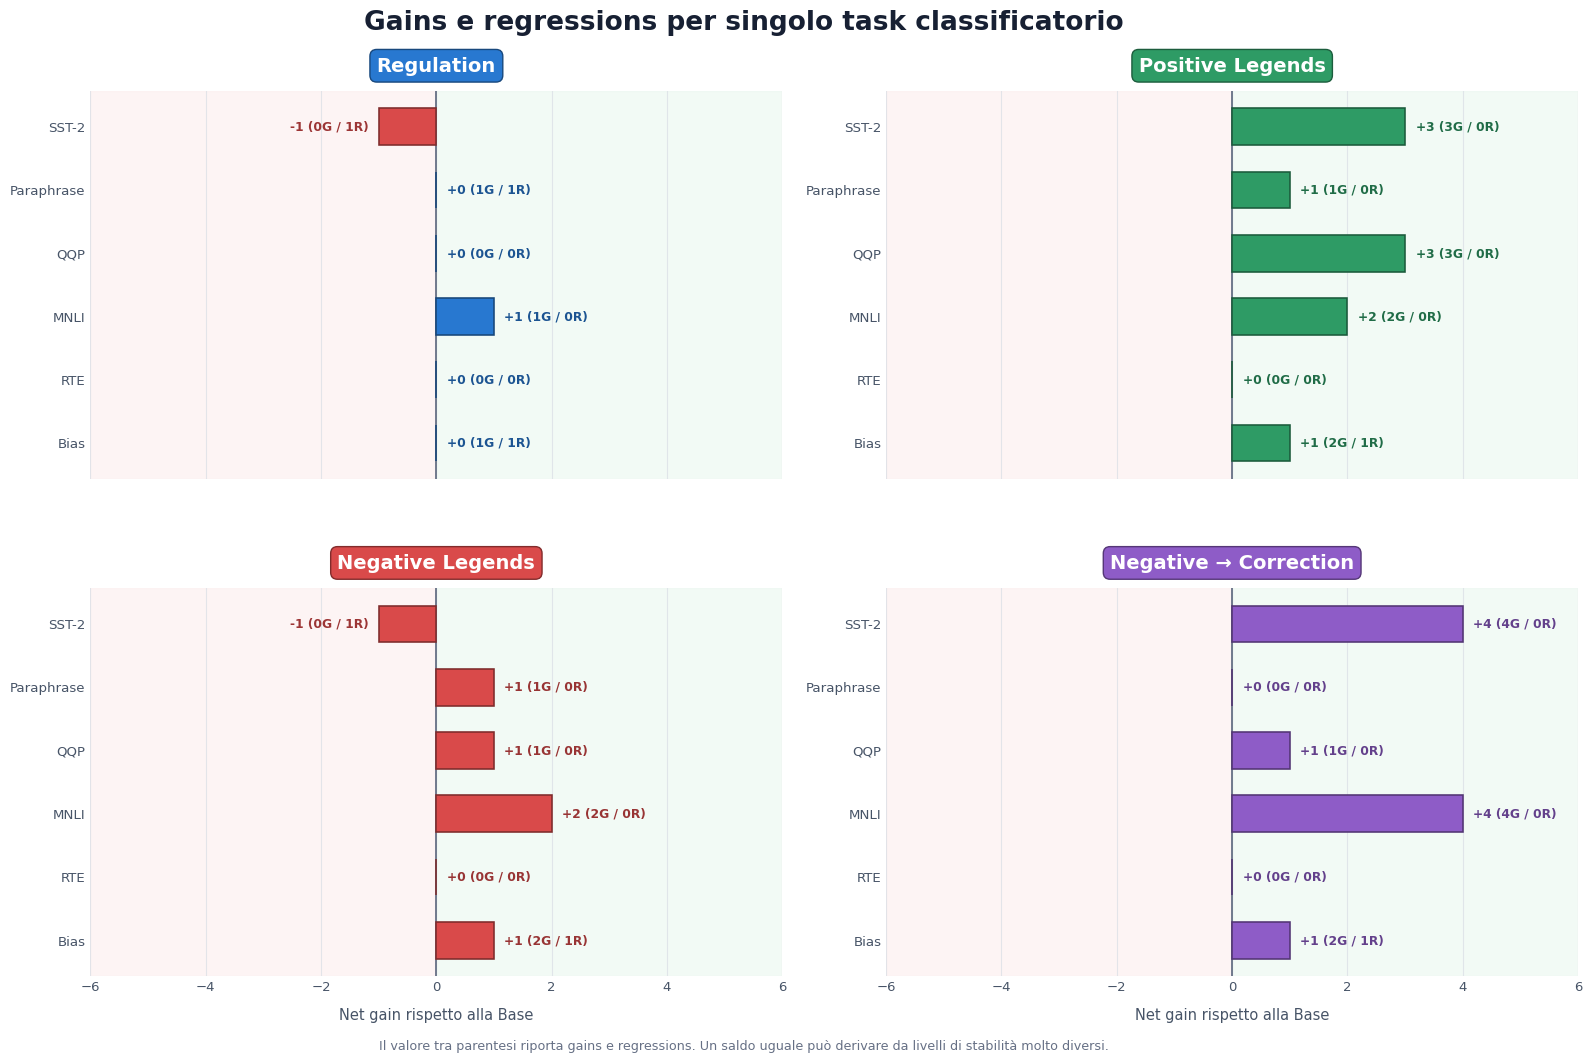

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\02_classification\03_classification_net_gain_profiles.png


In [99]:
# CELLA 15 — Alternativa alla matrice task-level.
#
# Per ciascun adapter mostra il net gain sui sei task
# tramite barre divergenti:
# - destra = miglioramento;
# - sinistra = peggioramento.
#
# Accanto a ciascuna barra viene mostrato:
# net gain e dettaglio gains/regressions.

task_effect_indexed_df = (
    classification_task_effect_df
    .set_index(
        [
            "adapter_name",
            "task_name",
        ]
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                ADAPTER_MODELS,
                CLASSIFICATION_TASKS,
            ],
            names=[
                "adapter_name",
                "task_name",
            ],
        )
    )
)


maximum_absolute_task_net_gain = float(
    task_effect_indexed_df[
        "net_gain"
    ]
    .abs()
    .max()
)


x_axis_limit = max(
    3.0,
    np.ceil(
        maximum_absolute_task_net_gain
        * 1.45
    ),
)


figure, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(
        17.2,
        10.8,
    ),
    sharex=True,
)


figure.patch.set_facecolor(
    "white"
)


axes = axes.flatten()


y_positions = np.arange(
    len(
        CLASSIFICATION_TASKS
    )
)


for axis, adapter_name in zip(
    axes,
    ADAPTER_MODELS,
):

    adapter_effect_df = (
        task_effect_indexed_df.loc[
            adapter_name
        ]
        .reindex(
            CLASSIFICATION_TASKS
        )
    )


    net_gain_values = (
        adapter_effect_df[
            "net_gain"
        ]
        .to_numpy(
            dtype=float
        )
    )


    gain_values = (
        adapter_effect_df[
            "gain"
        ]
        .to_numpy(
            dtype=int
        )
    )


    regression_values = (
        adapter_effect_df[
            "regression"
        ]
        .to_numpy(
            dtype=int
        )
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    # Zone semantiche.
    axis.axvspan(
        -x_axis_limit,
        0,
        color="#FCEEEE",
        alpha=0.62,
        zorder=0,
    )


    axis.axvspan(
        0,
        x_axis_limit,
        color="#EAF7F0",
        alpha=0.62,
        zorder=0,
    )


    bar_colors = [
        (
            model_color
            if net_gain_value >= 0
            else "#D94A4A"
        )
        for net_gain_value
        in net_gain_values
    ]


    bar_edges = [
        (
            darken_color(
                model_color,
                0.42,
            )
            if net_gain_value >= 0
            else darken_color(
                "#D94A4A",
                0.42,
            )
        )
        for net_gain_value
        in net_gain_values
    ]


    bars = axis.barh(
        y_positions,
        net_gain_values,
        height=0.58,
        color=bar_colors,
        edgecolor=bar_edges,
        linewidth=1.15,
        zorder=3,
    )


    axis.axvline(
        0,
        color="#667085",
        linewidth=1.3,
        zorder=2,
    )


    for (
        bar,
        net_gain_value,
        gain_value,
        regression_value,
    ) in zip(
        bars,
        net_gain_values,
        gain_values,
        regression_values,
    ):

        if net_gain_value > 0:

            text_x = (
                net_gain_value
                + 0.18
            )

            horizontal_alignment = "left"

        elif net_gain_value < 0:

            text_x = (
                net_gain_value
                - 0.18
            )

            horizontal_alignment = "right"

        else:

            text_x = 0.18

            horizontal_alignment = "left"


        axis.text(
            text_x,
            bar.get_y()
            + bar.get_height()
            / 2,
            (
                f"{int(net_gain_value):+d} "
                f"({gain_value}G / "
                f"{regression_value}R)"
            ),
            ha=horizontal_alignment,
            va="center",
            fontsize=8.8,
            fontweight="bold",
            color=(
                darken_color(
                    model_color,
                    0.30,
                )
                if net_gain_value >= 0
                else darken_color(
                    "#D94A4A",
                    0.28,
                )
            ),
            zorder=5,
        )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        [
            TASK_DISPLAY_NAMES[
                task_name
            ]
            for task_name
            in CLASSIFICATION_TASKS
        ],
        fontsize=9.6,
    )


    axis.invert_yaxis()


    axis.set_xlim(
        -x_axis_limit,
        x_axis_limit,
    )


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=14,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


for axis in axes[
    2:
]:
    axis.set_xlabel(
        "Net gain rispetto alla Base",
        fontsize=10.5,
        fontweight="medium",
        color="#475467",
        labelpad=10,
    )


figure.suptitle(
    "Gains e regressions per singolo task classificatorio",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    y=0.985,
)


figure.text(
    0.5,
    0.025,
    (
        "Il valore tra parentesi riporta gains e regressions. "
        "Un saldo uguale può derivare da livelli di stabilità molto diversi."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.12,
    right=0.985,
    top=0.91,
    bottom=0.09,
    hspace=0.28,
    wspace=0.15,
)


save_figure(
    figure,
    CLASSIFICATION_PLOTS_DIR
    / "03_classification_net_gain_profiles.png",
)

## 4. Trasformazione degli errori classificatori

Gains e regressions indicano quanti esempi vengono corretti o compromessi, ma non descrivono la natura degli errori.

Per ciascun task viene quindi analizzata la transizione:

\[
\text{etichetta reale} \leftarrow \text{etichetta predetta}
\]

Esempio:

```text
entailment ← neutral
ndica un esempio la cui etichetta corretta è entailment, ma che viene classificato come neutral.

Per ciascuna transizione errata vengono confrontati:

numero di occorrenze nella Base;
numero di occorrenze nell'adapter;
riduzione dell'errore.

La riduzione è definita come:

Error reduction=Errori Base−Errori adapter

Interpretazione:

valore positivo: quella tipologia di errore è stata ridotta;
valore negativo: quella tipologia di errore è stata introdotta o aumentata;
valore nullo: nessun cambiamento nel numero di occorrenze.

I task vengono mantenuti separati. Transizioni appartenenti a spazi di etichette diversi non vengono aggregate come se rappresentassero lo stesso errore.

In [100]:

# CELLA 17 — Costruisce l'analisi delle transizioni errate
# per adapter e singolo task classificatorio.
#
# Per ciascuna transizione:
#     etichetta reale ← etichetta predetta
#
# calcola:
# - occorrenze nella Base;
# - occorrenze nell'adapter;
# - riduzione dell'errore;
# - direzione del cambiamento.
#
# Valore positivo di error_reduction:
#     l'adapter riduce quella tipologia di errore.
#
# Valore negativo:
#     l'adapter introduce o aumenta quella tipologia di errore.


# =====================================================================
# COSTRUZIONE DELLE TRANSIZIONI
# =====================================================================

classification_error_transition_rows = []


for adapter_name in ADAPTER_MODELS:

    adapter_pairwise_df = (
        classification_pairwise_df[
            classification_pairwise_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .copy()
    )


    for task_name in CLASSIFICATION_TASKS:

        task_pairwise_df = (
            adapter_pairwise_df[
                adapter_pairwise_df[
                    "task_name"
                ]
                == task_name
            ]
            .copy()
        )


        if len(
            task_pairwise_df
        ) != EXPECTED_EXAMPLES_PER_TASK:
            raise RuntimeError(
                f"{adapter_name} / {task_name}: "
                "numero inatteso di esempi."
            )


        # =============================================================
        # ERRORI DELLA BASE
        # =============================================================

        base_error_counts = (
            task_pairwise_df.loc[
                ~task_pairwise_df[
                    "base_is_correct"
                ],
                [
                    "y_true",
                    "base_y_pred",
                ],
            ]
            .value_counts()
            .to_dict()
        )


        # =============================================================
        # ERRORI DELL'ADAPTER
        # =============================================================

        adapter_error_counts = (
            task_pairwise_df.loc[
                ~task_pairwise_df[
                    "adapter_is_correct"
                ],
                [
                    "y_true",
                    "adapter_y_pred",
                ],
            ]
            .value_counts()
            .to_dict()
        )


        transition_keys = sorted(
            (
                set(
                    base_error_counts
                )
                | set(
                    adapter_error_counts
                )
            ),
            key=lambda transition_key: (
                str(
                    transition_key[
                        0
                    ]
                ),
                str(
                    transition_key[
                        1
                    ]
                ),
            ),
        )


        for (
            true_label,
            predicted_label,
        ) in transition_keys:

            base_count = int(
                base_error_counts.get(
                    (
                        true_label,
                        predicted_label,
                    ),
                    0,
                )
            )


            adapter_count = int(
                adapter_error_counts.get(
                    (
                        true_label,
                        predicted_label,
                    ),
                    0,
                )
            )


            error_reduction = (
                base_count
                - adapter_count
            )


            if error_reduction > 0:
                change_direction = (
                    "reduced"
                )

            elif error_reduction < 0:
                change_direction = (
                    "increased"
                )

            else:
                change_direction = (
                    "unchanged"
                )


            classification_error_transition_rows.append({
                "adapter_name": adapter_name,
                "task_name": task_name,
                "true_label": str(
                    true_label
                ),
                "predicted_label": str(
                    predicted_label
                ),
                "transition_label": (
                    f"{true_label} ← "
                    f"{predicted_label}"
                ),
                "base_error_count": base_count,
                "adapter_error_count": adapter_count,
                "error_reduction": error_reduction,
                "absolute_change": abs(
                    error_reduction
                ),
                "change_direction": change_direction,
            })


classification_error_transitions_df = pd.DataFrame(
    classification_error_transition_rows
)


# =====================================================================
# VALIDAZIONE DEI TOTALI
# =====================================================================

transition_validation_rows = []


for adapter_name in ADAPTER_MODELS:

    for task_name in CLASSIFICATION_TASKS:

        pairwise_task_df = (
            classification_pairwise_df[
                (
                    classification_pairwise_df[
                        "adapter_name"
                    ]
                    == adapter_name
                )
                & (
                    classification_pairwise_df[
                        "task_name"
                    ]
                    == task_name
                )
            ]
        )


        transition_task_df = (
            classification_error_transitions_df[
                (
                    classification_error_transitions_df[
                        "adapter_name"
                    ]
                    == adapter_name
                )
                & (
                    classification_error_transitions_df[
                        "task_name"
                    ]
                    == task_name
                )
            ]
        )


        expected_base_errors = int(
            (
                ~pairwise_task_df[
                    "base_is_correct"
                ]
            ).sum()
        )


        expected_adapter_errors = int(
            (
                ~pairwise_task_df[
                    "adapter_is_correct"
                ]
            ).sum()
        )


        transition_base_errors = int(
            transition_task_df[
                "base_error_count"
            ].sum()
        )


        transition_adapter_errors = int(
            transition_task_df[
                "adapter_error_count"
            ].sum()
        )


        if (
            expected_base_errors
            != transition_base_errors
        ):
            raise RuntimeError(
                f"{adapter_name} / {task_name}: "
                "totale errori Base incoerente."
            )


        if (
            expected_adapter_errors
            != transition_adapter_errors
        ):
            raise RuntimeError(
                f"{adapter_name} / {task_name}: "
                "totale errori adapter incoerente."
            )


        transition_validation_rows.append({
            "adapter_name": adapter_name,
            "task_name": task_name,
            "base_errors": expected_base_errors,
            "adapter_errors": expected_adapter_errors,
            "total_error_reduction": (
                expected_base_errors
                - expected_adapter_errors
            ),
        })


classification_error_transition_validation_df = (
    pd.DataFrame(
        transition_validation_rows
    )
)


# =====================================================================
# ERRORI PERSISTENTI E TRASFORMATI
# =====================================================================

classification_shared_error_df = (
    classification_pairwise_df[
        classification_pairwise_df[
            "comparison_outcome"
        ]
        == "shared_error"
    ]
    .copy()
)


classification_shared_error_df[
    "shared_error_type"
] = np.where(
    classification_shared_error_df[
        "prediction_changed"
    ],
    "transformed_error",
    "persistent_same_error",
)


shared_error_behavior_df = (
    classification_shared_error_df
    .groupby(
        [
            "adapter_name",
            "task_name",
            "shared_error_type",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            "persistent_same_error",
            "transformed_error",
        ],
        fill_value=0,
    )
    .reset_index()
)


# =====================================================================
# RIEPILOGO DELLE TRANSIZIONI MODIFICATE
# =====================================================================

changed_transition_summary_df = (
    classification_error_transitions_df[
        classification_error_transitions_df[
            "error_reduction"
        ]
        != 0
    ]
    .groupby(
        [
            "adapter_name",
            "change_direction",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        index=ADAPTER_MODELS,
        columns=[
            "reduced",
            "increased",
        ],
        fill_value=0,
    )
    .reset_index()
)


# =====================================================================
# ESPORTAZIONE
# =====================================================================

classification_error_transitions_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_error_transitions.csv",
    index=False,
    encoding="utf-8-sig",
)


classification_error_transition_validation_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_error_transition_validation.csv",
    index=False,
    encoding="utf-8-sig",
)


shared_error_behavior_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "classification_shared_error_behavior.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    classification_error_transitions_df[
        classification_error_transitions_df[
            "error_reduction"
        ]
        != 0
    ]
    .sort_values(
        [
            "adapter_name",
            "absolute_change",
            "task_name",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


display(
    shared_error_behavior_df
)

,adapter_name,task_name,true_label,predicted_label,transition_label,base_error_count,adapter_error_count,error_reduction,absolute_change,change_direction
0,negative_legends,bias_detection,biased,unbiased,biased ← unbiased,2,0,2,2,reduced
1,negative_legends,mnli_style,contradiction,neutral,contradiction ← neutral,6,4,2,2,reduced
2,negative_legends,bias_detection,unbiased,biased,unbiased ← biased,0,1,-1,1,increased
3,negative_legends,paraphrase_style,equivalent,not_equivalent,equivalent ← not_equivalent,1,0,1,1,reduced
4,negative_legends,qqp_style,duplicate,not_duplicate,duplicate ← not_duplicate,12,11,1,1,reduced
5,negative_legends,sst2_style,compliant,non_compliant,compliant ← non_compliant,7,8,-1,1,increased
6,negative_to_correction,mnli_style,contradiction,neutral,contradiction ← neutral,6,2,4,4,reduced
7,negative_to_correction,sst2_style,compliant,non_compliant,compliant ← non_compliant,7,3,4,4,reduced
8,negative_to_correction,bias_detection,biased,unbiased,biased ← unbiased,2,0,2,2,reduced
9,negative_to_correction,bias_detection,unbiased,biased,unbiased ← biased,0,1,-1,1,increased


shared_error_type,adapter_name,task_name,persistent_same_error,transformed_error
0,negative_legends,mnli_style,11,0
1,negative_legends,qqp_style,11,0
2,negative_legends,rte_style,5,0
3,negative_legends,sst2_style,7,0
4,negative_to_correction,mnli_style,9,0
5,negative_to_correction,paraphrase_style,1,0
6,negative_to_correction,qqp_style,11,0
7,negative_to_correction,rte_style,5,0
8,negative_to_correction,sst2_style,3,0
9,positive_legends,mnli_style,11,0


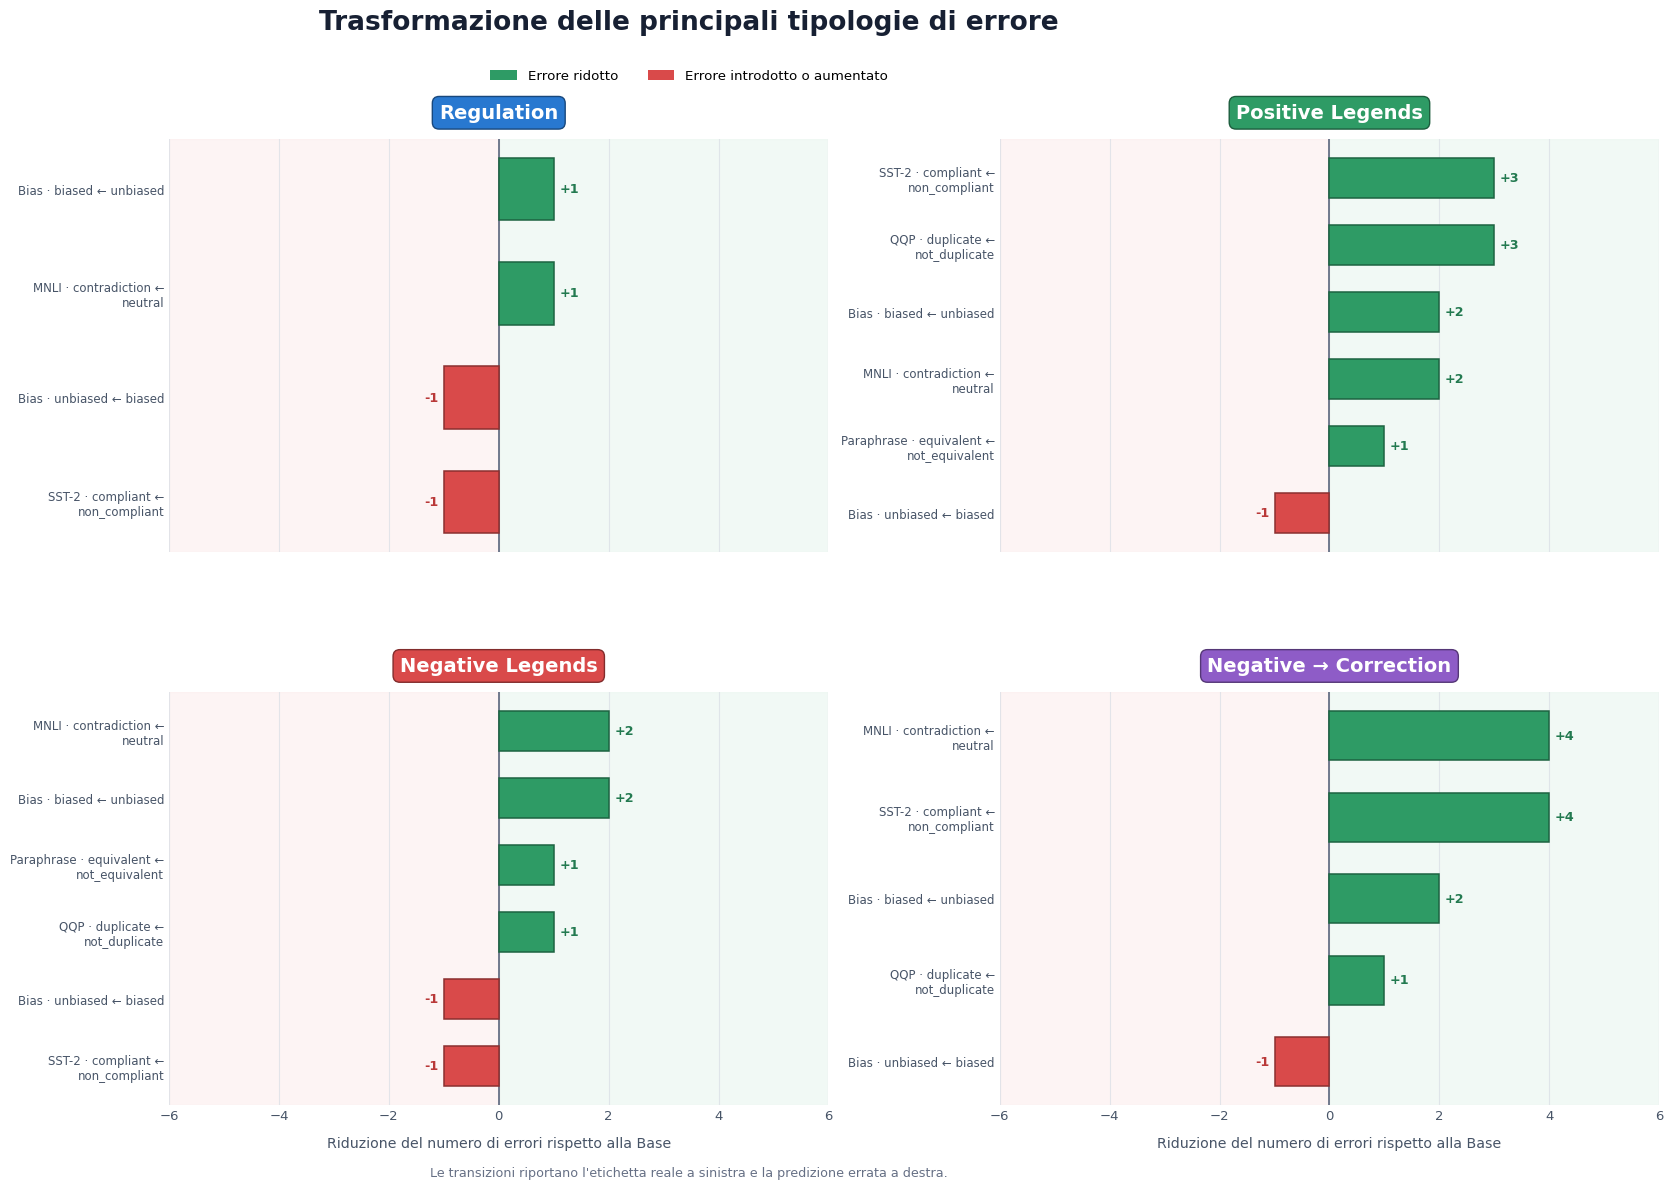

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\02_classification\04_classification_error_transition_profiles.png


In [101]:
# CELLA 18 — Mostra le principali transizioni errate
# ridotte oppure aumentate da ciascun adapter.
#
# Ogni pannello contiene le transizioni con la maggiore
# variazione assoluta rispetto al modello Base.
#
# Barra positiva:
#     errore ridotto.
#
# Barra negativa:
#     errore introdotto o aumentato.

import textwrap


TOP_TRANSITIONS_PER_ADAPTER = 8


def format_transition_axis_label(
    task_name: str,
    transition_label: str,
    maximum_width: int = 28,
) -> str:
    """
    Costruisce una label compatta:
    TASK · true ← predicted
    """

    complete_label = (
        f"{TASK_DISPLAY_NAMES[task_name]} · "
        f"{transition_label}"
    )


    return "\n".join(
        textwrap.wrap(
            complete_label,
            width=maximum_width,
            break_long_words=False,
            break_on_hyphens=False,
        )
    )


# =====================================================================
# SELEZIONE DELLE TRANSIZIONI
# =====================================================================

selected_transition_frames = []


for adapter_name in ADAPTER_MODELS:

    adapter_transition_df = (
        classification_error_transitions_df[
            (
                classification_error_transitions_df[
                    "adapter_name"
                ]
                == adapter_name
            )
            & (
                classification_error_transitions_df[
                    "error_reduction"
                ]
                != 0
            )
        ]
        .sort_values(
            [
                "absolute_change",
                "error_reduction",
                "task_name",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .head(
            TOP_TRANSITIONS_PER_ADAPTER
        )
        .copy()
    )


    selected_transition_frames.append(
        adapter_transition_df
    )


selected_error_transitions_df = pd.concat(
    selected_transition_frames,
    ignore_index=True,
)


if selected_error_transitions_df.empty:
    raise RuntimeError(
        "Non risultano transizioni di errore modificate."
    )


maximum_transition_change = float(
    selected_error_transitions_df[
        "error_reduction"
    ]
    .abs()
    .max()
)


x_axis_limit = max(
    2.0,
    np.ceil(
        maximum_transition_change
        * 1.45
    ),
)


# =====================================================================
# FIGURA
# =====================================================================

figure, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(
        20.0,
        12.0,
    ),
    sharex=True,
)


figure.patch.set_facecolor(
    "white"
)


axes = axes.flatten()


for axis, adapter_name in zip(
    axes,
    ADAPTER_MODELS,
):

    adapter_plot_df = (
        selected_error_transitions_df[
            selected_error_transitions_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .sort_values(
            "error_reduction"
        )
        .reset_index(
            drop=True
        )
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    axis.axvspan(
        -x_axis_limit,
        0,
        color="#FCEEEE",
        alpha=0.64,
        zorder=0,
    )


    axis.axvspan(
        0,
        x_axis_limit,
        color="#EAF7F0",
        alpha=0.64,
        zorder=0,
    )


    axis.axvline(
        0,
        color="#667085",
        linewidth=1.3,
        zorder=2,
    )


    if adapter_plot_df.empty:

        axis.text(
            0.5,
            0.5,
            "Nessuna transizione modificata",
            transform=axis.transAxes,
            ha="center",
            va="center",
            fontsize=11,
            color="#667085",
        )

        axis.set_yticks([])

    else:

        y_positions = np.arange(
            len(
                adapter_plot_df
            )
        )


        transition_values = (
            adapter_plot_df[
                "error_reduction"
            ]
            .to_numpy(
                dtype=float
            )
        )


        bar_colors = [
            (
                "#2E9B65"
                if transition_value > 0
                else "#D94A4A"
            )
            for transition_value
            in transition_values
        ]


        bars = axis.barh(
            y_positions,
            transition_values,
            height=0.60,
            color=bar_colors,
            edgecolor=[
                darken_color(
                    bar_color,
                    0.36,
                )
                for bar_color
                in bar_colors
            ],
            linewidth=1.1,
            zorder=3,
        )


        axis.set_yticks(
            y_positions
        )


        axis.set_yticklabels(
            [
                format_transition_axis_label(
                    task_name=row[
                        "task_name"
                    ],
                    transition_label=row[
                        "transition_label"
                    ],
                )
                for _, row
                in adapter_plot_df.iterrows()
            ],
            fontsize=8.5,
            color="#344054",
        )


        for bar, transition_value in zip(
            bars,
            transition_values,
        ):

            if transition_value > 0:
                text_x = (
                    transition_value
                    + 0.10
                )

                horizontal_alignment = (
                    "left"
                )

                value_text = (
                    f"+{int(transition_value)}"
                )

            else:
                text_x = (
                    transition_value
                    - 0.10
                )

                horizontal_alignment = (
                    "right"
                )

                value_text = str(
                    int(
                        transition_value
                    )
                )


            axis.text(
                text_x,
                bar.get_y()
                + bar.get_height()
                / 2,
                value_text,
                ha=horizontal_alignment,
                va="center",
                fontsize=9.2,
                fontweight="bold",
                color=(
                    "#237A50"
                    if transition_value > 0
                    else "#B93838"
                ),
                zorder=5,
            )


    axis.set_xlim(
        -x_axis_limit,
        x_axis_limit,
    )


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=15,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


for axis in axes[
    2:
]:
    axis.set_xlabel(
        "Riduzione del numero di errori rispetto alla Base",
        fontsize=10.2,
        fontweight="medium",
        color="#475467",
        labelpad=10,
    )


figure.suptitle(
    "Trasformazione delle principali tipologie di errore",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    y=0.988,
)


legend_handles = [
    Patch(
        facecolor="#2E9B65",
        edgecolor="none",
        label="Errore ridotto",
    ),

    Patch(
        facecolor="#D94A4A",
        edgecolor="none",
        label="Errore introdotto o aumentato",
    ),
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.948,
    ),
    ncol=2,
    frameon=False,
    fontsize=9.6,
    columnspacing=2.2,
)


figure.text(
    0.5,
    0.018,
    (
        "Le transizioni riportano l'etichetta reale a sinistra "
        "e la predizione errata a destra."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.24,
    right=0.985,
    top=0.88,
    bottom=0.075,
    hspace=0.34,
    wspace=0.26,
)


save_figure(
    figure,
    CLASSIFICATION_PLOTS_DIR
    / "04_classification_error_transition_profiles.png",
)

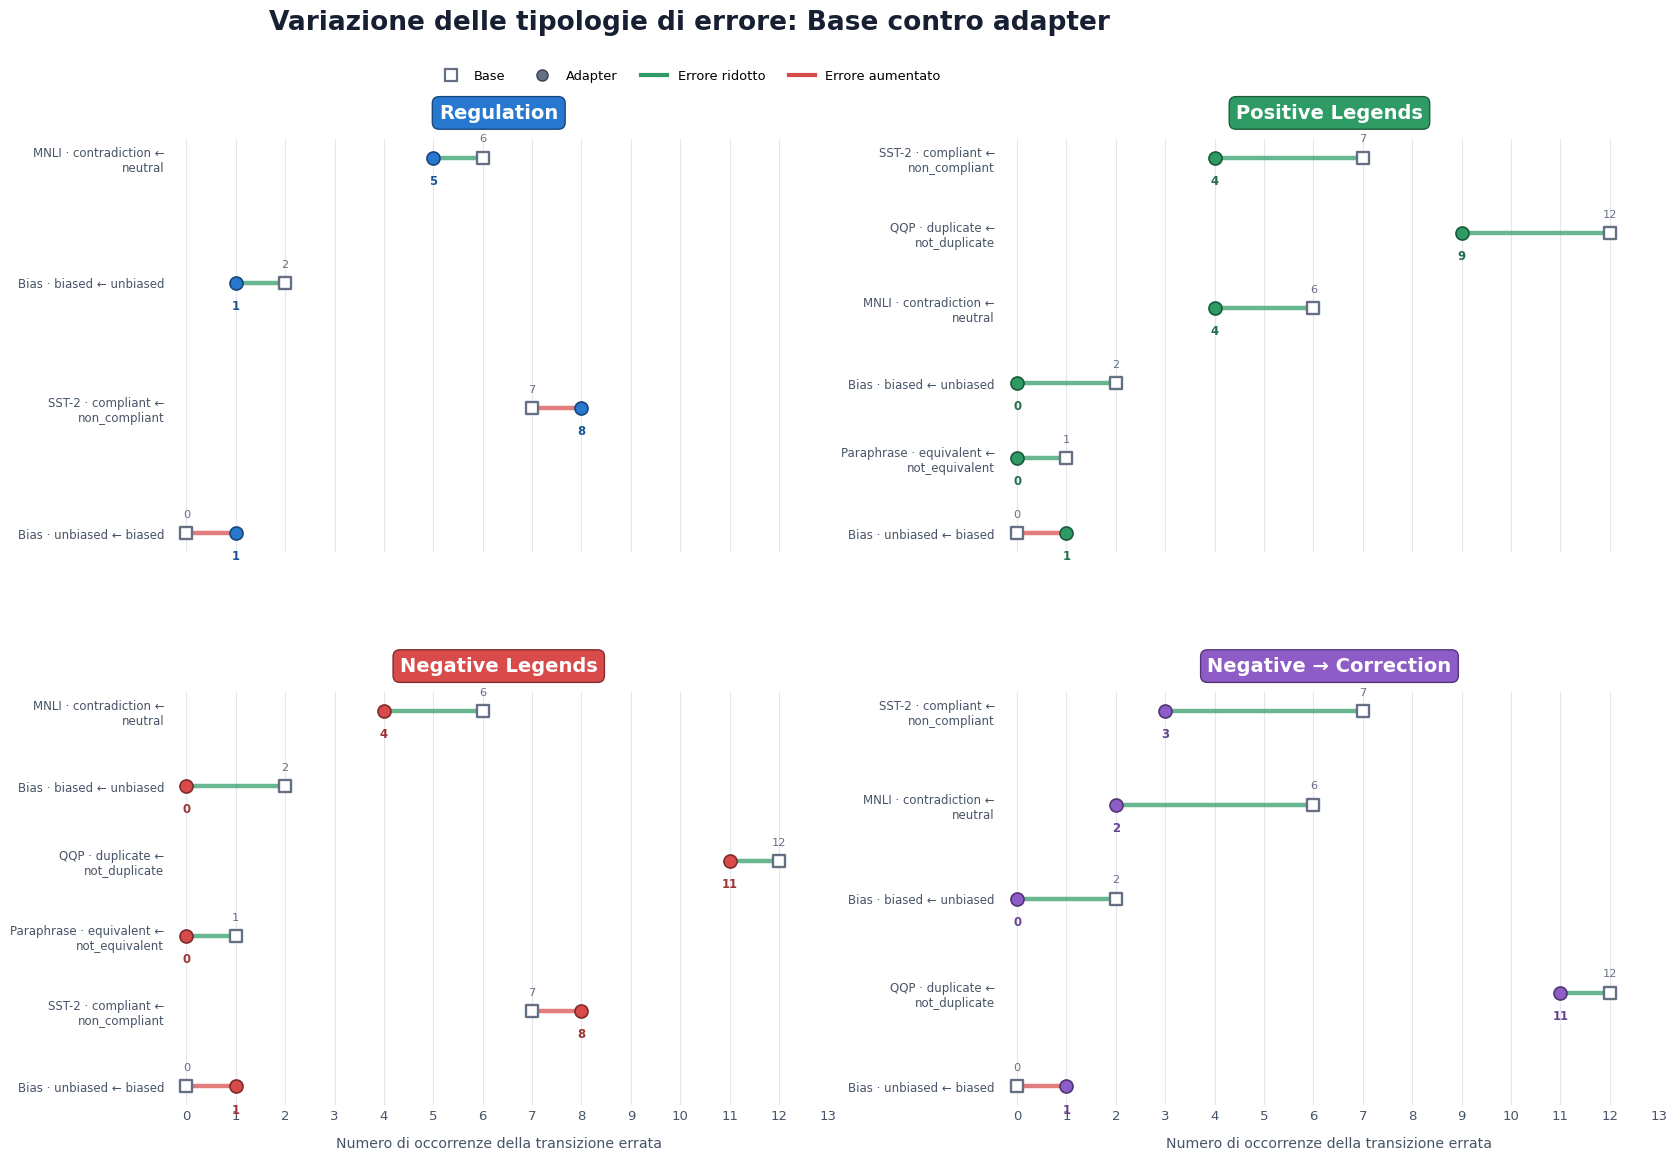

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\02_classification\05_classification_error_transition_dumbbell.png


In [102]:
# CELLA 19 — Alternativa alla visualizzazione precedente.
#
# Dumbbell chart:
# - quadrato grigio = numero di errori nella Base;
# - cerchio colorato = numero di errori nell'adapter;
# - linea verde = errore ridotto;
# - linea rossa = errore aumentato.

from matplotlib.lines import Line2D


maximum_transition_count = int(
    selected_error_transitions_df[
        [
            "base_error_count",
            "adapter_error_count",
        ]
    ]
    .to_numpy()
    .max()
)


x_axis_maximum = max(
    3,
    maximum_transition_count
    + 1,
)


figure, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(
        20.0,
        12.0,
    ),
    sharex=True,
)


figure.patch.set_facecolor(
    "white"
)


axes = axes.flatten()


for axis, adapter_name in zip(
    axes,
    ADAPTER_MODELS,
):

    adapter_plot_df = (
        selected_error_transitions_df[
            selected_error_transitions_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .sort_values(
            [
                "error_reduction",
                "task_name",
            ],
            ascending=[
                True,
                True,
            ],
        )
        .reset_index(
            drop=True
        )
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    if adapter_plot_df.empty:

        axis.text(
            0.5,
            0.5,
            "Nessuna transizione modificata",
            transform=axis.transAxes,
            ha="center",
            va="center",
            fontsize=11,
            color="#667085",
        )

        axis.set_yticks([])

    else:

        y_positions = np.arange(
            len(
                adapter_plot_df
            )
        )


        axis.set_yticks(
            y_positions
        )


        axis.set_yticklabels(
            [
                format_transition_axis_label(
                    task_name=row[
                        "task_name"
                    ],
                    transition_label=row[
                        "transition_label"
                    ],
                )
                for _, row
                in adapter_plot_df.iterrows()
            ],
            fontsize=8.5,
            color="#344054",
        )


        for row_index, row in adapter_plot_df.iterrows():

            base_count = int(
                row[
                    "base_error_count"
                ]
            )


            adapter_count = int(
                row[
                    "adapter_error_count"
                ]
            )


            error_reduction = int(
                row[
                    "error_reduction"
                ]
            )


            line_color = (
                "#2E9B65"
                if error_reduction > 0
                else "#D94A4A"
            )


            axis.plot(
                [
                    base_count,
                    adapter_count,
                ],
                [
                    row_index,
                    row_index,
                ],
                color=line_color,
                linewidth=3.2,
                alpha=0.72,
                solid_capstyle="round",
                zorder=2,
            )


            axis.scatter(
                base_count,
                row_index,
                s=78,
                marker="s",
                facecolor="white",
                edgecolor="#667085",
                linewidth=1.7,
                zorder=4,
            )


            axis.scatter(
                adapter_count,
                row_index,
                s=88,
                marker="o",
                facecolor=model_color,
                edgecolor=darken_color(
                    model_color,
                    0.42,
                ),
                linewidth=1.2,
                zorder=5,
            )


            axis.annotate(
                str(
                    base_count
                ),
                xy=(
                    base_count,
                    row_index,
                ),
                xytext=(
                    0,
                    10,
                ),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8.2,
                color="#667085",
            )


            axis.annotate(
                str(
                    adapter_count
                ),
                xy=(
                    adapter_count,
                    row_index,
                ),
                xytext=(
                    0,
                    -12,
                ),
                textcoords="offset points",
                ha="center",
                va="top",
                fontsize=8.4,
                fontweight="bold",
                color=darken_color(
                    model_color,
                    0.28,
                ),
            )


    axis.set_xlim(
        -0.35,
        x_axis_maximum,
    )


    axis.set_xticks(
        range(
            0,
            x_axis_maximum
            + 1,
        )
    )


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=15,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


for axis in axes[
    2:
]:
    axis.set_xlabel(
        "Numero di occorrenze della transizione errata",
        fontsize=10.2,
        fontweight="medium",
        color="#475467",
        labelpad=10,
    )


figure.suptitle(
    "Variazione delle tipologie di errore: Base contro adapter",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    y=0.988,
)


legend_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#667085",
        markeredgewidth=1.6,
        markersize=8,
        label="Base",
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#667085",
        markeredgecolor="#344054",
        markersize=8,
        label="Adapter",
    ),

    Line2D(
        [0],
        [0],
        color="#2E9B65",
        linewidth=3,
        label="Errore ridotto",
    ),

    Line2D(
        [0],
        [0],
        color="#D94A4A",
        linewidth=3,
        label="Errore aumentato",
    ),
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.948,
    ),
    ncol=4,
    frameon=False,
    fontsize=9.4,
    columnspacing=1.8,
)


figure.subplots_adjust(
    left=0.24,
    right=0.985,
    top=0.88,
    bottom=0.075,
    hspace=0.34,
    wspace=0.26,
)


save_figure(
    figure,
    CLASSIFICATION_PLOTS_DIR
    / "05_classification_error_transition_dumbbell.png",
)

## 5. Error analysis STS-B rispetto alla Base

Per STS-B il confronto non può essere basato sulla semplice correttezza della predizione.

Per ciascun esempio viene confrontata la distanza assoluta dalla reference:

\[
|y_{\text{Base}} - y_{\text{true}}|
\qquad
\text{contro}
\qquad
|y_{\text{adapter}} - y_{\text{true}}|
\]

Il miglioramento dell'errore è definito come:

\[
\Delta_{\text{errore}}
=
|e_{\text{Base}}|
-
|e_{\text{adapter}}|
\]

Interpretazione:

- valore positivo: l'adapter si avvicina alla reference;
- valore negativo: l'adapter si allontana dalla reference;
- valore nullo: la distanza dalla reference non cambia.

Per ogni adapter vengono analizzati:

- esempi migliorati;
- esempi peggiorati;
- pareggi;
- riduzione del MAE;
- riduzione del RMSE;
- variazione dell'errore medio firmato;
- eventuale riduzione della tendenza a sottostimare o sovrastimare.

In [103]:
# CELLA 21 — Costruisce il confronto appaiato STS-B
# tra Base e ciascun adapter.
#
# Per ogni esempio calcola:
# - errore firmato Base e adapter;
# - errore assoluto Base e adapter;
# - miglioramento dell'errore assoluto;
# - esito improved / tied / worsened.
#
# Produce anche una sintesi aggregata per adapter.


# =====================================================================
# PREPARAZIONE DELLA BASE
# =====================================================================

base_stsb_df = (
    stsb_results_df[
        stsb_results_df[
            "model_name"
        ]
        == BASE_MODEL
    ][
        [
            "example_id",
            "y_true",
            "y_pred",
            "signed_error",
            "absolute_error",
        ]
    ]
    .copy()
    .rename(
        columns={
            "y_pred": "base_y_pred",
            "signed_error": (
                "base_signed_error"
            ),
            "absolute_error": (
                "base_absolute_error"
            ),
        }
    )
)


if len(
    base_stsb_df
) != EXPECTED_EXAMPLES_PER_TASK:
    raise RuntimeError(
        "La Base non contiene i 20 esempi STS-B attesi."
    )


# =====================================================================
# FUNZIONE PER LA DIREZIONE DELL'ERRORE
# =====================================================================

def classify_signed_error_direction(
    signed_error_value: float,
) -> str:
    """
    Classifica una predizione come:
    - underestimation;
    - exact;
    - overestimation.
    """

    if signed_error_value < -PAIR_TOLERANCE:
        return "underestimation"

    if signed_error_value > PAIR_TOLERANCE:
        return "overestimation"

    return "exact"


# =====================================================================
# CONFRONTO BASE-ADAPTER
# =====================================================================

stsb_pairwise_frames = []


for adapter_name in ADAPTER_MODELS:

    adapter_stsb_df = (
        stsb_results_df[
            stsb_results_df[
                "model_name"
            ]
            == adapter_name
        ][
            [
                "example_id",
                "y_true",
                "y_pred",
                "signed_error",
                "absolute_error",
            ]
        ]
        .copy()
        .rename(
            columns={
                "y_true": "adapter_y_true",
                "y_pred": "adapter_y_pred",
                "signed_error": (
                    "adapter_signed_error"
                ),
                "absolute_error": (
                    "adapter_absolute_error"
                ),
            }
        )
    )


    paired_adapter_df = base_stsb_df.merge(
        adapter_stsb_df,
        on="example_id",
        how="outer",
        validate="one_to_one",
        indicator=True,
    )


    unmatched_rows = (
        paired_adapter_df[
            "_merge"
        ]
        != "both"
    )


    if unmatched_rows.any():
        raise RuntimeError(
            f"Il confronto STS-B Base-{adapter_name} "
            "contiene example_id non appaiati."
        )


    paired_adapter_df = (
        paired_adapter_df
        .drop(
            columns="_merge"
        )
    )


    inconsistent_references = (
        ~np.isclose(
            paired_adapter_df[
                "y_true"
            ],
            paired_adapter_df[
                "adapter_y_true"
            ],
            atol=PAIR_TOLERANCE,
            rtol=0.0,
        )
    )


    if inconsistent_references.any():
        raise RuntimeError(
            f"Reference STS-B incoerenti per {adapter_name}."
        )


    paired_adapter_df[
        "adapter_name"
    ] = adapter_name


    paired_adapter_df[
        "delta_absolute_error"
    ] = (
        paired_adapter_df[
            "base_absolute_error"
        ]
        - paired_adapter_df[
            "adapter_absolute_error"
        ]
    )


    paired_adapter_df[
        "comparison_outcome"
    ] = np.select(
        [
            (
                paired_adapter_df[
                    "delta_absolute_error"
                ]
                > PAIR_TOLERANCE
            ),

            (
                paired_adapter_df[
                    "delta_absolute_error"
                ]
                < -PAIR_TOLERANCE
            ),
        ],
        [
            "improved",
            "worsened",
        ],
        default="tied",
    )


    paired_adapter_df[
        "base_error_direction"
    ] = (
        paired_adapter_df[
            "base_signed_error"
        ]
        .apply(
            classify_signed_error_direction
        )
    )


    paired_adapter_df[
        "adapter_error_direction"
    ] = (
        paired_adapter_df[
            "adapter_signed_error"
        ]
        .apply(
            classify_signed_error_direction
        )
    )


    paired_adapter_df[
        "base_squared_error"
    ] = (
        paired_adapter_df[
            "base_signed_error"
        ]
        ** 2
    )


    paired_adapter_df[
        "adapter_squared_error"
    ] = (
        paired_adapter_df[
            "adapter_signed_error"
        ]
        ** 2
    )


    stsb_pairwise_frames.append(
        paired_adapter_df[
            [
                "adapter_name",
                "example_id",
                "y_true",
                "base_y_pred",
                "adapter_y_pred",
                "base_signed_error",
                "adapter_signed_error",
                "base_absolute_error",
                "adapter_absolute_error",
                "delta_absolute_error",
                "comparison_outcome",
                "base_error_direction",
                "adapter_error_direction",
                "base_squared_error",
                "adapter_squared_error",
            ]
        ]
    )


stsb_pairwise_df = pd.concat(
    stsb_pairwise_frames,
    ignore_index=True,
)


# =====================================================================
# VALIDAZIONE
# =====================================================================

stsb_pairwise_counts = (
    stsb_pairwise_df
    .groupby(
        "adapter_name"
    )
    .size()
    .reindex(
        ADAPTER_MODELS
    )
)


if not (
    stsb_pairwise_counts
    == EXPECTED_EXAMPLES_PER_TASK
).all():
    raise RuntimeError(
        "Il confronto STS-B non contiene 20 esempi "
        "per ciascun adapter."
    )


# =====================================================================
# SINTESI PER ADAPTER
# =====================================================================

stsb_effect_summary_rows = []


for adapter_name in ADAPTER_MODELS:

    adapter_pairwise_df = (
        stsb_pairwise_df[
            stsb_pairwise_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .copy()
    )


    outcome_counts = (
        adapter_pairwise_df[
            "comparison_outcome"
        ]
        .value_counts()
    )


    improved_count = int(
        outcome_counts.get(
            "improved",
            0,
        )
    )


    tied_count = int(
        outcome_counts.get(
            "tied",
            0,
        )
    )


    worsened_count = int(
        outcome_counts.get(
            "worsened",
            0,
        )
    )


    base_mae = float(
        adapter_pairwise_df[
            "base_absolute_error"
        ].mean()
    )


    adapter_mae = float(
        adapter_pairwise_df[
            "adapter_absolute_error"
        ].mean()
    )


    base_rmse = float(
        np.sqrt(
            adapter_pairwise_df[
                "base_squared_error"
            ].mean()
        )
    )


    adapter_rmse = float(
        np.sqrt(
            adapter_pairwise_df[
                "adapter_squared_error"
            ].mean()
        )
    )


    base_mean_signed_error = float(
        adapter_pairwise_df[
            "base_signed_error"
        ].mean()
    )


    adapter_mean_signed_error = float(
        adapter_pairwise_df[
            "adapter_signed_error"
        ].mean()
    )


    base_direction_counts = (
        adapter_pairwise_df[
            "base_error_direction"
        ]
        .value_counts()
    )


    adapter_direction_counts = (
        adapter_pairwise_df[
            "adapter_error_direction"
        ]
        .value_counts()
    )


    stsb_effect_summary_rows.append({
        "adapter_name": adapter_name,

        "improved_count": improved_count,
        "tied_count": tied_count,
        "worsened_count": worsened_count,

        "net_improved_examples": (
            improved_count
            - worsened_count
        ),

        "base_mae": base_mae,
        "adapter_mae": adapter_mae,
        "mae_reduction": (
            base_mae
            - adapter_mae
        ),

        "base_rmse": base_rmse,
        "adapter_rmse": adapter_rmse,
        "rmse_reduction": (
            base_rmse
            - adapter_rmse
        ),

        "base_mean_signed_error": (
            base_mean_signed_error
        ),

        "adapter_mean_signed_error": (
            adapter_mean_signed_error
        ),

        "bias_magnitude_reduction": (
            abs(
                base_mean_signed_error
            )
            - abs(
                adapter_mean_signed_error
            )
        ),

        "base_underestimations": int(
            base_direction_counts.get(
                "underestimation",
                0,
            )
        ),

        "adapter_underestimations": int(
            adapter_direction_counts.get(
                "underestimation",
                0,
            )
        ),

        "base_exact": int(
            base_direction_counts.get(
                "exact",
                0,
            )
        ),

        "adapter_exact": int(
            adapter_direction_counts.get(
                "exact",
                0,
            )
        ),

        "base_overestimations": int(
            base_direction_counts.get(
                "overestimation",
                0,
            )
        ),

        "adapter_overestimations": int(
            adapter_direction_counts.get(
                "overestimation",
                0,
            )
        ),
    })


stsb_effect_summary_df = (
    pd.DataFrame(
        stsb_effect_summary_rows
    )
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


# =====================================================================
# ESPORTAZIONE
# =====================================================================

stsb_pairwise_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "stsb_pairwise_vs_base.csv",
    index=False,
    encoding="utf-8-sig",
)


stsb_effect_summary_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "stsb_effect_summary.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    stsb_effect_summary_df.round(
        4
    )
)

,adapter_name,improved_count,tied_count,worsened_count,net_improved_examples,base_mae,adapter_mae,mae_reduction,base_rmse,adapter_rmse,rmse_reduction,base_mean_signed_error,adapter_mean_signed_error,bias_magnitude_reduction,base_underestimations,adapter_underestimations,base_exact,adapter_exact,base_overestimations,adapter_overestimations
0,regulation,1,19,0,1,1.05,1.00,0.05,1.3229,1.2649,0.0580,-0.85,-0.90,-0.05,14,14,5,5,1,1
1,positive_legends,1,17,2,-1,1.05,1.10,-0.05,1.3229,1.3784,-0.0555,-0.85,-1.00,-0.15,14,14,5,5,1,1
2,negative_legends,2,18,0,2,1.05,0.95,0.10,1.3229,1.2450,0.0779,-0.85,-0.85,0.00,14,13,5,6,1,1
3,negative_to_correction,1,17,2,-1,1.05,1.10,-0.05,1.3229,1.3416,-0.0188,-0.85,-1.00,-0.15,14,15,5,4,1,1


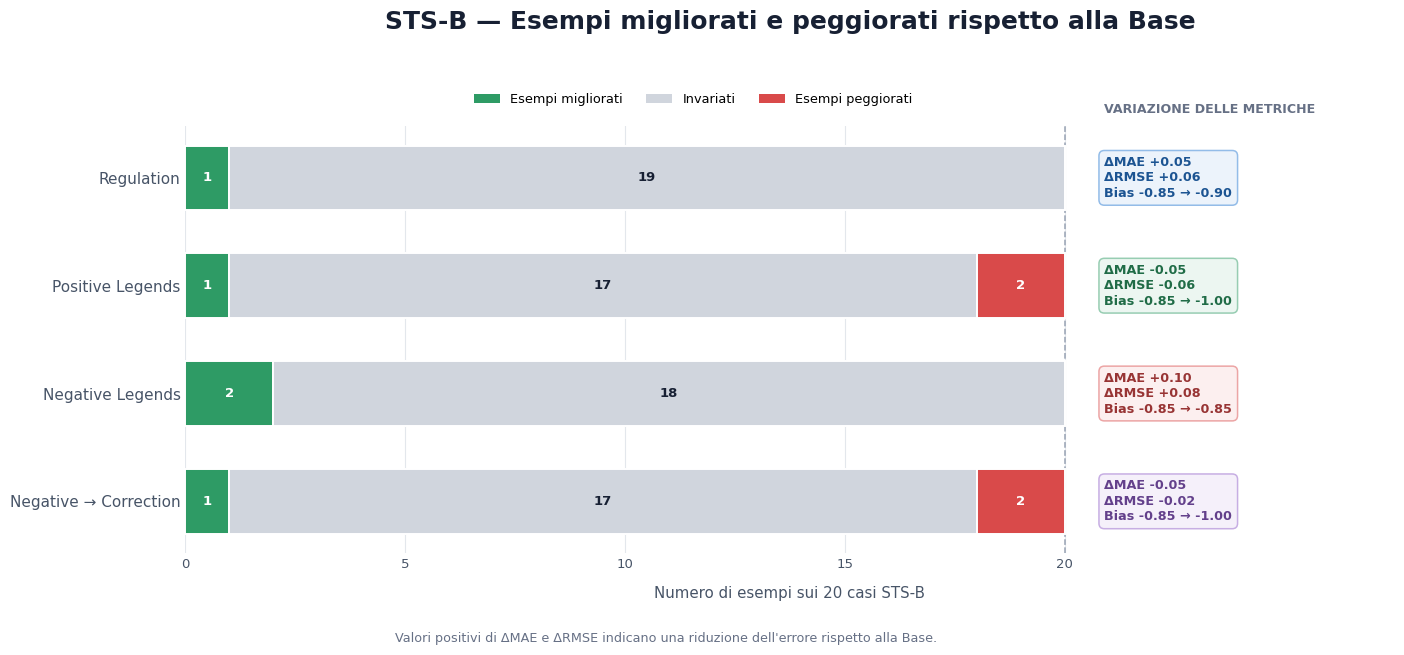

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\03_stsb\01_stsb_improved_worsened_vs_base.png


In [104]:
# CELLA 22 — Visualizza il confronto appaiato STS-B.
#
# Ogni barra rappresenta i 20 esempi:
# - migliorati;
# - invariati;
# - peggiorati.
#
# A destra vengono riportati:
# - riduzione MAE;
# - riduzione RMSE;
# - variazione del bias medio.

stsb_effect_plot_df = (
    stsb_effect_summary_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


STSB_EFFECT_COLORS = {
    "improved_count": "#2E9B65",
    "tied_count": "#D0D5DD",
    "worsened_count": "#D94A4A",
}


STSB_EFFECT_LABELS = {
    "improved_count": "Esempi migliorati",
    "tied_count": "Invariati",
    "worsened_count": "Esempi peggiorati",
}


STSB_EFFECT_TEXT_COLORS = {
    "improved_count": "white",
    "tied_count": "#172033",
    "worsened_count": "white",
}


effect_columns = [
    "improved_count",
    "tied_count",
    "worsened_count",
]


figure, axis = plt.subplots(
    figsize=(
        15.5,
        7.0,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


y_positions = np.arange(
    len(
        ADAPTER_MODELS
    )
)


left_values = np.zeros(
    len(
        ADAPTER_MODELS
    ),
    dtype=float,
)


# =====================================================================
# BARRE STACKED
# =====================================================================

for effect_column in effect_columns:

    effect_values = (
        stsb_effect_plot_df[
            effect_column
        ]
        .to_numpy(
            dtype=float
        )
    )


    bars = axis.barh(
        y_positions,
        effect_values,
        left=left_values,
        height=0.60,
        color=STSB_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="white",
        linewidth=1.4,
        zorder=3,
    )


    for (
        bar,
        effect_value,
        left_value,
    ) in zip(
        bars,
        effect_values,
        left_values,
    ):

        if effect_value <= 0:
            continue


        axis.text(
            left_value
            + effect_value
            / 2,
            bar.get_y()
            + bar.get_height()
            / 2,
            str(
                int(
                    effect_value
                )
            ),
            ha="center",
            va="center",
            fontsize=9.5,
            fontweight="bold",
            color=STSB_EFFECT_TEXT_COLORS[
                effect_column
            ],
            zorder=5,
        )


    left_values += effect_values


# =====================================================================
# RIEPILOGO A DESTRA
# =====================================================================

for row_index, row in stsb_effect_plot_df.iterrows():

    adapter_name = row[
        "adapter_name"
    ]


    mae_reduction = float(
        row[
            "mae_reduction"
        ]
    )


    rmse_reduction = float(
        row[
            "rmse_reduction"
        ]
    )


    base_bias = float(
        row[
            "base_mean_signed_error"
        ]
    )


    adapter_bias = float(
        row[
            "adapter_mean_signed_error"
        ]
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    axis.text(
        20.9,
        row_index,
        (
            f"ΔMAE {mae_reduction:+.2f}\n"
            f"ΔRMSE {rmse_reduction:+.2f}\n"
            f"Bias {base_bias:+.2f} → "
            f"{adapter_bias:+.2f}"
        ),
        ha="left",
        va="center",
        fontsize=9.2,
        fontweight="bold",
        color=darken_color(
            model_color,
            0.30,
        ),
        linespacing=1.25,
        bbox={
            "boxstyle": "round,pad=0.42",
            "facecolor": blend_colors(
                "#FFFFFF",
                model_color,
                0.09,
            ),
            "edgecolor": blend_colors(
                "#FFFFFF",
                model_color,
                0.50,
            ),
            "linewidth": 1.1,
        },
        zorder=6,
    )


# =====================================================================
# ASSI E STILE
# =====================================================================

axis.set_yticks(
    y_positions
)


axis.set_yticklabels(
    [
        MODEL_DISPLAY_NAMES[
            adapter_name
        ]
        for adapter_name
        in ADAPTER_MODELS
    ],
    fontsize=11,
    fontweight="medium",
    color="#172033",
)


axis.invert_yaxis()


axis.set_xlim(
    0,
    27.5,
)


axis.set_xticks(
    [
        0,
        5,
        10,
        15,
        20,
    ]
)


axis.set_xlabel(
    "Numero di esempi sui 20 casi STS-B",
    fontsize=10.8,
    fontweight="medium",
    color="#475467",
    labelpad=11,
)


axis.axvline(
    20,
    color="#98A2B3",
    linewidth=1.1,
    linestyle="--",
    zorder=1,
)


axis.text(
    20.9,
    1.025,
    "VARIAZIONE DELLE METRICHE",
    transform=axis.get_xaxis_transform(),
    ha="left",
    va="bottom",
    fontsize=9.1,
    fontweight="bold",
    color="#667085",
    clip_on=False,
)


axis.set_title(
    "STS-B — Esempi migliorati e peggiorati rispetto alla Base",
    fontsize=18,
    fontweight="bold",
    color="#172033",
    pad=70,
)


axis.grid(
    axis="x",
    color="#D9DEE5",
    linewidth=0.8,
    alpha=0.72,
)


axis.set_axisbelow(
    True
)


axis.tick_params(
    axis="both",
    length=0,
    colors="#475467",
)


for spine in axis.spines.values():
    spine.set_visible(
        False
    )


legend_handles = [
    Patch(
        facecolor=STSB_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="none",
        label=STSB_EFFECT_LABELS[
            effect_column
        ],
    )
    for effect_column in effect_columns
]


axis.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.42,
        1.105,
    ),
    ncol=3,
    frameon=False,
    fontsize=9.3,
    columnspacing=1.8,
)


figure.text(
    0.5,
    0.028,
    (
        "Valori positivi di ΔMAE e ΔRMSE indicano "
        "una riduzione dell'errore rispetto alla Base."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.76,
    bottom=0.15,
)


save_figure(
    figure,
    STSB_PLOTS_DIR
    / "01_stsb_improved_worsened_vs_base.png",
)

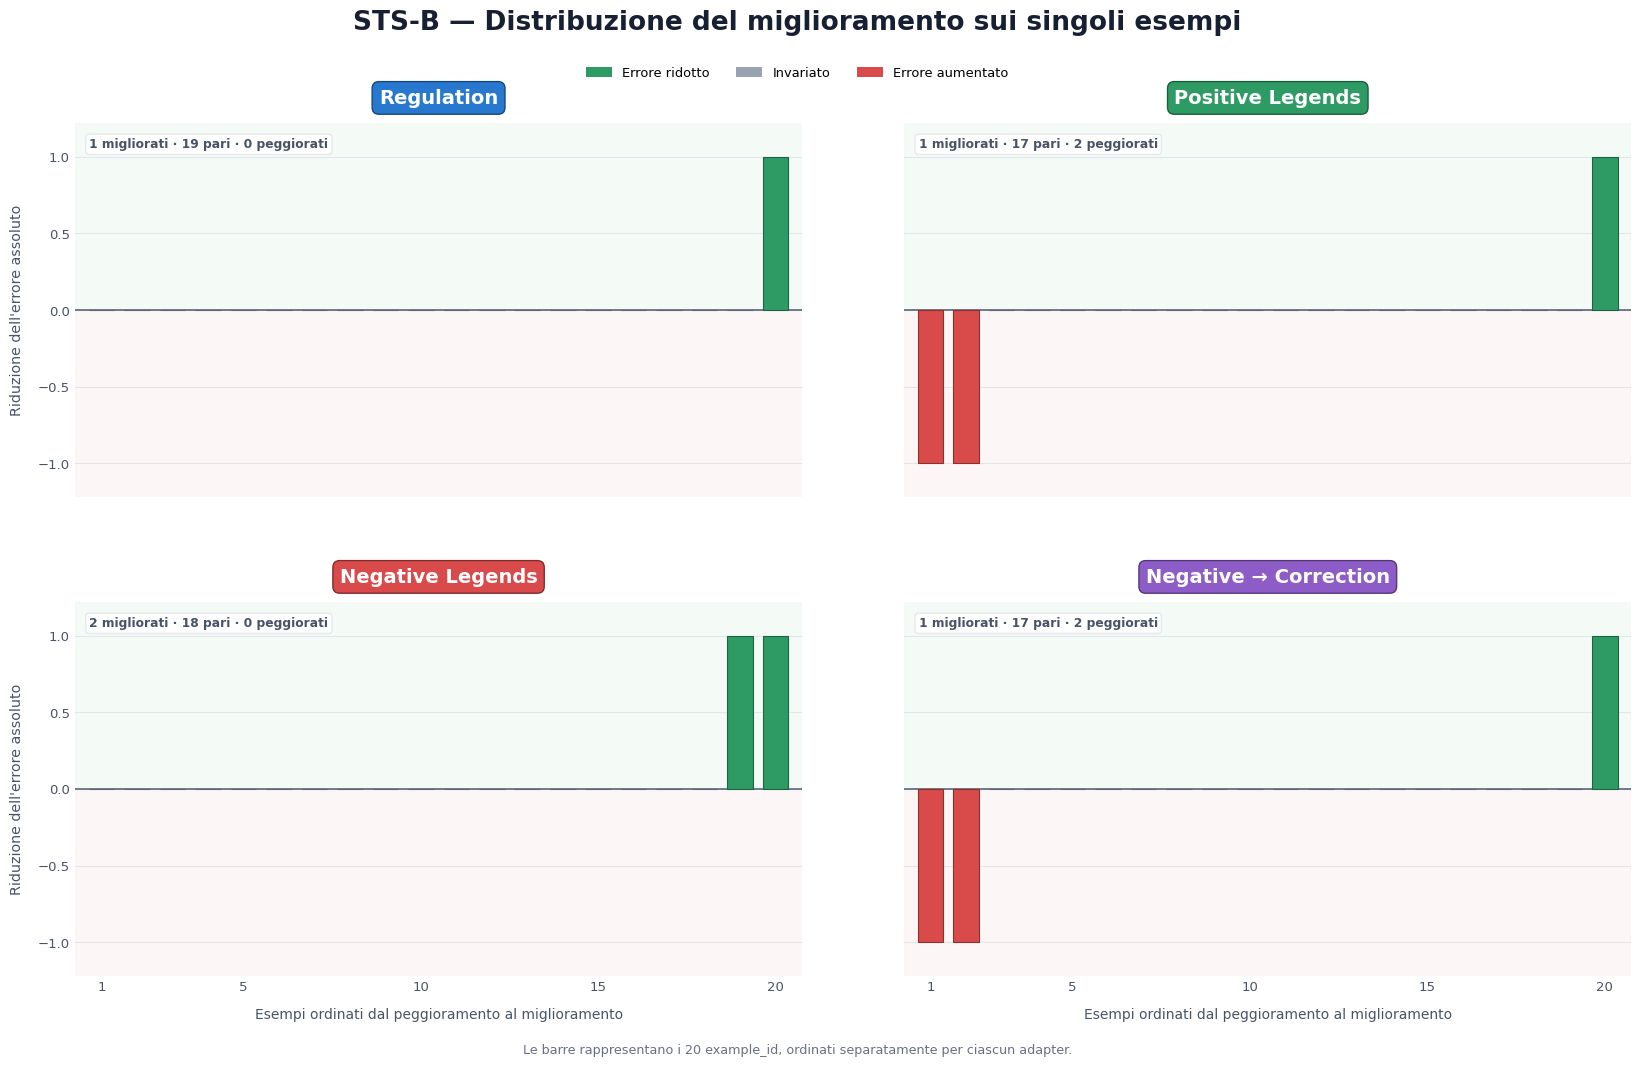

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\03_stsb\02_stsb_absolute_error_delta_distribution.png


In [105]:
# CELLA 23 — Mostra la distribuzione del miglioramento
# dell'errore assoluto sui singoli esempi STS-B.
#
# Ogni pannello contiene 20 barre ordinate:
# - sopra lo zero = adapter migliore;
# - sotto lo zero = adapter peggiore;
# - zero = stessa distanza dalla reference.


maximum_absolute_error_delta = float(
    stsb_pairwise_df[
        "delta_absolute_error"
    ]
    .abs()
    .max()
)


y_axis_limit = max(
    1.0,
    maximum_absolute_error_delta
    * 1.22,
)


figure, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(
        17.2,
        10.8,
    ),
    sharex=True,
    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


axes = axes.flatten()


for axis, adapter_name in zip(
    axes,
    ADAPTER_MODELS,
):

    adapter_plot_df = (
        stsb_pairwise_df[
            stsb_pairwise_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .sort_values(
            [
                "delta_absolute_error",
                "example_id",
            ]
        )
        .reset_index(
            drop=True
        )
    )


    delta_values = (
        adapter_plot_df[
            "delta_absolute_error"
        ]
        .to_numpy(
            dtype=float
        )
    )


    x_positions = np.arange(
        1,
        len(
            adapter_plot_df
        )
        + 1,
    )


    bar_colors = []


    for delta_value in delta_values:

        if delta_value > PAIR_TOLERANCE:
            bar_colors.append(
                "#2E9B65"
            )

        elif delta_value < -PAIR_TOLERANCE:
            bar_colors.append(
                "#D94A4A"
            )

        else:
            bar_colors.append(
                "#98A2B3"
            )


    axis.axhspan(
        0,
        y_axis_limit,
        color="#EAF7F0",
        alpha=0.48,
        zorder=0,
    )


    axis.axhspan(
        -y_axis_limit,
        0,
        color="#FCEEEE",
        alpha=0.48,
        zorder=0,
    )


    axis.bar(
        x_positions,
        delta_values,
        width=0.72,
        color=bar_colors,
        edgecolor=[
            darken_color(
                bar_color,
                0.36,
            )
            for bar_color
            in bar_colors
        ],
        linewidth=0.8,
        zorder=3,
    )


    axis.axhline(
        0,
        color="#667085",
        linewidth=1.3,
        zorder=2,
    )


    improved_count = int(
        (
            delta_values
            > PAIR_TOLERANCE
        ).sum()
    )


    tied_count = int(
        (
            np.abs(
                delta_values
            )
            <= PAIR_TOLERANCE
        ).sum()
    )


    worsened_count = int(
        (
            delta_values
            < -PAIR_TOLERANCE
        ).sum()
    )


    axis.text(
        0.02,
        0.96,
        (
            f"{improved_count} migliorati · "
            f"{tied_count} pari · "
            f"{worsened_count} peggiorati"
        ),
        transform=axis.transAxes,
        ha="left",
        va="top",
        fontsize=8.8,
        fontweight="bold",
        color="#475467",
        bbox={
            "boxstyle": "round,pad=0.30",
            "facecolor": "white",
            "edgecolor": "#E4E7EC",
            "alpha": 0.92,
        },
        zorder=6,
    )


    axis.set_xlim(
        0.25,
        EXPECTED_EXAMPLES_PER_TASK
        + 0.75,
    )


    axis.set_ylim(
        -y_axis_limit,
        y_axis_limit,
    )


    axis.set_xticks(
        [
            1,
            5,
            10,
            15,
            20,
        ]
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=14,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="y",
    )


for axis in axes[
    2:
]:
    axis.set_xlabel(
        "Esempi ordinati dal peggioramento al miglioramento",
        fontsize=10.0,
        fontweight="medium",
        color="#475467",
        labelpad=10,
    )


axes[
    0
].set_ylabel(
    "Riduzione dell'errore assoluto",
    fontsize=10.3,
    fontweight="medium",
    color="#475467",
    labelpad=10,
)


axes[
    2
].set_ylabel(
    "Riduzione dell'errore assoluto",
    fontsize=10.3,
    fontweight="medium",
    color="#475467",
    labelpad=10,
)


figure.suptitle(
    "STS-B — Distribuzione del miglioramento sui singoli esempi",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    y=0.985,
)


legend_handles = [
    Patch(
        facecolor="#2E9B65",
        edgecolor="none",
        label="Errore ridotto",
    ),

    Patch(
        facecolor="#98A2B3",
        edgecolor="none",
        label="Invariato",
    ),

    Patch(
        facecolor="#D94A4A",
        edgecolor="none",
        label="Errore aumentato",
    ),
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.943,
    ),
    ncol=3,
    frameon=False,
    fontsize=9.4,
    columnspacing=2.0,
)


figure.text(
    0.5,
    0.022,
    (
        "Le barre rappresentano i 20 example_id, ordinati "
        "separatamente per ciascun adapter."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.08,
    right=0.985,
    top=0.88,
    bottom=0.09,
    hspace=0.28,
    wspace=0.14,
)


save_figure(
    figure,
    STSB_PLOTS_DIR
    / "02_stsb_absolute_error_delta_distribution.png",
)

## 6. Effetto del fine-tuning sulla generazione

Il confronto generativo viene effettuato sulle stesse 20 domande assegnate al modello Base e a ciascun adapter.

La metrica primaria utilizzata per il confronto a livello di singola risposta è BERTScore F1, che misura la somiglianza semantica tra la risposta generata e la reference.

Per ogni risposta vengono distinti:

- miglioramento: BERTScore F1 dell'adapter superiore alla Base;
- regressione: BERTScore F1 dell'adapter inferiore alla Base;
- pareggio: differenza trascurabile tra adapter e Base.

Il delta viene definito come:

\[
\Delta_{\text{BERTScore}}
=
\text{BERTScore F1 adapter}
-
\text{BERTScore F1 Base}
\]

Interpretazione:

- valore positivo: l'adapter produce una risposta semanticamente più vicina alla reference;
- valore negativo: l'adapter si allontana dalla reference;
- valore nullo: nessun cambiamento rilevabile.

BLEU e ROUGE vengono mantenuti come metriche supplementari quando disponibili, mentre BERTScore F1 costituisce il criterio principale per classificare miglioramenti e regressioni sulle singole risposte.

In [106]:
# CELLA 25 — Costruisce il confronto appaiato della generazione
# tra il modello Base e ciascun adapter.
#
# La cella:
# - individua le metriche generative disponibili;
# - calcola i delta rispetto alla Base per ogni example_id;
# - classifica miglioramenti, regressioni e pareggi
#   tramite BERTScore F1;
# - produce una sintesi per adapter;
# - esporta le tabelle complete.

# =====================================================================
# FUNZIONE DI SUPPORTO
# =====================================================================

def first_existing_column(
    columns,
    candidate_names,
):
    """
    Restituisce la prima colonna disponibile
    tra quelle candidate.
    """

    columns_set = set(
        columns
    )

    for candidate_name in candidate_names:
        if candidate_name in columns_set:
            return candidate_name

    return None


# =====================================================================
# INDIVIDUAZIONE DELLE METRICHE DISPONIBILI
# =====================================================================

GENERATION_METRIC_CANDIDATES = {
    "sentence_bleu": [
        "sentence_bleu",
        "sentence_bleu_score",
        "bleu_sentence",
        "bleu_score",
    ],

    "rouge1_f1": [
        "rouge1_f1",
        "rouge_1_f1",
        "rouge1_fmeasure",
    ],

    "rouge2_f1": [
        "rouge2_f1",
        "rouge_2_f1",
        "rouge2_fmeasure",
    ],

    "rougeL_f1": [
        "rougeL_f1",
        "rouge_l_f1",
        "rougel_f1",
        "rougeL_fmeasure",
    ],

    "bertscore_f1": [
        "bertscore_f1",
        "bert_score_f1",
        "bert_f1",
    ],
}


generation_analysis_df = (
    generation_by_example_df
    .copy()
)


available_generation_metrics = []


for (
    canonical_metric_name,
    candidate_names,
) in GENERATION_METRIC_CANDIDATES.items():

    source_column = first_existing_column(
        generation_analysis_df.columns,
        candidate_names,
    )


    if source_column is None:
        continue


    generation_analysis_df[
        canonical_metric_name
    ] = pd.to_numeric(
        generation_analysis_df[
            source_column
        ],
        errors="raise",
    )


    available_generation_metrics.append(
        canonical_metric_name
    )


if (
    "bertscore_f1"
    not in available_generation_metrics
):
    raise RuntimeError(
        "La metrica BERTScore F1 non è disponibile "
        "nel file generation_metrics_by_example.csv."
    )


generation_analysis_df[
    "model_name"
] = (
    generation_analysis_df[
        "model_name"
    ]
    .astype(str)
    .str.strip()
)


generation_analysis_df[
    "example_id"
] = (
    generation_analysis_df[
        "example_id"
    ]
    .astype(str)
    .str.strip()
)


# =====================================================================
# PREPARAZIONE DEL MODELLO BASE
# =====================================================================

base_generation_df = (
    generation_analysis_df[
        generation_analysis_df[
            "model_name"
        ]
        == BASE_MODEL
    ][
        [
            "example_id",
            *available_generation_metrics,
        ]
    ]
    .copy()
    .rename(
        columns={
            metric_name: (
                f"base_{metric_name}"
            )
            for metric_name
            in available_generation_metrics
        }
    )
)


if len(
    base_generation_df
) != EXPECTED_EXAMPLES_PER_TASK:
    raise RuntimeError(
        "La Base non contiene i 20 esempi "
        "generativi attesi."
    )


if base_generation_df[
    "example_id"
].duplicated().any():
    raise RuntimeError(
        "La Base contiene example_id generativi duplicati."
    )


# =====================================================================
# CONFRONTO BASE-ADAPTER
# =====================================================================

generation_pairwise_frames = []


for adapter_name in ADAPTER_MODELS:

    adapter_generation_df = (
        generation_analysis_df[
            generation_analysis_df[
                "model_name"
            ]
            == adapter_name
        ][
            [
                "example_id",
                *available_generation_metrics,
            ]
        ]
        .copy()
        .rename(
            columns={
                metric_name: (
                    f"adapter_{metric_name}"
                )
                for metric_name
                in available_generation_metrics
            }
        )
    )


    if len(
        adapter_generation_df
    ) != EXPECTED_EXAMPLES_PER_TASK:
        raise RuntimeError(
            f"{adapter_name}: numero inatteso "
            "di esempi generativi."
        )


    paired_generation_df = (
        base_generation_df
        .merge(
            adapter_generation_df,
            on="example_id",
            how="outer",
            validate="one_to_one",
            indicator=True,
        )
    )


    unmatched_rows = (
        paired_generation_df[
            "_merge"
        ]
        != "both"
    )


    if unmatched_rows.any():
        raise RuntimeError(
            f"Il confronto generativo Base-{adapter_name} "
            "contiene example_id non appaiati."
        )


    paired_generation_df = (
        paired_generation_df
        .drop(
            columns="_merge"
        )
    )


    paired_generation_df[
        "adapter_name"
    ] = adapter_name


    # ================================================================
    # DELTA DELLE METRICHE
    # ================================================================

    for metric_name in available_generation_metrics:

        paired_generation_df[
            f"delta_{metric_name}"
        ] = (
            paired_generation_df[
                f"adapter_{metric_name}"
            ]
            - paired_generation_df[
                f"base_{metric_name}"
            ]
        )


    # ================================================================
    # ESITO PRIMARIO TRAMITE BERTSCORE F1
    # ================================================================

    paired_generation_df[
        "comparison_outcome"
    ] = np.select(
        [
            (
                paired_generation_df[
                    "delta_bertscore_f1"
                ]
                > PAIR_TOLERANCE
            ),

            (
                paired_generation_df[
                    "delta_bertscore_f1"
                ]
                < -PAIR_TOLERANCE
            ),
        ],

        [
            "improved",
            "worsened",
        ],

        default="tied",
    )


    generation_pairwise_frames.append(
        paired_generation_df
    )


generation_pairwise_df = pd.concat(
    generation_pairwise_frames,
    ignore_index=True,
)


# =====================================================================
# VALIDAZIONE
# =====================================================================

generation_pairwise_counts = (
    generation_pairwise_df
    .groupby(
        "adapter_name"
    )
    .size()
    .reindex(
        ADAPTER_MODELS
    )
)


if not (
    generation_pairwise_counts
    == EXPECTED_EXAMPLES_PER_TASK
).all():

    raise RuntimeError(
        "Il confronto generativo non contiene 20 esempi "
        "per ciascun adapter:\n"
        + generation_pairwise_counts.to_string()
    )


# =====================================================================
# SINTESI PER ADAPTER
# =====================================================================

generation_effect_summary_rows = []


for adapter_name in ADAPTER_MODELS:

    adapter_pairwise_df = (
        generation_pairwise_df[
            generation_pairwise_df[
                "adapter_name"
            ]
            == adapter_name
        ]
        .copy()
    )


    outcome_counts = (
        adapter_pairwise_df[
            "comparison_outcome"
        ]
        .value_counts()
    )


    improved_count = int(
        outcome_counts.get(
            "improved",
            0,
        )
    )


    tied_count = int(
        outcome_counts.get(
            "tied",
            0,
        )
    )


    worsened_count = int(
        outcome_counts.get(
            "worsened",
            0,
        )
    )


    summary_row = {
        "adapter_name": adapter_name,

        "improved_count": improved_count,

        "tied_count": tied_count,

        "worsened_count": worsened_count,

        "net_improvement": (
            improved_count
            - worsened_count
        ),
    }


    for metric_name in available_generation_metrics:

        summary_row[
            f"mean_delta_{metric_name}"
        ] = float(
            adapter_pairwise_df[
                f"delta_{metric_name}"
            ].mean()
        )


    generation_effect_summary_rows.append(
        summary_row
    )


generation_effect_summary_df = (
    pd.DataFrame(
        generation_effect_summary_rows
    )
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


# =====================================================================
# ESPORTAZIONE
# =====================================================================

generation_pairwise_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "generation_pairwise_vs_base.csv",
    index=False,
    encoding="utf-8-sig",
)


generation_effect_summary_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "generation_effect_summary.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    generation_effect_summary_df.round(
        4
    )
)

,adapter_name,improved_count,tied_count,worsened_count,net_improvement,mean_delta_sentence_bleu,mean_delta_rouge1_f1,mean_delta_rouge2_f1,mean_delta_rougeL_f1,mean_delta_bertscore_f1
0,regulation,15,0,5,10,0.0045,0.0171,0.0075,0.0474,0.0097
1,positive_legends,15,0,5,10,0.0281,0.0555,0.0522,0.0973,0.0289
2,negative_legends,15,0,5,10,0.0183,0.0350,0.0317,0.0722,0.0212
3,negative_to_correction,17,0,3,14,0.0070,0.0261,0.0168,0.0419,0.0279


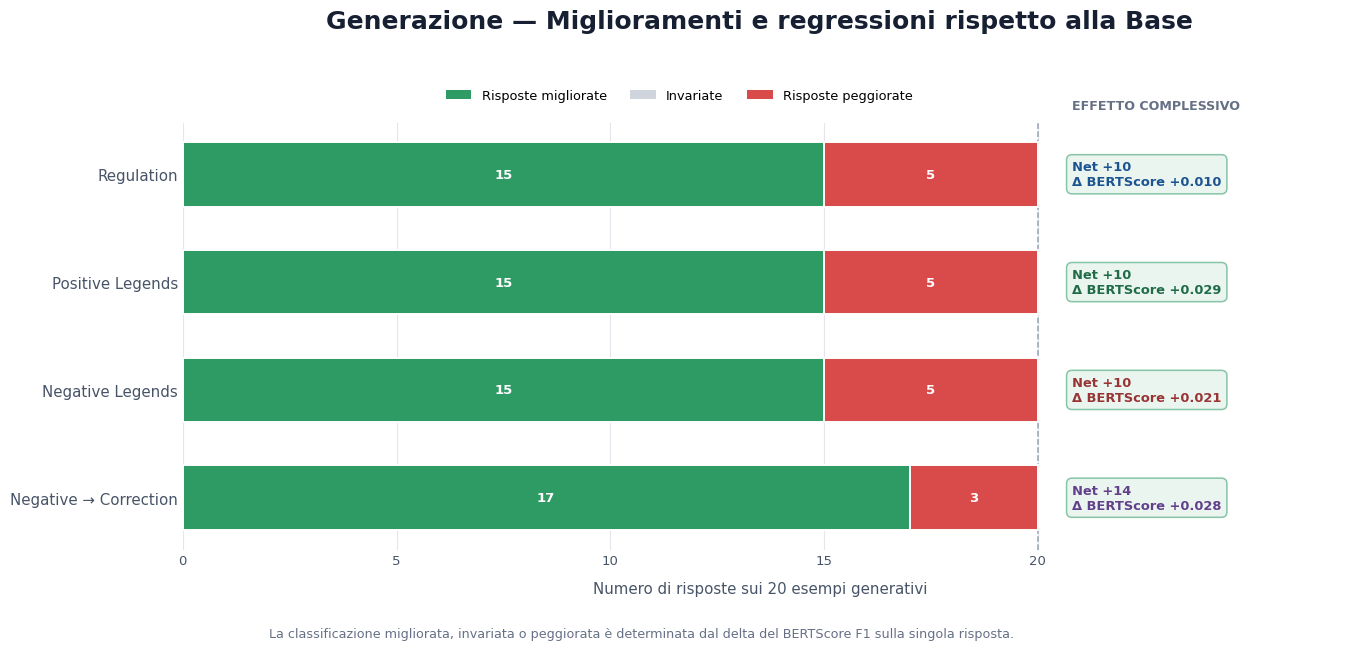

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\04_generation\01_generation_improved_worsened_vs_base.png


In [107]:
# CELLA 26 — Visualizza miglioramenti, pareggi e regressioni
# delle risposte generative rispetto alla Base.
#
# Il confronto primario utilizza BERTScore F1.
#
# Ogni barra rappresenta i 20 esempi generativi:
# - migliorati;
# - invariati;
# - peggiorati.
#
# A destra viene riportata la variazione media
# di BERTScore F1.

generation_effect_plot_df = (
    generation_effect_summary_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


GENERATION_EFFECT_COLORS = {
    "improved_count": "#2E9B65",
    "tied_count": "#D0D5DD",
    "worsened_count": "#D94A4A",
}


GENERATION_EFFECT_LABELS = {
    "improved_count": "Risposte migliorate",
    "tied_count": "Invariate",
    "worsened_count": "Risposte peggiorate",
}


GENERATION_EFFECT_TEXT_COLORS = {
    "improved_count": "white",
    "tied_count": "#172033",
    "worsened_count": "white",
}


effect_columns = [
    "improved_count",
    "tied_count",
    "worsened_count",
]


figure, axis = plt.subplots(
    figsize=(
        14.8,
        7.0,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


y_positions = np.arange(
    len(
        ADAPTER_MODELS
    )
)


left_values = np.zeros(
    len(
        ADAPTER_MODELS
    ),
    dtype=float,
)


# =====================================================================
# BARRE STACKED
# =====================================================================

for effect_column in effect_columns:

    effect_values = (
        generation_effect_plot_df[
            effect_column
        ]
        .to_numpy(
            dtype=float
        )
    )


    bars = axis.barh(
        y_positions,
        effect_values,
        left=left_values,
        height=0.60,
        color=GENERATION_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="white",
        linewidth=1.4,
        zorder=3,
    )


    for (
        bar,
        effect_value,
        left_value,
    ) in zip(
        bars,
        effect_values,
        left_values,
    ):

        if effect_value <= 0:
            continue


        if effect_value >= 2:

            axis.text(
                left_value
                + effect_value
                / 2,
                bar.get_y()
                + bar.get_height()
                / 2,
                str(
                    int(
                        effect_value
                    )
                ),
                ha="center",
                va="center",
                fontsize=9.5,
                fontweight="bold",
                color=GENERATION_EFFECT_TEXT_COLORS[
                    effect_column
                ],
                zorder=5,
            )

        else:

            axis.text(
                left_value
                + effect_value
                / 2,
                bar.get_y()
                + bar.get_height()
                + 0.08,
                str(
                    int(
                        effect_value
                    )
                ),
                ha="center",
                va="bottom",
                fontsize=8.4,
                fontweight="bold",
                color=GENERATION_EFFECT_COLORS[
                    effect_column
                ],
                zorder=5,
            )


    left_values += effect_values


# =====================================================================
# RIEPILOGO A DESTRA
# =====================================================================

for row_index, row in generation_effect_plot_df.iterrows():

    adapter_name = row[
        "adapter_name"
    ]


    mean_delta_bertscore = float(
        row[
            "mean_delta_bertscore_f1"
        ]
    )


    net_improvement = int(
        row[
            "net_improvement"
        ]
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    if mean_delta_bertscore > 0:

        semantic_color = "#2E9B65"

    elif mean_delta_bertscore < 0:

        semantic_color = "#D94A4A"

    else:

        semantic_color = "#98A2B3"


    axis.text(
        20.8,
        row_index,
        (
            f"Net {net_improvement:+d}\n"
            f"Δ BERTScore {mean_delta_bertscore:+.3f}"
        ),
        ha="left",
        va="center",
        fontsize=9.4,
        fontweight="bold",
        color=darken_color(
            model_color,
            0.30,
        ),
        linespacing=1.22,
        bbox={
            "boxstyle": "round,pad=0.42",
            "facecolor": blend_colors(
                "#FFFFFF",
                semantic_color,
                0.10,
            ),
            "edgecolor": blend_colors(
                "#FFFFFF",
                semantic_color,
                0.58,
            ),
            "linewidth": 1.1,
        },
        zorder=6,
    )


# =====================================================================
# ASSI
# =====================================================================

axis.set_yticks(
    y_positions
)


axis.set_yticklabels(
    [
        MODEL_DISPLAY_NAMES[
            adapter_name
        ]
        for adapter_name
        in ADAPTER_MODELS
    ],
    fontsize=10.8,
    fontweight="medium",
    color="#172033",
)


axis.invert_yaxis()


axis.set_xlim(
    0,
    27.0,
)


axis.set_xticks(
    [
        0,
        5,
        10,
        15,
        20,
    ]
)


axis.set_xlabel(
    "Numero di risposte sui 20 esempi generativi",
    fontsize=10.8,
    fontweight="medium",
    color="#475467",
    labelpad=10,
)


axis.axvline(
    20,
    color="#98A2B3",
    linewidth=1.1,
    linestyle="--",
    zorder=1,
)


axis.text(
    20.8,
    1.025,
    "EFFETTO COMPLESSIVO",
    transform=axis.get_xaxis_transform(),
    ha="left",
    va="bottom",
    fontsize=9.1,
    fontweight="bold",
    color="#667085",
    clip_on=False,
)


axis.set_title(
    "Generazione — Miglioramenti e regressioni rispetto alla Base",
    fontsize=18,
    fontweight="bold",
    color="#172033",
    pad=68,
)


legend_handles = [
    Patch(
        facecolor=GENERATION_EFFECT_COLORS[
            effect_column
        ],
        edgecolor="none",
        label=GENERATION_EFFECT_LABELS[
            effect_column
        ],
    )
    for effect_column
    in effect_columns
]


axis.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.43,
        1.105,
    ),
    ncol=3,
    frameon=False,
    fontsize=9.3,
    columnspacing=1.8,
)


figure.text(
    0.5,
    0.03,
    (
        "La classificazione migliorata, invariata o peggiorata "
        "è determinata dal delta del BERTScore F1 "
        "sulla singola risposta."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


style_axis(
    axis,
    grid_axis="x",
)


figure.subplots_adjust(
    left=0.19,
    right=0.97,
    top=0.76,
    bottom=0.15,
)


save_figure(
    figure,
    GENERATION_PLOTS_DIR
    / "01_generation_improved_worsened_vs_base.png",
)

In [108]:
# CELLA 28 — Seleziona automaticamente casi rappresentativi.
#
# Casi ricercati:
# - esempio corretto dal maggior numero di adapter;
# - esempio peggiorato dal maggior numero di adapter;
# - esempio favorevole a Regulation;
# - esempio favorevole a una strategia narrativa;
# - maggiore miglioramento generativo tramite BERTScore F1;
# - maggiore regressione generativa tramite BERTScore F1.
#
# I testi vengono inclusi quando presenti nei file sorgente.

# =====================================================================
# FUNZIONI PER I CAMPI TESTUALI
# =====================================================================

def combine_available_text_fields(
    row,
    candidate_columns,
):
    """
    Combina i campi testuali disponibili
    di una singola riga.
    """

    text_parts = []


    for column_name in candidate_columns:

        if column_name not in row.index:
            continue


        value = row[
            column_name
        ]


        if pd.isna(
            value
        ):
            continue


        value_text = str(
            value
        ).strip()


        if not value_text:
            continue


        text_parts.append(
            f"{column_name}: {value_text}"
        )


    if not text_parts:
        return None


    return "\n".join(
        text_parts
    )


CLASSIFICATION_INPUT_COLUMNS = [
    "text",
    "input_text",
    "prompt",
    "sentence",
    "sentence1",
    "sentence2",
    "text_a",
    "text_b",
    "premise",
    "hypothesis",
    "question1",
    "question2",
]


GENERATION_INPUT_COLUMNS = [
    "input_text",
    "prompt",
    "question",
    "input",
    "text",
]


GENERATION_OUTPUT_COLUMNS = [
    "generated_answer",
    "generated_text",
    "prediction",
    "model_output",
    "y_pred",
    "output",
]


GENERATION_REFERENCE_COLUMNS = [
    "reference_answer",
    "reference",
    "target",
    "expected_answer",
    "y_true",
]


representative_case_rows = []


# =====================================================================
# FUNZIONE PER I CASI CLASSIFICATORI
# =====================================================================

def add_classification_case(
    case_id,
    case_type,
    task_name,
    example_id,
    selected_model,
    comparison_model,
    selection_reason,
):
    """
    Aggiunge un caso classificatorio.
    """

    selected_rows = (
        classification_results_df[
            (
                classification_results_df[
                    "model_name"
                ]
                == selected_model
            )
            & (
                classification_results_df[
                    "task_name"
                ]
                == task_name
            )
            & (
                classification_results_df[
                    "example_id"
                ]
                == example_id
            )
        ]
    )


    comparison_rows = (
        classification_results_df[
            (
                classification_results_df[
                    "model_name"
                ]
                == comparison_model
            )
            & (
                classification_results_df[
                    "task_name"
                ]
                == task_name
            )
            & (
                classification_results_df[
                    "example_id"
                ]
                == example_id
            )
        ]
    )


    if (
        selected_rows.empty
        or comparison_rows.empty
    ):
        return


    selected_row = (
        selected_rows.iloc[
            0
        ]
    )


    comparison_row = (
        comparison_rows.iloc[
            0
        ]
    )


    representative_case_rows.append({
        "case_id": case_id,
        "case_type": case_type,
        "task_name": task_name,
        "example_id": example_id,

        "selected_model": selected_model,
        "comparison_model": comparison_model,

        "input_text": (
            combine_available_text_fields(
                selected_row,
                CLASSIFICATION_INPUT_COLUMNS,
            )
        ),

        "reference": selected_row[
            "y_true"
        ],

        "comparison_output": comparison_row[
            "y_pred"
        ],

        "selected_output": selected_row[
            "y_pred"
        ],

        "comparison_correct": bool(
            comparison_row[
                "is_correct"
            ]
        ),

        "selected_correct": bool(
            selected_row[
                "is_correct"
            ]
        ),

        "delta_bertscore_f1": np.nan,

        "selection_reason": selection_reason,
    })


# =====================================================================
# FUNZIONE PER I CASI GENERATIVI
# =====================================================================

def add_generation_case(
    case_id,
    case_type,
    pairwise_row,
    selection_reason,
):
    """
    Aggiunge un caso generativo.
    """

    adapter_name = (
        pairwise_row[
            "adapter_name"
        ]
    )


    example_id = (
        pairwise_row[
            "example_id"
        ]
    )


    base_rows = (
        generation_analysis_df[
            (
                generation_analysis_df[
                    "model_name"
                ]
                == BASE_MODEL
            )
            & (
                generation_analysis_df[
                    "example_id"
                ]
                == example_id
            )
        ]
    )


    adapter_rows = (
        generation_analysis_df[
            (
                generation_analysis_df[
                    "model_name"
                ]
                == adapter_name
            )
            & (
                generation_analysis_df[
                    "example_id"
                ]
                == example_id
            )
        ]
    )


    if (
        base_rows.empty
        or adapter_rows.empty
    ):
        return


    base_row = (
        base_rows.iloc[
            0
        ]
    )


    adapter_row = (
        adapter_rows.iloc[
            0
        ]
    )


    representative_case_rows.append({
        "case_id": case_id,
        "case_type": case_type,
        "task_name": GENERATION_TASK,
        "example_id": example_id,

        "selected_model": adapter_name,
        "comparison_model": BASE_MODEL,

        "input_text": (
            combine_available_text_fields(
                adapter_row,
                GENERATION_INPUT_COLUMNS,
            )
        ),

        "reference": (
            combine_available_text_fields(
                adapter_row,
                GENERATION_REFERENCE_COLUMNS,
            )
        ),

        "comparison_output": (
            combine_available_text_fields(
                base_row,
                GENERATION_OUTPUT_COLUMNS,
            )
        ),

        "selected_output": (
            combine_available_text_fields(
                adapter_row,
                GENERATION_OUTPUT_COLUMNS,
            )
        ),

        "comparison_correct": np.nan,
        "selected_correct": np.nan,

        "delta_bertscore_f1": float(
            pairwise_row[
                "delta_bertscore_f1"
            ]
        ),

        "selection_reason": selection_reason,
    })


# =====================================================================
# CASO 1 — GAIN CONDIVISO DA PIÙ ADAPTER
# =====================================================================

classification_example_effect_df = (
    classification_pairwise_df
    .groupby(
        [
            "task_name",
            "example_id",
        ]
    )
    .agg(
        gain_count=(
            "comparison_outcome",
            lambda values: int(
                (
                    values
                    == "gain"
                ).sum()
            ),
        ),

        regression_count=(
            "comparison_outcome",
            lambda values: int(
                (
                    values
                    == "regression"
                ).sum()
            ),
        ),
    )
    .reset_index()
)


gain_candidates_df = (
    classification_example_effect_df[
        classification_example_effect_df[
            "gain_count"
        ]
        > 0
    ]
    .sort_values(
        [
            "gain_count",
            "task_name",
            "example_id",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )
)


if not gain_candidates_df.empty:

    selected_gain_case = (
        gain_candidates_df.iloc[
            0
        ]
    )


    gain_adapter_rows = (
        classification_pairwise_df[
            (
                classification_pairwise_df[
                    "task_name"
                ]
                == selected_gain_case[
                    "task_name"
                ]
            )
            & (
                classification_pairwise_df[
                    "example_id"
                ]
                == selected_gain_case[
                    "example_id"
                ]
            )
            & (
                classification_pairwise_df[
                    "comparison_outcome"
                ]
                == "gain"
            )
        ]
    )


    selected_gain_adapter = (
        gain_adapter_rows[
            "adapter_name"
        ]
        .iloc[
            0
        ]
    )


    add_classification_case(
        case_id="CASE_01",
        case_type="classification_shared_gain",
        task_name=selected_gain_case[
            "task_name"
        ],
        example_id=selected_gain_case[
            "example_id"
        ],
        selected_model=selected_gain_adapter,
        comparison_model=BASE_MODEL,
        selection_reason=(
            "Esempio corretto dal maggior numero di adapter "
            f"rispetto alla Base: "
            f"{int(selected_gain_case['gain_count'])} gain."
        ),
    )


# =====================================================================
# CASO 2 — REGRESSION CONDIVISA DA PIÙ ADAPTER
# =====================================================================

regression_candidates_df = (
    classification_example_effect_df[
        classification_example_effect_df[
            "regression_count"
        ]
        > 0
    ]
    .sort_values(
        [
            "regression_count",
            "task_name",
            "example_id",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )
)


if not regression_candidates_df.empty:

    selected_regression_case = (
        regression_candidates_df.iloc[
            0
        ]
    )


    regression_adapter_rows = (
        classification_pairwise_df[
            (
                classification_pairwise_df[
                    "task_name"
                ]
                == selected_regression_case[
                    "task_name"
                ]
            )
            & (
                classification_pairwise_df[
                    "example_id"
                ]
                == selected_regression_case[
                    "example_id"
                ]
            )
            & (
                classification_pairwise_df[
                    "comparison_outcome"
                ]
                == "regression"
            )
        ]
    )


    selected_regression_adapter = (
        regression_adapter_rows[
            "adapter_name"
        ]
        .iloc[
            0
        ]
    )


    add_classification_case(
        case_id="CASE_02",
        case_type="classification_shared_regression",
        task_name=selected_regression_case[
            "task_name"
        ],
        example_id=selected_regression_case[
            "example_id"
        ],
        selected_model=selected_regression_adapter,
        comparison_model=BASE_MODEL,
        selection_reason=(
            "Esempio peggiorato dal maggior numero di adapter "
            f"rispetto alla Base: "
            f"{int(selected_regression_case['regression_count'])} "
            "regression."
        ),
    )


# =====================================================================
# CASO 3 — REGULATION MIGLIORE DELLE LEGENDS
# =====================================================================

classification_correctness_matrix_df = (
    classification_results_df
    .pivot(
        index=[
            "task_name",
            "example_id",
        ],
        columns="model_name",
        values="is_correct",
    )
    .reindex(
        columns=MODEL_ORDER
    )
)


regulation_advantage_mask = (
    classification_correctness_matrix_df[
        "regulation"
    ]
    & (
        ~classification_correctness_matrix_df[
            LEGEND_MODELS
        ]
    ).all(
        axis=1
    )
)


regulation_advantage_candidates = (
    classification_correctness_matrix_df[
        regulation_advantage_mask
    ]
)


if not regulation_advantage_candidates.empty:

    (
        regulation_task,
        regulation_example,
    ) = (
        regulation_advantage_candidates
        .index[
            0
        ]
    )


    add_classification_case(
        case_id="CASE_03",
        case_type="regulation_advantage",
        task_name=regulation_task,
        example_id=regulation_example,
        selected_model="regulation",
        comparison_model=LEGEND_MODELS[
            0
        ],
        selection_reason=(
            "Regulation risponde correttamente mentre "
            "tutte le strategie narrative sbagliano."
        ),
    )


# =====================================================================
# CASO 4 — LEGENDS MIGLIORE DI REGULATION
# =====================================================================

legend_correct_count_series = (
    classification_correctness_matrix_df[
        LEGEND_MODELS
    ]
    .sum(
        axis=1
    )
)


legend_advantage_mask = (
    ~classification_correctness_matrix_df[
        "regulation"
    ]
    & (
        legend_correct_count_series
        > 0
    )
)


legend_advantage_candidates = (
    classification_correctness_matrix_df[
        legend_advantage_mask
    ]
    .assign(
        legend_correct_count=(
            legend_correct_count_series[
                legend_advantage_mask
            ]
        )
    )
    .sort_values(
        "legend_correct_count",
        ascending=False,
    )
)


if not legend_advantage_candidates.empty:

    (
        legend_task,
        legend_example,
    ) = (
        legend_advantage_candidates
        .index[
            0
        ]
    )


    legend_row = (
        legend_advantage_candidates
        .iloc[
            0
        ]
    )


    selected_legend_model = next(
        legend_model
        for legend_model
        in LEGEND_MODELS
        if bool(
            legend_row[
                legend_model
            ]
        )
    )


    add_classification_case(
        case_id="CASE_04",
        case_type="legend_advantage",
        task_name=legend_task,
        example_id=legend_example,
        selected_model=selected_legend_model,
        comparison_model="regulation",
        selection_reason=(
            "Regulation sbaglia mentre almeno una strategia "
            "narrativa risponde correttamente."
        ),
    )


# =====================================================================
# CASO 5 — MAGGIORE MIGLIORAMENTO GENERATIVO
# =====================================================================

generation_improvement_candidates = (
    generation_pairwise_df[
        generation_pairwise_df[
            "delta_bertscore_f1"
        ]
        > PAIR_TOLERANCE
    ]
    .sort_values(
        [
            "delta_bertscore_f1",
            "adapter_name",
            "example_id",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )
)


if not generation_improvement_candidates.empty:

    selected_generation_improvement = (
        generation_improvement_candidates
        .iloc[
            0
        ]
    )


    add_generation_case(
        case_id="CASE_05",
        case_type="generation_maximum_improvement",
        pairwise_row=selected_generation_improvement,
        selection_reason=(
            "Risposta con il maggiore incremento "
            "di BERTScore F1 rispetto alla Base."
        ),
    )


# =====================================================================
# CASO 6 — MAGGIORE REGRESSION GENERATIVA
# =====================================================================

generation_regression_candidates = (
    generation_pairwise_df[
        generation_pairwise_df[
            "delta_bertscore_f1"
        ]
        < -PAIR_TOLERANCE
    ]
    .sort_values(
        [
            "delta_bertscore_f1",
            "adapter_name",
            "example_id",
        ],
        ascending=[
            True,
            True,
            True,
        ],
    )
)


if not generation_regression_candidates.empty:

    selected_generation_regression = (
        generation_regression_candidates
        .iloc[
            0
        ]
    )


    add_generation_case(
        case_id="CASE_06",
        case_type="generation_maximum_regression",
        pairwise_row=selected_generation_regression,
        selection_reason=(
            "Risposta con la maggiore riduzione "
            "di BERTScore F1 rispetto alla Base."
        ),
    )


# =====================================================================
# ESPORTAZIONE
# =====================================================================

representative_cases_df = pd.DataFrame(
    representative_case_rows
)


representative_cases_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "representative_error_analysis_cases.csv",
    index=False,
    encoding="utf-8-sig",
)


display_columns = [
    "case_id",
    "case_type",
    "task_name",
    "example_id",
    "selected_model",
    "comparison_model",
    "reference",
    "comparison_output",
    "selected_output",
    "delta_bertscore_f1",
    "selection_reason",
]


display(
    representative_cases_df[
        [
            column_name
            for column_name
            in display_columns
            if column_name
            in representative_cases_df.columns
        ]
    ]
)

,case_id,case_type,task_name,example_id,selected_model,comparison_model,reference,comparison_output,selected_output,delta_bertscore_f1,selection_reason
0,CASE_01,classification_shared_gain,bias_detection,BIAS_013,regulation,base,biased,unbiased,biased,NaN,Esempio corretto dal maggior numero di adapter...
1,CASE_02,classification_shared_regression,bias_detection,BIAS_016,regulation,base,unbiased,unbiased,biased,NaN,Esempio peggiorato dal maggior numero di adapt...
2,CASE_04,legend_advantage,bias_detection,BIAS_007,positive_legends,regulation,biased,unbiased,biased,NaN,Regulation sbaglia mentre almeno una strategia...
3,CASE_05,generation_maximum_improvement,grounded_answer_generation,GEN_014,positive_legends,base,reference_answer: The employer should group ro...,generated_answer: Employers should use objecti...,generated_answer: The employer must objectivel...,0.123222,Risposta con il maggiore incremento di BERTSco...
4,CASE_06,generation_maximum_regression,grounded_answer_generation,GEN_003,regulation,base,reference_answer: The enterprise is not legall...,"generated_answer: No, a small enterprise with ...",generated_answer: No,-0.171232,Risposta con la maggiore riduzione di BERTScor...


## 7. Regulation contro strategie narrative

Il confronto più direttamente collegato alla domanda di ricerca utilizza Regulation come riferimento.

Le tre strategie narrative vengono mantenute separate:

- Positive Legends;
- Negative Legends;
- Negative → Correction.

Per ogni task viene calcolato:

\[
\Delta
=
\text{Score strategia narrativa}
-
\text{Score Regulation}
\]

Un delta positivo indica che la strategia narrativa supera l'addestramento diretto sul testo regolamentare.

Il confronto viene effettuato anche a livello di singolo esempio tramite vittorie, pareggi e sconfitte:

- classificazione: correttezza della label;
- STS-B: minore errore assoluto;
- generazione: maggiore BERTScore F1.

La distinzione tra confronto sui primary score e confronto sui singoli esempi consente di valutare sia la prestazione complessiva sia la stabilità del vantaggio.

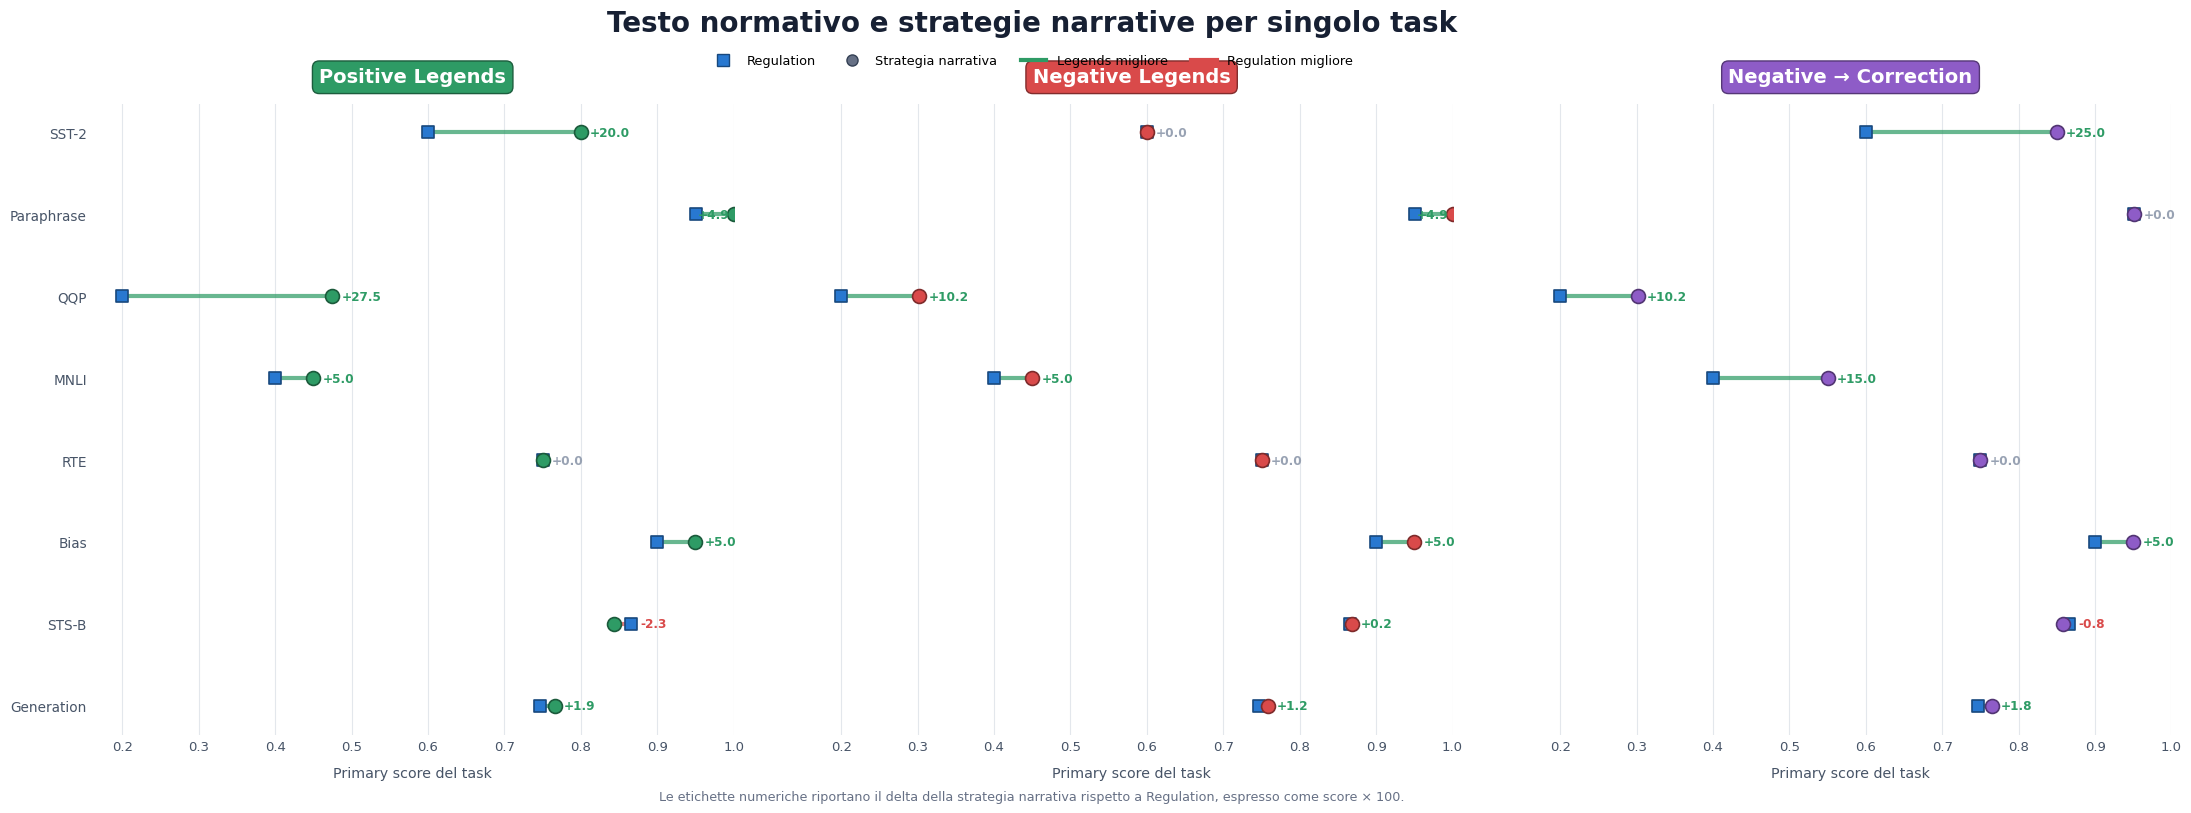

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\05_regulation_vs_legends\01_regulation_vs_legends_task_dumbbell.png


In [109]:
# CELLA 30 — Confronta Regulation e le tre strategie narrative
# sui singoli task tramite dumbbell chart.
#
# Quadrato blu:
#     score di Regulation.
#
# Cerchio colorato:
#     score della strategia narrativa.
#
# Il valore a destra indica il delta:
#     Legends - Regulation.

regulation_vs_legends_rows = []


for legend_model in LEGEND_MODELS:

    for task_name in BLOCK_3_TASK_ORDER:

        regulation_score = float(
            primary_score_matrix_df.loc[
                "regulation",
                task_name,
            ]
        )


        legend_score = float(
            primary_score_matrix_df.loc[
                legend_model,
                task_name,
            ]
        )


        regulation_vs_legends_rows.append({
            "legend_model": legend_model,
            "task_name": task_name,
            "regulation_score": regulation_score,
            "legend_score": legend_score,
            "delta_score": (
                legend_score
                - regulation_score
            ),
        })


regulation_vs_legends_task_df = (
    pd.DataFrame(
        regulation_vs_legends_rows
    )
)


regulation_vs_legends_task_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "regulation_vs_legends_by_task.csv",
    index=False,
    encoding="utf-8-sig",
)


all_comparison_scores = (
    regulation_vs_legends_task_df[
        [
            "regulation_score",
            "legend_score",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


x_axis_minimum = max(
    0.0,
    float(
        all_comparison_scores.min()
    )
    - 0.04,
)


x_axis_maximum = min(
    1.0,
    float(
        all_comparison_scores.max()
    )
    + 0.07,
)


figure, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(
        23.5,
        8.2,
    ),
    sharex=True,
    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


y_positions = np.arange(
    len(
        BLOCK_3_TASK_ORDER
    )
)


for axis, legend_model in zip(
    axes,
    LEGEND_MODELS,
):

    model_plot_df = (
        regulation_vs_legends_task_df[
            regulation_vs_legends_task_df[
                "legend_model"
            ]
            == legend_model
        ]
        .set_index(
            "task_name"
        )
        .reindex(
            BLOCK_3_TASK_ORDER
        )
        .reset_index()
    )


    model_color = MODEL_COLORS[
        legend_model
    ]


    for row_index, row in model_plot_df.iterrows():

        regulation_score = float(
            row[
                "regulation_score"
            ]
        )


        legend_score = float(
            row[
                "legend_score"
            ]
        )


        delta_score = float(
            row[
                "delta_score"
            ]
        )


        connector_color = (
            "#2E9B65"
            if delta_score > PAIR_TOLERANCE
            else (
                "#D94A4A"
                if delta_score < -PAIR_TOLERANCE
                else "#98A2B3"
            )
        )


        axis.plot(
            [
                regulation_score,
                legend_score,
            ],
            [
                row_index,
                row_index,
            ],
            color=connector_color,
            linewidth=3.0,
            alpha=0.72,
            solid_capstyle="round",
            zorder=2,
        )


        axis.scatter(
            regulation_score,
            row_index,
            s=86,
            marker="s",
            facecolor="#2878D0",
            edgecolor=darken_color(
                "#2878D0",
                0.40,
            ),
            linewidth=1.2,
            zorder=4,
        )


        axis.scatter(
            legend_score,
            row_index,
            s=100,
            marker="o",
            facecolor=model_color,
            edgecolor=darken_color(
                model_color,
                0.42,
            ),
            linewidth=1.2,
            zorder=5,
        )


        label_x = min(
            max(
                regulation_score,
                legend_score,
            )
            + 0.012,
            x_axis_maximum
            - 0.005,
        )


        axis.text(
            label_x,
            row_index,
            f"{delta_score * 100:+.1f}",
            ha=(
                "right"
                if label_x
                >= x_axis_maximum
                - 0.006
                else "left"
            ),
            va="center",
            fontsize=8.7,
            fontweight="bold",
            color=connector_color,
            zorder=6,
        )


    axis.set_xlim(
        x_axis_minimum,
        x_axis_maximum,
    )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        [
            TASK_DISPLAY_NAMES[
                task_name
            ]
            for task_name
            in BLOCK_3_TASK_ORDER
        ],
        fontsize=9.8,
        color="#344054",
    )


    axis.invert_yaxis()


    axis.set_xlabel(
        "Primary score del task",
        fontsize=10.3,
        color="#475467",
        labelpad=10,
    )


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            legend_model
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=15,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


figure.suptitle(
    "Testo normativo e strategie narrative per singolo task",
    fontsize=20,
    fontweight="bold",
    color="#172033",
    y=0.985,
)


legend_handles = [
    Line2D(
        [0],
        [0],
        marker="s",
        color="none",
        markerfacecolor="#2878D0",
        markeredgecolor=darken_color(
            "#2878D0",
            0.40,
        ),
        markersize=8,
        label="Regulation",
    ),

    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#667085",
        markeredgecolor="#344054",
        markersize=8,
        label="Strategia narrativa",
    ),

    Line2D(
        [0],
        [0],
        color="#2E9B65",
        linewidth=3,
        label="Legends migliore",
    ),

    Line2D(
        [0],
        [0],
        color="#D94A4A",
        linewidth=3,
        label="Regulation migliore",
    ),
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.944,
    ),
    ncol=4,
    frameon=False,
    fontsize=9.3,
    columnspacing=1.8,
)


figure.text(
    0.5,
    0.025,
    (
        "Le etichette numeriche riportano il delta "
        "della strategia narrativa rispetto a Regulation, "
        "espresso come score × 100."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.10,
    right=0.985,
    top=0.87,
    bottom=0.10,
    wspace=0.12,
)


save_figure(
    figure,
    COMPARISON_PLOTS_DIR
    / "01_regulation_vs_legends_task_dumbbell.png",
)

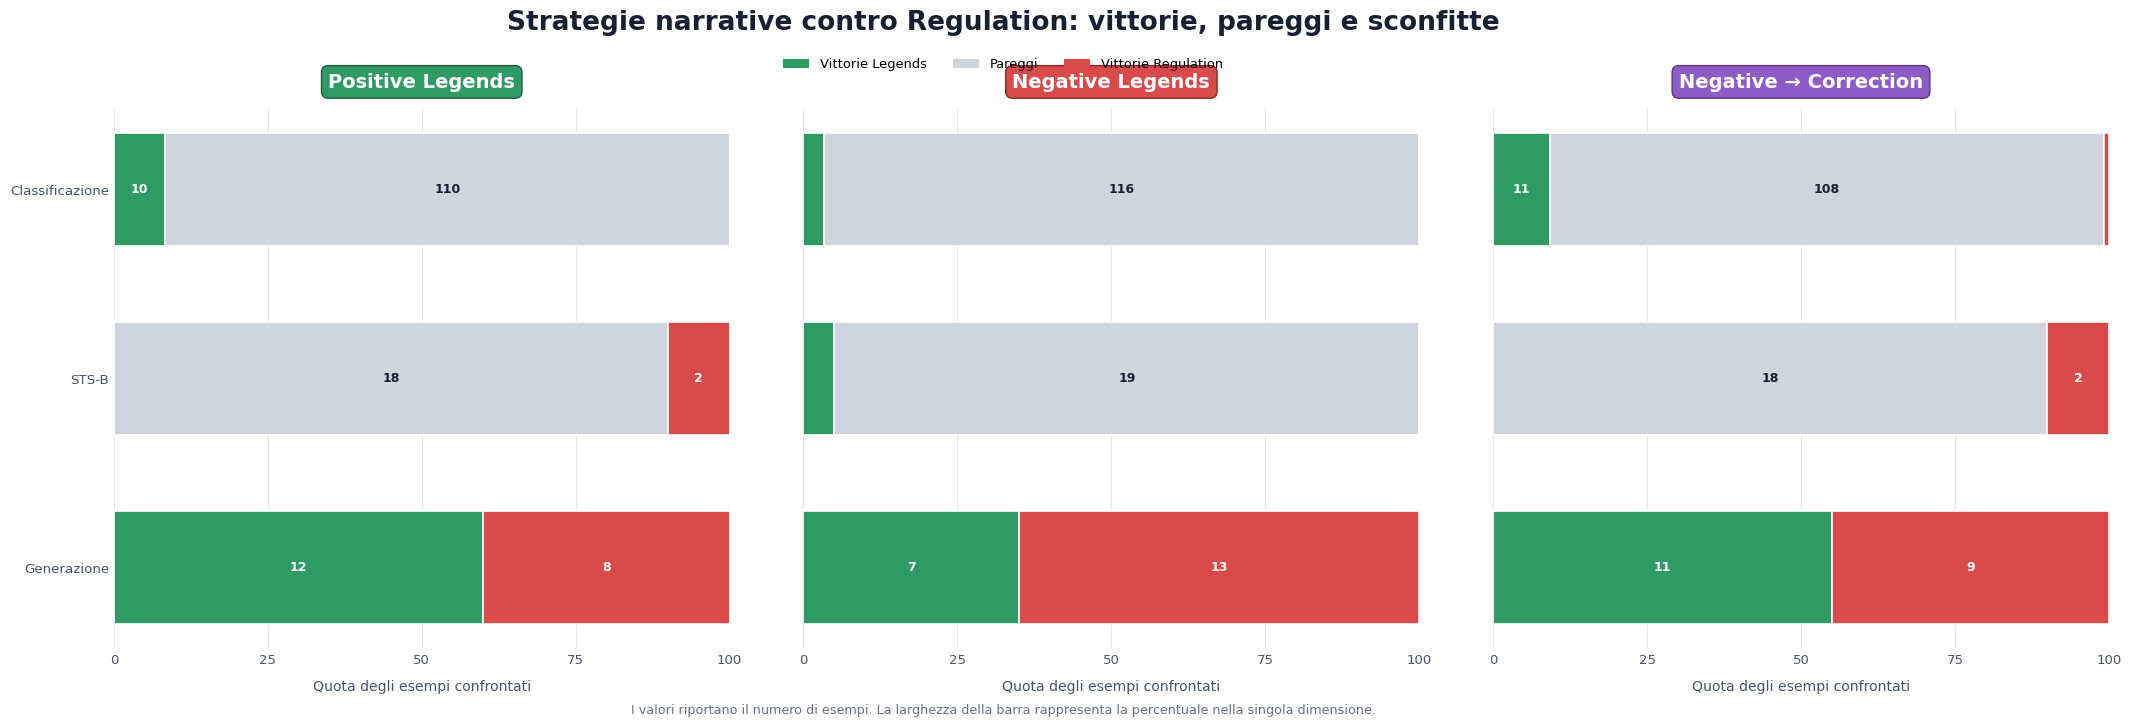

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\05_regulation_vs_legends\02_regulation_vs_legends_win_tie_loss.png


In [110]:
# CELLA 31 — Costruisce il confronto vittorie, pareggi e sconfitte
# delle strategie narrative rispetto a Regulation.
#
# I confronti sono appaiati per example_id e separati per:
# - classificazione;
# - STS-B;
# - generazione automatica tramite BERTScore F1.

REGULATION_COMPARISON_TOLERANCE = (
    PAIR_TOLERANCE
)


regulation_pairwise_rows = []


def append_win_tie_loss_summary(
    legend_model,
    evaluation_dimension,
    outcomes,
):
    """
    Aggiunge una sintesi vittorie, pareggi e sconfitte.
    """

    outcomes_series = pd.Series(
        outcomes
    )


    wins = int(
        (
            outcomes_series
            == "win"
        ).sum()
    )


    ties = int(
        (
            outcomes_series
            == "tie"
        ).sum()
    )


    losses = int(
        (
            outcomes_series
            == "loss"
        ).sum()
    )


    total = (
        wins
        + ties
        + losses
    )


    regulation_pairwise_rows.append({
        "legend_model": legend_model,

        "evaluation_dimension": (
            evaluation_dimension
        ),

        "wins": wins,

        "ties": ties,

        "losses": losses,

        "total": total,

        "win_rate": (
            wins
            / total
            if total > 0
            else np.nan
        ),

        "tie_rate": (
            ties
            / total
            if total > 0
            else np.nan
        ),

        "loss_rate": (
            losses
            / total
            if total > 0
            else np.nan
        ),
    })


for legend_model in LEGEND_MODELS:

    # ================================================================
    # CLASSIFICAZIONE
    # ================================================================

    regulation_classification_df = (
        classification_results_df[
            classification_results_df[
                "model_name"
            ]
            == "regulation"
        ][
            [
                "task_name",
                "example_id",
                "is_correct",
            ]
        ]
        .rename(
            columns={
                "is_correct": (
                    "regulation_is_correct"
                ),
            }
        )
    )


    legend_classification_df = (
        classification_results_df[
            classification_results_df[
                "model_name"
            ]
            == legend_model
        ][
            [
                "task_name",
                "example_id",
                "is_correct",
            ]
        ]
        .rename(
            columns={
                "is_correct": (
                    "legend_is_correct"
                ),
            }
        )
    )


    classification_comparison_df = (
        regulation_classification_df
        .merge(
            legend_classification_df,
            on=[
                "task_name",
                "example_id",
            ],
            how="inner",
            validate="one_to_one",
        )
    )


    classification_outcomes = np.select(
        [
            (
                classification_comparison_df[
                    "legend_is_correct"
                ]
                & ~classification_comparison_df[
                    "regulation_is_correct"
                ]
            ),

            (
                ~classification_comparison_df[
                    "legend_is_correct"
                ]
                & classification_comparison_df[
                    "regulation_is_correct"
                ]
            ),
        ],

        [
            "win",
            "loss",
        ],

        default="tie",
    )


    append_win_tie_loss_summary(
        legend_model=legend_model,
        evaluation_dimension="Classificazione",
        outcomes=classification_outcomes,
    )


    # ================================================================
    # STS-B
    # ================================================================

    regulation_stsb_df = (
        stsb_results_df[
            stsb_results_df[
                "model_name"
            ]
            == "regulation"
        ][
            [
                "example_id",
                "absolute_error",
            ]
        ]
        .rename(
            columns={
                "absolute_error": (
                    "regulation_absolute_error"
                ),
            }
        )
    )


    legend_stsb_df = (
        stsb_results_df[
            stsb_results_df[
                "model_name"
            ]
            == legend_model
        ][
            [
                "example_id",
                "absolute_error",
            ]
        ]
        .rename(
            columns={
                "absolute_error": (
                    "legend_absolute_error"
                ),
            }
        )
    )


    stsb_comparison_df = (
        regulation_stsb_df
        .merge(
            legend_stsb_df,
            on="example_id",
            how="inner",
            validate="one_to_one",
        )
    )


    stsb_delta_error = (
        stsb_comparison_df[
            "regulation_absolute_error"
        ]
        - stsb_comparison_df[
            "legend_absolute_error"
        ]
    )


    stsb_outcomes = np.select(
        [
            (
                stsb_delta_error
                > REGULATION_COMPARISON_TOLERANCE
            ),

            (
                stsb_delta_error
                < -REGULATION_COMPARISON_TOLERANCE
            ),
        ],

        [
            "win",
            "loss",
        ],

        default="tie",
    )


    append_win_tie_loss_summary(
        legend_model=legend_model,
        evaluation_dimension="STS-B",
        outcomes=stsb_outcomes,
    )


    # ================================================================
    # GENERAZIONE
    # ================================================================

    regulation_generation_df = (
        generation_analysis_df[
            generation_analysis_df[
                "model_name"
            ]
            == "regulation"
        ][
            [
                "example_id",
                "bertscore_f1",
            ]
        ]
        .rename(
            columns={
                "bertscore_f1": (
                    "regulation_bertscore_f1"
                ),
            }
        )
    )


    legend_generation_df = (
        generation_analysis_df[
            generation_analysis_df[
                "model_name"
            ]
            == legend_model
        ][
            [
                "example_id",
                "bertscore_f1",
            ]
        ]
        .rename(
            columns={
                "bertscore_f1": (
                    "legend_bertscore_f1"
                ),
            }
        )
    )


    generation_comparison_df = (
        regulation_generation_df
        .merge(
            legend_generation_df,
            on="example_id",
            how="inner",
            validate="one_to_one",
        )
    )


    generation_delta = (
        generation_comparison_df[
            "legend_bertscore_f1"
        ]
        - generation_comparison_df[
            "regulation_bertscore_f1"
        ]
    )


    generation_outcomes = np.select(
        [
            (
                generation_delta
                > REGULATION_COMPARISON_TOLERANCE
            ),

            (
                generation_delta
                < -REGULATION_COMPARISON_TOLERANCE
            ),
        ],

        [
            "win",
            "loss",
        ],

        default="tie",
    )


    append_win_tie_loss_summary(
        legend_model=legend_model,
        evaluation_dimension="Generazione",
        outcomes=generation_outcomes,
    )


# =====================================================================
# DATAFRAME FINALE
# =====================================================================

regulation_pairwise_summary_df = (
    pd.DataFrame(
        regulation_pairwise_rows
    )
)


regulation_pairwise_summary_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "regulation_vs_legends_win_tie_loss.csv",
    index=False,
    encoding="utf-8-sig",
)


evaluation_dimension_order = [
    "Classificazione",
    "STS-B",
    "Generazione",
]


# =====================================================================
# GRAFICO
# =====================================================================

figure, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(
        22.8,
        7.3,
    ),
    sharex=True,
    sharey=True,
)


figure.patch.set_facecolor(
    "white"
)


WIN_TIE_LOSS_COLORS = {
    "wins": "#2E9B65",
    "ties": "#D0D5DD",
    "losses": "#D94A4A",
}


for axis, legend_model in zip(
    axes,
    LEGEND_MODELS,
):

    model_plot_df = (
        regulation_pairwise_summary_df[
            regulation_pairwise_summary_df[
                "legend_model"
            ]
            == legend_model
        ]
        .set_index(
            "evaluation_dimension"
        )
        .reindex(
            evaluation_dimension_order
        )
        .reset_index()
    )


    y_positions = np.arange(
        len(
            evaluation_dimension_order
        )
    )


    left_percentages = np.zeros(
        len(
            model_plot_df
        ),
        dtype=float,
    )


    for value_column in [
        "wins",
        "ties",
        "losses",
    ]:

        counts = (
            model_plot_df[
                value_column
            ]
            .to_numpy(
                dtype=float
            )
        )


        totals = (
            model_plot_df[
                "total"
            ]
            .to_numpy(
                dtype=float
            )
        )


        percentages = (
            counts
            / totals
            * 100.0
        )


        bars = axis.barh(
            y_positions,
            percentages,
            left=left_percentages,
            height=0.60,
            color=WIN_TIE_LOSS_COLORS[
                value_column
            ],
            edgecolor="white",
            linewidth=1.2,
            zorder=3,
        )


        for (
            bar,
            percentage,
            count,
            left_percentage,
        ) in zip(
            bars,
            percentages,
            counts,
            left_percentages,
        ):

            if percentage < 8:
                continue


            axis.text(
                left_percentage
                + percentage
                / 2,
                bar.get_y()
                + bar.get_height()
                / 2,
                str(
                    int(
                        count
                    )
                ),
                ha="center",
                va="center",
                fontsize=9.0,
                fontweight="bold",
                color=(
                    "#172033"
                    if value_column
                    == "ties"
                    else "white"
                ),
                zorder=5,
            )


        left_percentages += percentages


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        evaluation_dimension_order,
        fontsize=9.6,
        color="#344054",
    )


    axis.invert_yaxis()


    axis.set_xlim(
        0,
        100,
    )


    axis.set_xticks(
        [
            0,
            25,
            50,
            75,
            100,
        ]
    )


    axis.set_xlabel(
        "Quota degli esempi confrontati",
        fontsize=10.1,
        color="#475467",
        labelpad=10,
    )


    model_color = MODEL_COLORS[
        legend_model
    ]


    axis.set_title(
        MODEL_DISPLAY_NAMES[
            legend_model
        ],
        fontsize=14,
        fontweight="bold",
        color="white",
        pad=15,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": model_color,
            "edgecolor": darken_color(
                model_color,
                0.40,
            ),
        },
    )


    style_axis(
        axis,
        grid_axis="x",
    )


figure.suptitle(
    "Strategie narrative contro Regulation: vittorie, pareggi e sconfitte",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    y=0.985,
)


legend_handles = [
    Patch(
        facecolor="#2E9B65",
        edgecolor="none",
        label="Vittorie Legends",
    ),

    Patch(
        facecolor="#D0D5DD",
        edgecolor="none",
        label="Pareggi",
    ),

    Patch(
        facecolor="#D94A4A",
        edgecolor="none",
        label="Vittorie Regulation",
    ),
]


figure.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.935,
    ),
    ncol=3,
    frameon=False,
    fontsize=9.4,
    columnspacing=2.0,
)


figure.text(
    0.5,
    0.025,
    (
        "I valori riportano il numero di esempi. "
        "La larghezza della barra rappresenta la percentuale "
        "nella singola dimensione."
    ),
    ha="center",
    va="center",
    fontsize=9.2,
    color="#667085",
)


figure.subplots_adjust(
    left=0.11,
    right=0.985,
    top=0.85,
    bottom=0.11,
    wspace=0.12,
)


save_figure(
    figure,
    COMPARISON_PLOTS_DIR
    / "02_regulation_vs_legends_win_tie_loss.png",
)

In [111]:
# CELLA 32 — Costruisce la scorecard conclusiva del Blocco 3.
#
# La scorecard mantiene separate le dimensioni:
# - task migliorati o peggiorati;
# - classificazione;
# - STS-B;
# - generazione.
#
# Non viene creato un punteggio unico mediante
# la somma di metriche incompatibili.

task_balance_indexed_df = (
    task_balance_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
)


classification_effect_indexed_df = (
    classification_aggregate_effect_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
)


stsb_effect_indexed_df = (
    stsb_effect_summary_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
)


generation_effect_indexed_df = (
    generation_effect_summary_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
)


block_3_scorecard_rows = []


for adapter_name in ADAPTER_MODELS:

    task_row = (
        task_balance_indexed_df.loc[
            adapter_name
        ]
    )


    classification_row = (
        classification_effect_indexed_df.loc[
            adapter_name
        ]
    )


    stsb_row = (
        stsb_effect_indexed_df.loc[
            adapter_name
        ]
    )


    generation_row = (
        generation_effect_indexed_df.loc[
            adapter_name
        ]
    )


    automatic_improvements = (
        int(
            classification_row[
                "gain"
            ]
        )
        + int(
            stsb_row[
                "improved_count"
            ]
        )
        + int(
            generation_row[
                "improved_count"
            ]
        )
    )


    automatic_regressions = (
        int(
            classification_row[
                "regression"
            ]
        )
        + int(
            stsb_row[
                "worsened_count"
            ]
        )
        + int(
            generation_row[
                "worsened_count"
            ]
        )
    )


    block_3_scorecard_rows.append({
        "adapter_name": adapter_name,

        "task_improved": int(
            task_row[
                "improved"
            ]
        ),

        "task_tied": int(
            task_row[
                "tied"
            ]
        ),

        "task_worsened": int(
            task_row[
                "worsened"
            ]
        ),

        "classification_gains": int(
            classification_row[
                "gain"
            ]
        ),

        "classification_regressions": int(
            classification_row[
                "regression"
            ]
        ),

        "classification_net_gain": int(
            classification_row[
                "net_gain"
            ]
        ),

        "stsb_improved": int(
            stsb_row[
                "improved_count"
            ]
        ),

        "stsb_worsened": int(
            stsb_row[
                "worsened_count"
            ]
        ),

        "stsb_net_improvement": int(
            stsb_row[
                "net_improved_examples"
            ]
        ),

        "stsb_mae_reduction": float(
            stsb_row[
                "mae_reduction"
            ]
        ),

        "generation_improved": int(
            generation_row[
                "improved_count"
            ]
        ),

        "generation_worsened": int(
            generation_row[
                "worsened_count"
            ]
        ),

        "generation_net_improvement": int(
            generation_row[
                "net_improvement"
            ]
        ),

        "mean_delta_bertscore_f1": float(
            generation_row[
                "mean_delta_bertscore_f1"
            ]
        ),

        "automatic_improvements_total": (
            automatic_improvements
        ),

        "automatic_regressions_total": (
            automatic_regressions
        ),

        "automatic_net_examples": (
            automatic_improvements
            - automatic_regressions
        ),
    })


block_3_scorecard_df = (
    pd.DataFrame(
        block_3_scorecard_rows
    )
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
    .reset_index()
)


block_3_scorecard_df.to_csv(
    BLOCK_3_TABLES_DIR
    / "block_3_final_scorecard.csv",
    index=False,
    encoding="utf-8-sig",
)


display(
    block_3_scorecard_df.round(
        4
    )
)

,adapter_name,task_improved,task_tied,task_worsened,classification_gains,classification_regressions,classification_net_gain,stsb_improved,stsb_worsened,stsb_net_improvement,stsb_mae_reduction,generation_improved,generation_worsened,generation_net_improvement,mean_delta_bertscore_f1,automatic_improvements_total,automatic_regressions_total,automatic_net_examples
0,regulation,4,3,1,3,3,0,1,0,1,0.05,15,5,10,0.0097,19,8,11
1,positive_legends,7,1,0,11,1,10,1,2,-1,-0.05,15,5,10,0.0289,27,8,19
2,negative_legends,6,1,1,6,2,4,2,0,2,0.10,15,5,10,0.0212,23,7,16
3,negative_to_correction,6,2,0,11,1,10,1,2,-1,-0.05,17,3,14,0.0279,29,6,23


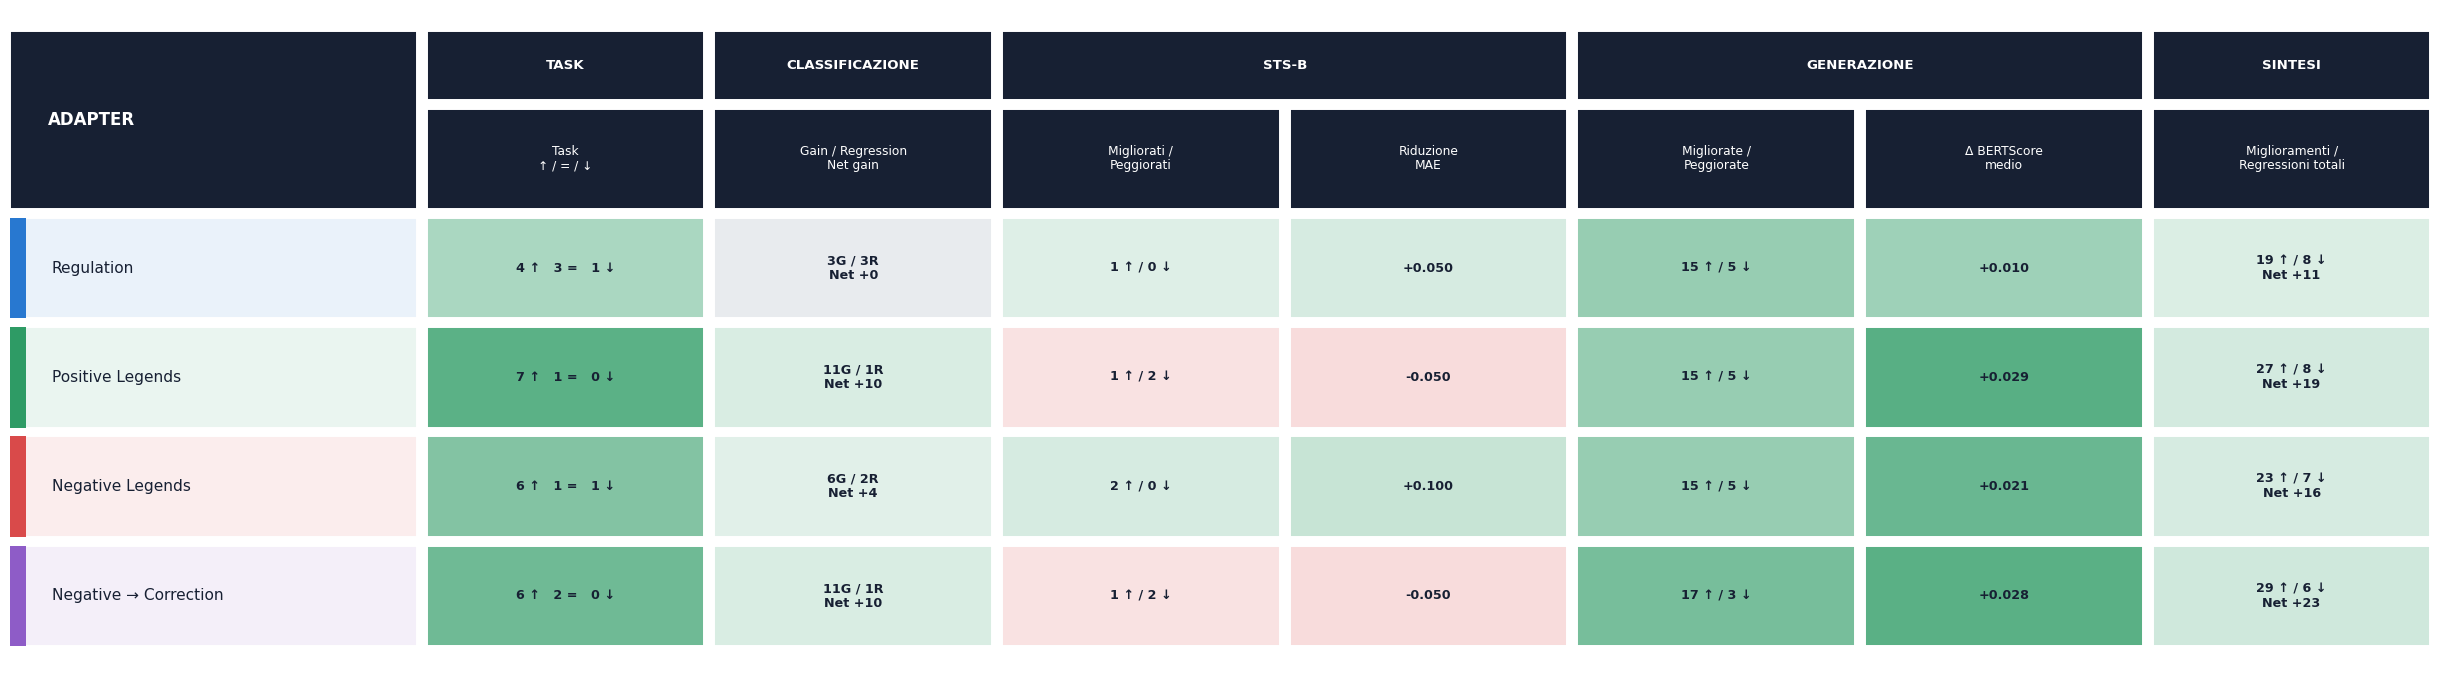

Salvato: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3\06_summary\01_block_3_final_scorecard.png


In [112]:
# CELLA 33 — Genera la scorecard grafica conclusiva
# dell'effetto del fine-tuning.
#
# La tabella riassume le dimensioni analizzate
# senza creare un ranking aggregato artificiale.

def semantic_summary_color(
    quality_value,
):
    """
    Genera un colore divergente:
    - verde per valori positivi;
    - rosso per valori negativi;
    - grigio per valori nulli.
    """

    if pd.isna(
        quality_value
    ):
        return "#F2F4F7"


    quality_value = float(
        np.clip(
            quality_value,
            -1.0,
            1.0,
        )
    )


    if quality_value > PAIR_TOLERANCE:

        return blend_colors(
            "#FFFFFF",
            "#2E9B65",
            0.12
            + 0.76
            * quality_value,
        )


    if quality_value < -PAIR_TOLERANCE:

        return blend_colors(
            "#FFFFFF",
            "#D94A4A",
            0.12
            + 0.76
            * abs(
                quality_value
            ),
        )


    return blend_colors(
        "#FFFFFF",
        "#98A2B3",
        0.22,
    )


# =====================================================================
# COLONNE DELLA SCORECARD
# =====================================================================

summary_columns = [
    {
        "key": "task_balance",
        "label": "Task\n↑ / = / ↓",
        "group": "TASK",
    },

    {
        "key": "classification",
        "label": "Gain / Regression\nNet gain",
        "group": "CLASSIFICAZIONE",
    },

    {
        "key": "stsb_examples",
        "label": "Migliorati /\nPeggiorati",
        "group": "STS-B",
    },

    {
        "key": "stsb_mae",
        "label": "Riduzione\nMAE",
        "group": "STS-B",
    },

    {
        "key": "generation_examples",
        "label": "Migliorate /\nPeggiorate",
        "group": "GENERAZIONE",
    },

    {
        "key": "delta_bert",
        "label": "Δ BERTScore\nmedio",
        "group": "GENERAZIONE",
    },

    {
        "key": "automatic_total",
        "label": "Miglioramenti /\nRegressioni totali",
        "group": "SINTESI",
    },
]


summary_group_definitions = [
    {
        "label": "TASK",
        "start": 0,
        "count": 1,
    },

    {
        "label": "CLASSIFICAZIONE",
        "start": 1,
        "count": 1,
    },

    {
        "label": "STS-B",
        "start": 2,
        "count": 2,
    },

    {
        "label": "GENERAZIONE",
        "start": 4,
        "count": 2,
    },

    {
        "label": "SINTESI",
        "start": 6,
        "count": 1,
    },
]


scorecard_plot_df = (
    block_3_scorecard_df
    .set_index(
        "adapter_name"
    )
    .reindex(
        ADAPTER_MODELS
    )
)


cell_display_values = {}

cell_quality_values = {}


for adapter_name, row in scorecard_plot_df.iterrows():

    # -----------------------------------------------------------------
    # Task migliorati, invariati e peggiorati
    # -----------------------------------------------------------------

    cell_display_values[
        (
            adapter_name,
            "task_balance",
        )
    ] = (
        f"{int(row['task_improved'])} ↑   "
        f"{int(row['task_tied'])} =   "
        f"{int(row['task_worsened'])} ↓"
    )


    cell_quality_values[
        (
            adapter_name,
            "task_balance",
        )
    ] = (
        (
            row[
                "task_improved"
            ]
            - row[
                "task_worsened"
            ]
        )
        / len(
            BLOCK_3_TASK_ORDER
        )
    )


    # -----------------------------------------------------------------
    # Classificazione
    # -----------------------------------------------------------------

    cell_display_values[
        (
            adapter_name,
            "classification",
        )
    ] = (
        f"{int(row['classification_gains'])}G / "
        f"{int(row['classification_regressions'])}R\n"
        f"Net {int(row['classification_net_gain']):+d}"
    )


    cell_quality_values[
        (
            adapter_name,
            "classification",
        )
    ] = (
        row[
            "classification_net_gain"
        ]
        / expected_classification_total
    )


    # -----------------------------------------------------------------
    # STS-B
    # -----------------------------------------------------------------

    cell_display_values[
        (
            adapter_name,
            "stsb_examples",
        )
    ] = (
        f"{int(row['stsb_improved'])} ↑ / "
        f"{int(row['stsb_worsened'])} ↓"
    )


    cell_quality_values[
        (
            adapter_name,
            "stsb_examples",
        )
    ] = (
        row[
            "stsb_net_improvement"
        ]
        / EXPECTED_EXAMPLES_PER_TASK
    )


    cell_display_values[
        (
            adapter_name,
            "stsb_mae",
        )
    ] = (
        f"{row['stsb_mae_reduction']:+.3f}"
    )


    cell_quality_values[
        (
            adapter_name,
            "stsb_mae",
        )
    ] = np.tanh(
        row[
            "stsb_mae_reduction"
        ]
        / 0.50
    )


    # -----------------------------------------------------------------
    # Generazione
    # -----------------------------------------------------------------

    cell_display_values[
        (
            adapter_name,
            "generation_examples",
        )
    ] = (
        f"{int(row['generation_improved'])} ↑ / "
        f"{int(row['generation_worsened'])} ↓"
    )


    cell_quality_values[
        (
            adapter_name,
            "generation_examples",
        )
    ] = (
        row[
            "generation_net_improvement"
        ]
        / EXPECTED_EXAMPLES_PER_TASK
    )


    cell_display_values[
        (
            adapter_name,
            "delta_bert",
        )
    ] = (
        f"{row['mean_delta_bertscore_f1']:+.3f}"
    )


    cell_quality_values[
        (
            adapter_name,
            "delta_bert",
        )
    ] = np.tanh(
        row[
            "mean_delta_bertscore_f1"
        ]
        / 0.02
    )


    # -----------------------------------------------------------------
    # Sintesi automatica
    # -----------------------------------------------------------------

    cell_display_values[
        (
            adapter_name,
            "automatic_total",
        )
    ] = (
        f"{int(row['automatic_improvements_total'])} ↑ / "
        f"{int(row['automatic_regressions_total'])} ↓\n"
        f"Net {int(row['automatic_net_examples']):+d}"
    )


    cell_quality_values[
        (
            adapter_name,
            "automatic_total",
        )
    ] = (
        row[
            "automatic_net_examples"
        ]
        / (
            expected_classification_total
            + EXPECTED_EXAMPLES_PER_TASK
            + EXPECTED_EXAMPLES_PER_TASK
        )
    )


# =====================================================================
# DIMENSIONI
# =====================================================================

model_column_width = 4.20

metric_column_width = 2.90

number_of_metrics = len(
    summary_columns
)

horizontal_gap = 0.10

vertical_gap = 0.08

row_height = 1.02

group_header_height = 0.72

metric_header_height = 1.02

complete_header_height = (
    group_header_height
    + metric_header_height
)

bottom_margin = 0.25

top_margin = 0.12


total_width = (
    model_column_width
    + number_of_metrics
    * metric_column_width
)


total_height = (
    bottom_margin
    + len(
        ADAPTER_MODELS
    )
    * row_height
    + complete_header_height
    + top_margin
)


figure, axis = plt.subplots(
    figsize=(
        24.5,
        6.8,
    )
)


figure.patch.set_facecolor(
    "white"
)


axis.set_facecolor(
    "white"
)


axis.set_xlim(
    0,
    total_width,
)


axis.set_ylim(
    0,
    total_height,
)


axis.axis(
    "off"
)


rows_bottom = bottom_margin


header_bottom = (
    rows_bottom
    + len(
        ADAPTER_MODELS
    )
    * row_height
)


metric_header_bottom = (
    header_bottom
)


group_header_bottom = (
    metric_header_bottom
    + metric_header_height
)


header_color = "#172033"


# =====================================================================
# HEADER ADAPTER
# =====================================================================

axis.add_patch(
    Rectangle(
        (
            0,
            header_bottom,
        ),
        model_column_width
        - horizontal_gap,
        complete_header_height
        - vertical_gap,
        facecolor=header_color,
        edgecolor="white",
        linewidth=1.4,
    )
)


axis.text(
    0.38,
    header_bottom
    + (
        complete_header_height
        - vertical_gap
    )
    / 2,
    "ADAPTER",
    ha="left",
    va="center",
    fontsize=12,
    fontweight="bold",
    color="white",
)


# =====================================================================
# HEADER RAGGRUPPATI
# =====================================================================

for group_definition in summary_group_definitions:

    group_x = (
        model_column_width
        + group_definition[
            "start"
        ]
        * metric_column_width
    )


    group_width = (
        group_definition[
            "count"
        ]
        * metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            (
                group_x,
                group_header_bottom,
            ),
            group_width,
            group_header_height
            - vertical_gap,
            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        group_x
        + group_width
        / 2,
        group_header_bottom
        + (
            group_header_height
            - vertical_gap
        )
        / 2,
        group_definition[
            "label"
        ],
        ha="center",
        va="center",
        fontsize=9.6,
        fontweight="bold",
        color="white",
    )


# =====================================================================
# HEADER DELLE METRICHE
# =====================================================================

for column_index, column_definition in enumerate(
    summary_columns
):

    cell_x = (
        model_column_width
        + column_index
        * metric_column_width
    )


    cell_width = (
        metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            (
                cell_x,
                metric_header_bottom,
            ),
            cell_width,
            metric_header_height
            - vertical_gap,
            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        cell_x
        + cell_width
        / 2,
        metric_header_bottom
        + (
            metric_header_height
            - vertical_gap
        )
        / 2,
        column_definition[
            "label"
        ],
        ha="center",
        va="center",
        fontsize=8.8,
        fontweight="medium",
        color="white",
        linespacing=1.08,
        multialignment="center",
    )


# =====================================================================
# RIGHE
# =====================================================================

for row_index, adapter_name in enumerate(
    ADAPTER_MODELS
):

    row_bottom = (
        rows_bottom
        + (
            len(
                ADAPTER_MODELS
            )
            - 1
            - row_index
        )
        * row_height
    )


    model_color = MODEL_COLORS[
        adapter_name
    ]


    model_background = blend_colors(
        "#FFFFFF",
        model_color,
        0.10,
    )


    axis.add_patch(
        Rectangle(
            (
                0,
                row_bottom,
            ),
            model_column_width
            - horizontal_gap,
            row_height
            - vertical_gap,
            facecolor=model_background,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.add_patch(
        Rectangle(
            (
                0,
                row_bottom,
            ),
            0.16,
            row_height
            - vertical_gap,
            facecolor=model_color,
            edgecolor="none",
        )
    )


    axis.text(
        0.42,
        row_bottom
        + (
            row_height
            - vertical_gap
        )
        / 2,
        MODEL_DISPLAY_NAMES[
            adapter_name
        ],
        ha="left",
        va="center",
        fontsize=11.1,
        fontweight="medium",
        color="#172033",
    )


    for column_index, column_definition in enumerate(
        summary_columns
    ):

        column_key = (
            column_definition[
                "key"
            ]
        )


        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        quality_value = (
            cell_quality_values[
                (
                    adapter_name,
                    column_key,
                )
            ]
        )


        cell_facecolor = (
            semantic_summary_color(
                quality_value
            )
        )


        axis.add_patch(
            Rectangle(
                (
                    cell_x,
                    row_bottom,
                ),
                cell_width,
                row_height
                - vertical_gap,
                facecolor=cell_facecolor,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,
            cell_display_values[
                (
                    adapter_name,
                    column_key,
                )
            ],
            ha="center",
            va="center",
            fontsize=9.2,
            fontweight="bold",
            color=contrast_text_color(
                cell_facecolor
            ),
            linespacing=1.14,
            multialignment="center",
        )


figure.subplots_adjust(
    left=0.006,
    right=0.998,
    top=0.99,
    bottom=0.015,
)


save_figure(
    figure,
    SUMMARY_PLOTS_DIR
    / "01_block_3_final_scorecard.png",
)

In [113]:
# CELLA 34 — Esegue il controllo finale del notebook
# e salva un manifest degli artefatti prodotti.
#
# Verifica:
# - presenza delle tabelle principali;
# - presenza dei grafici principali;
# - numero di modelli, task ed esempi;
# - assenza degli output obsoleti della valutazione umana;
# - coerenza delle sintesi finali.

from datetime import datetime, timezone


# =====================================================================
# CONTROLLI SUI DATAFRAME PRINCIPALI
# =====================================================================

expected_pairwise_counts = {
    "classification_pairwise": (
        len(
            ADAPTER_MODELS
        )
        * expected_classification_total
    ),

    "stsb_pairwise": (
        len(
            ADAPTER_MODELS
        )
        * EXPECTED_EXAMPLES_PER_TASK
    ),

    "generation_pairwise": (
        len(
            ADAPTER_MODELS
        )
        * EXPECTED_EXAMPLES_PER_TASK
    ),
}


actual_pairwise_counts = {
    "classification_pairwise": len(
        classification_pairwise_df
    ),

    "stsb_pairwise": len(
        stsb_pairwise_df
    ),

    "generation_pairwise": len(
        generation_pairwise_df
    ),
}


for dataframe_name, expected_count in (
    expected_pairwise_counts.items()
):

    actual_count = (
        actual_pairwise_counts[
            dataframe_name
        ]
    )


    if actual_count != expected_count:

        raise RuntimeError(
            f"{dataframe_name}: attese "
            f"{expected_count} righe, trovate "
            f"{actual_count}."
        )


if len(
    block_3_scorecard_df
) != len(
    ADAPTER_MODELS
):

    raise RuntimeError(
        "La scorecard finale non contiene "
        "tutti gli adapter."
    )


# =====================================================================
# FILE OBBLIGATORI
# =====================================================================

required_output_paths = [
    BLOCK_3_TABLES_DIR
    / "delta_vs_base_by_task.csv",

    BLOCK_3_TABLES_DIR
    / "classification_pairwise_vs_base.csv",

    BLOCK_3_TABLES_DIR
    / "classification_effect_aggregate.csv",

    BLOCK_3_TABLES_DIR
    / "classification_effect_by_task.csv",

    BLOCK_3_TABLES_DIR
    / "classification_error_transitions.csv",

    BLOCK_3_TABLES_DIR
    / "stsb_pairwise_vs_base.csv",

    BLOCK_3_TABLES_DIR
    / "stsb_effect_summary.csv",

    BLOCK_3_TABLES_DIR
    / "generation_pairwise_vs_base.csv",

    BLOCK_3_TABLES_DIR
    / "generation_effect_summary.csv",

    BLOCK_3_TABLES_DIR
    / "representative_error_analysis_cases.csv",

    BLOCK_3_TABLES_DIR
    / "regulation_vs_legends_by_task.csv",

    BLOCK_3_TABLES_DIR
    / "regulation_vs_legends_win_tie_loss.csv",

    BLOCK_3_TABLES_DIR
    / "block_3_final_scorecard.csv",

    OVERVIEW_PLOTS_DIR
    / "01_delta_vs_base_heatmap.png",

    OVERVIEW_PLOTS_DIR
    / "02_delta_vs_base_profiles.png",

    CLASSIFICATION_PLOTS_DIR
    / "01_classification_gain_regression_aggregate.png",

    CLASSIFICATION_PLOTS_DIR
    / "02_classification_net_gain_matrix.png",

    CLASSIFICATION_PLOTS_DIR
    / "03_classification_net_gain_profiles.png",

    CLASSIFICATION_PLOTS_DIR
    / "04_classification_error_transition_profiles.png",

    CLASSIFICATION_PLOTS_DIR
    / "05_classification_error_transition_dumbbell.png",

    STSB_PLOTS_DIR
    / "01_stsb_improved_worsened_vs_base.png",

    STSB_PLOTS_DIR
    / "02_stsb_absolute_error_delta_distribution.png",

    GENERATION_PLOTS_DIR
    / "01_generation_improved_worsened_vs_base.png",

    COMPARISON_PLOTS_DIR
    / "01_regulation_vs_legends_task_dumbbell.png",

    COMPARISON_PLOTS_DIR
    / "02_regulation_vs_legends_win_tie_loss.png",

    SUMMARY_PLOTS_DIR
    / "01_block_3_final_scorecard.png",
]


missing_output_paths = [
    output_path
    for output_path
    in required_output_paths
    if not output_path.exists()
]


if missing_output_paths:

    raise FileNotFoundError(
        "Mancano alcuni artefatti finali:\n- "
        + "\n- ".join(
            str(
                output_path
            )
            for output_path
            in missing_output_paths
        )
    )


# =====================================================================
# CONTROLLO DEGLI OUTPUT OBSOLETI
# =====================================================================

obsolete_human_evaluation_paths = [
    BLOCK_3_TABLES_DIR
    / "subjective_by_example.csv",

    BLOCK_3_TABLES_DIR
    / "generation_automatic_human_agreement.csv",

    GENERATION_PLOTS_DIR
    / "02_generation_automatic_human_agreement.png",
]


remaining_obsolete_paths = [
    obsolete_path
    for obsolete_path
    in obsolete_human_evaluation_paths
    if obsolete_path.exists()
]


if remaining_obsolete_paths:

    raise RuntimeError(
        "Sono ancora presenti output obsoleti "
        "della valutazione umana:\n- "
        + "\n- ".join(
            str(
                obsolete_path
            )
            for obsolete_path
            in remaining_obsolete_paths
        )
    )


# =====================================================================
# MANIFEST
# =====================================================================

block_3_manifest = {
    "generated_at_utc": (
        datetime.now(
            timezone.utc
        ).isoformat()
    ),

    "project_root": str(
        PROJECT_ROOT
    ),

    "base_model": BASE_MODEL,

    "adapter_models": (
        ADAPTER_MODELS
    ),

    "classification_tasks": (
        CLASSIFICATION_TASKS
    ),

    "stsb_task": STSB_TASK,

    "generation_task": (
        GENERATION_TASK
    ),

    "task_count": len(
        BLOCK_3_TASK_ORDER
    ),

    "classification_examples_per_model": (
        expected_classification_total
    ),

    "stsb_examples_per_model": (
        EXPECTED_EXAMPLES_PER_TASK
    ),

    "generation_examples_per_model": (
        EXPECTED_EXAMPLES_PER_TASK
    ),

    "generation_metrics_available": (
        available_generation_metrics
    ),

    "human_evaluation_included": False,

    "pairwise_rows": (
        actual_pairwise_counts
    ),

    "representative_cases": int(
        len(
            representative_cases_df
        )
    ),

    "output_files": [
        str(
            output_path
        )
        for output_path
        in required_output_paths
    ],
}


manifest_path = (
    BLOCK_3_TABLES_DIR
    / "block_3_manifest.json"
)


with manifest_path.open(
    "w",
    encoding="utf-8",
) as manifest_file:

    json.dump(
        block_3_manifest,
        manifest_file,
        ensure_ascii=False,
        indent=2,
    )


# =====================================================================
# OUTPUT FINALE
# =====================================================================

print(
    "Blocco 3 completato correttamente."
)

print()


print(
    "Adapter analizzati:",
    len(
        ADAPTER_MODELS
    ),
)


print(
    "Task analizzati:",
    len(
        BLOCK_3_TASK_ORDER
    ),
)


print(
    "Confronti classificatori:",
    len(
        classification_pairwise_df
    ),
)


print(
    "Confronti STS-B:",
    len(
        stsb_pairwise_df
    ),
)


print(
    "Confronti generativi:",
    len(
        generation_pairwise_df
    ),
)


print(
    "Valutazione umana inclusa:",
    False,
)


print(
    "Casi rappresentativi selezionati:",
    len(
        representative_cases_df
    ),
)


print()


print(
    "Tabelle:",
    BLOCK_3_TABLES_DIR,
)


print(
    "Grafici:",
    BLOCK_3_PLOTS_DIR,
)


print(
    "Manifest:",
    manifest_path,
)

Blocco 3 completato correttamente.

Adapter analizzati: 4
Task analizzati: 8
Confronti classificatori: 480
Confronti STS-B: 80
Confronti generativi: 80
Valutazione umana inclusa: False
Casi rappresentativi selezionati: 5

Tabelle: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_3
Grafici: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\visualizations\block_3
Manifest: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\final_tables\block_3\block_3_manifest.json


Valutazione della ridondanza
1. Heatmap dei delta vs profili dei delta

File:

01_delta_vs_base_heatmap.png
02_delta_vs_base_profiles.png

Fortemente ridondanti.

Mostrano gli stessi delta adapter meno Base sugli stessi otto task. Cambia esclusivamente la rappresentazione:

heatmap: confronto trasversale più compatto;
profili: lettura più comoda del singolo adapter.

In presentazione ne terrei uno solo. La heatmap è più efficace per confrontare i modelli; i profili sono migliori per spiegare un adapter alla volta.

2. Gains/regressions aggregati vs net gain per task

File:

01_classification_gain_regression_aggregate.png
02_classification_net_gain_matrix.png
03_classification_net_gain_profiles.png

Il primo non è ridondante con gli altri due:

il grafico aggregato mostra il comportamento sui 120 esempi;
gli altri mostrano dove avviene il beneficio nei sei task.

La matrice e i profili task-level sono invece fortemente ridondanti tra loro. Anche qui cambia solo la vista.

Scelta razionale:

mantenere sempre il grafico aggregato;
scegliere uno tra matrice e profili task-level.
3. Transizioni di errore: barre divergenti vs dumbbell

File:

04_classification_error_transition_profiles.png
05_classification_error_transition_dumbbell.png

Fortemente ridondanti.

Entrambi mostrano le stesse tipologie di errore modificate.

La differenza è:

barre divergenti: comunicano immediatamente quali errori diminuiscono o aumentano;
dumbbell: mostra esplicitamente il passaggio dal numero di errori Base al numero di errori adapter.

Per una slide sceglierei le barre divergenti. Il dumbbell è più analitico e può rimanere come backup o appendice.

4. STS-B aggregato vs distribuzione per esempio

File:

01_stsb_improved_worsened_vs_base.png
02_stsb_absolute_error_delta_distribution.png

Parzialmente ridondanti, ma il cambio di vista è significativo.

Entrambi mostrano quanti esempi migliorano o peggiorano. Il secondo aggiunge però:

intensità del miglioramento;
intensità del peggioramento;
distribuzione sui 20 casi;
eventuali outlier.

Il primo aggiunge invece:

variazione del MAE;
variazione del RMSE;
cambiamento del bias.

Per la presentazione principale manterrei il primo. Il secondo è una buona slide di approfondimento o appendice.

5. Generazione migliorata/peggiorata

File:

01_generation_improved_worsened_vs_base.png

Non ridondante all’interno del Blocco 3.

Riprende BERTScore già presentato nel Blocco 2, ma cambia la domanda:

Blocco 2: quale modello ha il BERTScore medio migliore?
Blocco 3: su quante singole risposte l’adapter migliora o peggiora rispetto alla Base?

È un cambio di vista sostanziale e va mantenuto.

6. Regulation vs Legends: primary score vs vittorie appaiate

File:

01_regulation_vs_legends_task_dumbbell.png
02_regulation_vs_legends_win_tie_loss.png

Complementari, non realmente ridondanti.

Il primo mostra:

differenza media delle prestazioni;
dettaglio per singolo task.

Il secondo mostra:

frequenza con cui una strategia narrativa batte Regulation;
stabilità del vantaggio sui singoli esempi.

Un modello può avere uno score medio più alto ma vincere soltanto su pochi esempi con margine elevato. Tenere entrambi ha senso.

7. Scorecard finale

File:

01_block_3_final_scorecard.png

La scorecard ripete inevitabilmente numeri già presenti nei grafici precedenti, ma la ridondanza è funzionale: serve come sintesi conclusiva.

Non la userei per introdurre nuovi risultati. Va posizionata alla fine per ricapitolare:

task migliorati;
net gain classificatorio;
andamento STS-B;
generazione;
regressioni complessive.
Set minimo consigliato per la presentazione

Per evitare ripetizioni terrei:

Heatmap dei delta rispetto alla Base.
Gains e regressions aggregati della classificazione.
Una sola vista del net gain per task.
Una sola vista delle transizioni di errore.
STS-B migliorati/peggiorati con MAE e RMSE.
Generazione migliorata/peggiorata tramite BERTScore.
Regulation vs Legends per task.
Vittorie/pareggi/sconfitte Regulation vs Legends.
Casi rappresentativi.
Scorecard finale.

I grafici più chiaramente eliminabili senza perdere informazione sono quindi:

uno tra heatmap e profili generali;
uno tra matrice e profili del net gain classificatorio;
uno tra barre e dumbbell delle transizioni;
eventualmente la distribuzione STS-B, spostandola in appendice.